In [ ]:
# Run from the repo root so relative paths (models/, splits/, results/) resolve
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

# TEST ONLY

In [1]:
import os
# os.environ['CUDA_VISIBLE_DEVICES']='-1'
from cxr import cxr
import os
import pandas as pd
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
import logging
import tensorflow as tf

2026-02-20 11:26:59 - INFO - utils.py:148 - Note: NumExpr detected 12 cores but "NUMEXPR_MAX_THREADS" not set, so enforcing safe limit of 8.
2026-02-20 11:26:59 - INFO - utils.py:160 - NumExpr defaulting to 8 threads.


/path/to/envs/dl/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
2026-02-20 11:27:00.716839: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-02-20 11:27:00.716924: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-02-20 11:27:00.747750: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-02-20 11:27:00.840430: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instruction

In [2]:
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)

In [3]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [4]:
import cxr.utils as utils
utils.check_gpu(names = True, computation = False)

tf version:  2.15.1
Number of GPUs:  1
Device names:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
CUDA support:  True
[name: "/device:CPU:0"
device_type: "CPU"
memory_limit: 268435456
locality {
}
incarnation: 9577665700838539069
xla_global_id: -1
, name: "/device:GPU:0"
device_type: "GPU"
memory_limit: 9707192320
locality {
  bus_id: 1
  links {
  }
}
incarnation: 12699112584130625393
physical_device_desc: "device: 0, name: NVIDIA GeForce RTX 2080 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5"
xla_global_id: 416903419
]


2026-02-20 11:27:03.147648: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-02-20 11:27:03.286423: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-02-20 11:27:03.289121: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [5]:
df = pd.read_csv('test_filled_PA-AP.csv')

/tmp/ipykernel_2371215/1905972295.py:1: DtypeWarning: Columns (0,1,2,3,4,25,28,29,31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('test_filled_PA-AP.csv')


In [12]:
df.columns

Index(['patient_id', 'patient_sex', 'patient_age', 'study_id', 'study_date', 'no_finding', 'enlarged_cardiomediastinum', 'cardiomegaly', 'nodule_mass', 'opacity', 'edema', 'consolidation', 'pneumonia', 'atelectasis', 'pneumothorax', 'pleural_effusion', 'pleural_other', 'fracture', 'support_devices', 'cxr_projection', 'image_height', 'image_width', 'manufacturer', 'dataset', 'filepath', 'filepath_dicom', 'patient_uuid', 'study_uuid', 'filename', 'image_id', 'test_split', 'site', 'cavity', 'emphysema', 'source', 'hilar adenopathy', 'intersticial', 'mass', 'pleural_thickening', 'prominent bronchovascular marking', 'nodule', 'pulmonary parenchymal calcification', 'other', 'aortic_abnormalities', 'pleural_abnormalities', 'pneumothorax_pred', 'support_devices_pred', 'no_finding_pred'], dtype='object')

In [13]:
df.drop(columns=['pneumothorax_pred', 'support_devices_pred', 'no_finding_pred'], inplace=True)

In [14]:
df.to_csv('test_correct_lateral.csv', index=False)

# Read the datafile with hospital images

In [45]:
# Load original test set to get the columns:
df = pd.read_csv('test_correct_lateral.csv')

/tmp/ipykernel_3260585/2854859072.py:2: DtypeWarning: Columns (0,1,2,3,4,25,28,29,31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('test_correct_lateral.csv')


In [46]:
df

,patient_id,patient_sex,patient_age,study_id,study_date,no_finding,enlarged_cardiomediastinum,cardiomegaly,nodule_mass,opacity,edema,consolidation,pneumonia,atelectasis,pneumothorax,pleural_effusion,pleural_other,fracture,support_devices,cxr_projection,image_height,image_width,manufacturer,dataset,filepath,filepath_dicom,patient_uuid,study_uuid,filename,image_id,test_split,site,cavity,emphysema,source,hilar adenopathy,intersticial,mass,pleural_thickening,prominent bronchovascular marking,nodule,pulmonary parenchymal calcification,other,aortic_abnormalities,pleural_abnormalities
0,id_b994b082-b6c73a7b-8814a396-98a6e40a-b7fa9bcf,F,40,56633486,20101221,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,0.0,PA,2258.0,2064.0,5.0,BRAX,/path/to/ds-CXR/BRAX/1.1.0/images/id_...,/path/to/ds-CXR/BRAX/1.1.0/Anonymized...,BRAX_id_b994b082-b6c73a7b-8814a396-98a6e40a-b7...,BRAX_id_b994b082-b6c73a7b-8814a396-98a6e40a-b7...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,id_f67bd3d2-ecba46b4-4f3a756c-3a7bfa01-715ee928,F,25,59079977,20121115,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,1.0,PA,2363.0,2073.0,5.0,BRAX,/path/to/ds-CXR/BRAX/1.1.0/images/id_...,/path/to/ds-CXR/BRAX/1.1.0/Anonymized...,BRAX_id_f67bd3d2-ecba46b4-4f3a756c-3a7bfa01-71...,BRAX_id_f67bd3d2-ecba46b4-4f3a756c-3a7bfa01-71...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,id_c19146e8-7d3affaf-29f5891c-a93dc58d-7dc60587,M,30,72168825,20120420,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,2349.0,2631.0,5.0,BRAX,/path/to/ds-CXR/BRAX/1.1.0/images/id_...,/path/to/ds-CXR/BRAX/1.1.0/Anonymized...,BRAX_id_c19146e8-7d3affaf-29f5891c-a93dc58d-7d...,BRAX_id_c19146e8-7d3affaf-29f5891c-a93dc58d-7d...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,id_a83805e7-35a179bd-0cd5f70d-28037f5b-e3550b82,M,70,74085579,20120128,1.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,2610.0,2811.0,5.0,BRAX,/path/to/ds-CXR/BRAX/1.1.0/images/id_...,/path/to/ds-CXR/BRAX/1.1.0/Anonymized...,BRAX_id_a83805e7-35a179bd-0cd5f70d-28037f5b-e3...,BRAX_id_a83805e7-35a179bd-0cd5f70d-28037f5b-e3...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,id_742733ae-f1e42d6f-c3321bbf-ff4877aa-91fccdb7,M,85 or more,1703939,20160226,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,1.0,AP,2544.0,3056.0,2.0,BRAX,/path/to/ds-CXR/BRAX/1.1.0/images/id_...,/path/to/ds-CXR/BRAX/1.1.0/Anonymized...,BRAX_id_742733ae-f1e42d6f-c3321bbf-ff4877aa-91...,BRAX_id_742733ae-f1e42d6f-c3321bbf-ff4877aa-91...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53421,82126,NaN,NaN,1,NaN,1.0,NaN,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,NaN,NaN,NaN,CRADI,/path/to/ds-CXR/CRADI/CHARDI_test/ima...,NaN,CRADI_82126,CRADI_82126_1,image00097078,97078,1.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
53422,82138,NaN,NaN,1,NaN,1.0,NaN,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,NaN,NaN,NaN,CRADI,/path/to/ds-CXR/CRADI/CHARDI_test/ima...,NaN,CRADI_82138,CRADI_82138_1,image00095854,95854,1.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
53423,82148,NaN,NaN,1,NaN,1.0,NaN,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,NaN,NaN,NaN,CRADI,/path/to/ds-CXR/CRADI/CHARDI_test/ima...,NaN,CRADI_82148,CRADI_82148_1,image00095476,95476,1.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
53424,82184,NaN,NaN,1,NaN,1.0,NaN,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,0.0,PA,NaN,NaN,NaN,CRADI,/path/to/ds-CXR/CRADI/CHARDI_test/ima...,NaN,CRADI_82184,CRADI_82184_1,image00096606,96606,1.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [33]:
df.columns

Index(['patient_id', 'patient_sex', 'patient_age', 'study_id', 'study_date', 'no_finding', 'enlarged_cardiomediastinum', 'cardiomegaly', 'nodule_mass', 'opacity', 'edema', 'consolidation', 'pneumonia', 'atelectasis', 'pneumothorax', 'pleural_effusion', 'pleural_other', 'fracture', 'support_devices', 'cxr_projection', 'image_height', 'image_width', 'manufacturer', 'dataset', 'filepath', 'filepath_dicom', 'patient_uuid', 'study_uuid', 'filename', 'image_id', 'test_split', 'site', 'cavity', 'emphysema', 'source', 'hilar adenopathy', 'intersticial', 'mass', 'pleural_thickening', 'prominent bronchovascular marking', 'nodule', 'pulmonary parenchymal calcification', 'other', 'aortic_abnormalities', 'pleural_abnormalities'], dtype='object')

In [34]:
columns_to_keep = ['patient_id', 'patient_sex', 'patient_age', 'study_id', 'study_date', 'no_finding', 'pneumothorax', 'support_devices', 'cxr_projection', 'dataset', 'filepath', 'filepath_dicom', 'patient_uuid', 'study_uuid', 'filename', 'image_id', 'test_split',]

In [36]:
len(columns_to_keep)

17

In [37]:
columns_to_keep

['patient_id',
 'patient_sex',
 'patient_age',
 'study_id',
 'study_date',
 'no_finding',
 'pneumothorax',
 'support_devices',
 'cxr_projection',
 'dataset',
 'filepath',
 'filepath_dicom',
 'patient_uuid',
 'study_uuid',
 'filename',
 'image_id',
 'test_split']

In [53]:
df = pd.read_csv('/path/to/ds-CXR/SMS/final_test_csv.csv')

In [55]:
final_test_df = df[columns_to_keep].loc[df.cxr_projection!='L']

In [56]:
final_test_df.shape

(202, 17)

In [57]:
final_test_df.to_csv('external_test_set.csv', index=False)

In [65]:
df = final_test_df

In [70]:
df['support_devices']=0

In [71]:
df.groupby('dataset').cxr_projection.value_counts(dropna=False)

dataset  cxr_projection
SMS      PA                202
Name: count, dtype: int64

In [72]:
df.groupby('dataset').pneumothorax.value_counts(dropna=False)

dataset  pneumothorax
SMS      1               112
         0                90
Name: count, dtype: int64

In [73]:
df.groupby('dataset').no_finding.value_counts(dropna=False)

dataset  no_finding
SMS      0             159
         1              43
Name: count, dtype: int64

In [74]:
df.groupby('dataset').support_devices.value_counts(dropna=False)

dataset  support_devices
SMS      0                  202
Name: count, dtype: int64

In [75]:
df

<output removed: it displayed patient-level rows of the private SMS dataset>


In [76]:
from types import SimpleNamespace
config = SimpleNamespace()

In [77]:
targets = ['pneumothorax','support_devices','no_finding']
config.num_classes = len(targets)
config.image_size = 456
config.batch_size = 8
config.color_mode = 'rgb'
config.learning_rate = 1e-4
config.balance_ratio = 5

In [78]:
from cxr.train import create_generators

In [79]:
_, external_test_generator, _ = create_generators(df_train = df, df_test = df, x_col = 'filepath', y_col=targets, color_mode = config.color_mode,
                                                     augmentation = True, batch_size = config.batch_size, 
                                                     seed = 159, target_size = (config.image_size,config.image_size))

Found 202 non-validated image filenames.
Found 202 non-validated image filenames.
Found 202 non-validated image filenames.


In [80]:
image_sample, label_sample = next(external_test_generator)
for i in range(len(image_sample)):
    print(i, ">", label_sample[i])
    plt.imshow(image_sample[i,:]/255)
    plt.show()

0 > [0 0 1]


<Figure size 640x480 with 1 Axes>

1 > [1 0 0]


<Figure size 640x480 with 1 Axes>

2 > [1 0 0]


...

<Figure size 640x480 with 1 Axes>

6 > [1 0 0]


<Figure size 640x480 with 1 Axes>

7 > [1 0 0]


<Figure size 640x480 with 1 Axes>

# Model load

In [81]:
from tensorflow.keras.models import load_model

In [82]:
# set up mixed precision
from tensorflow.keras.metrics import F1Score
from tensorflow.keras.metrics import BinaryAccuracy, CategoricalAccuracy, Precision, Recall, AUC
label_weights = tf.constant([1.0, 0.0, 0.0], dtype=tf.float32)

auc_pneumothorax = tf.keras.metrics.AUC(
    name="auc_pneumothorax",
    multi_label=True,
    label_weights=label_weights,
)

METRICS = [
    BinaryAccuracy(name='accuracy'),
    Precision(name='precision'),
    Recall(name='recall'),
    AUC(name='auc', multi_label=True),
    F1Score(name='F1', average='weighted', threshold=0.5),
    auc_pneumothorax
]

2026-02-20 13:02:41.656266: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-02-20 13:02:41.658583: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-02-20 13:02:41.660157: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [83]:
# CODE FOR RELOADING
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from cxr.train import weighted_binary_crossentropy

# Step 1: Load base EfficientNet model
basemodel = load_model('models/effb5_cxr_domain_pretraining.keras')

# Step 2: Build the new head
num_classes = config.num_classes  # replace with your actual number
base_without_head = basemodel.layers[-2].output
headModel = Dense(num_classes, activation="sigmoid")(base_without_head)
model = Model(inputs=basemodel.input, outputs=headModel)

# Step 3: Define optimizer
optimizer = Adam(learning_rate=config.learning_rate)  # set your learning rate here

# Step 4: Define loss and metrics
class_weights = [config.balance_ratio, 1, 0.8]

# Recreate the weighted binary crossentropy
loss_fn = weighted_binary_crossentropy(class_weights)

# Step 5: Compile model
model.compile(
    loss=loss_fn,
    optimizer=optimizer,
    metrics=METRICS
)

# Step 6: Load weights
# model.load_weights('wandb/run-20250427_150549-u6i3llk1/files/best_model_7-epoch1.keras')  # <-- this is the checkpoint that was saved during training


In [84]:
weight_path_dictionary = {
    "all": "models/effb5_ptx_multisource.keras",
    "NIH": "models/effb5_ptx_singlesource_nih.keras",
    "CheXpert": "models/effb5_ptx_singlesource_chexpert.keras",
    "MIMIC": "models/effb5_ptx_singlesource_mimic.keras",
    "PadChest": "models/effb5_ptx_singlesource_padchest.keras",
    "SIIM-ACR": "models/effb5_ptx_singlesource_siim.keras",
    "VinDR-CXR": "models/effb5_ptx_singlesource_vindr.keras",
}

In [85]:
from cxr.evaluate import check_models_exist


In [86]:
weight_dictionary

{'all': '771kvn05',
 'NIH': 'obec6sw2',
 'NIH_binary': 'j5lqoi0a',
 'CheXpert': 'z31hcpn7',
 'MIMIC': 'v3azo7z0',
 'PadChest': '5nn8el06',
 'SIIM-ACR': 'b5h7q4r1',
 'VinDR-CXR': 'nncp4yw8'}

In [87]:
weight_path_dictionary

{'all': 'wandb/run-20250429_005742-771kvn05/files/best_model_5.keras',
 'NIH': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
 'NIH_binary': 'wandb/run-20250509_002351-j5lqoi0a/files/best_model_5.keras',
 'CheXpert': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
 'MIMIC': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
 'PadChest': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
 'SIIM-ACR': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
 'VinDR-CXR': 'wandb/run-20250515_090659-nncp4yw8/files/best_model_5.keras'}

In [88]:
weight_path_dictionary['all'] = 'models/effb5_ptx_multisource.keras'

In [89]:
check_models_exist(weight_path_dictionary)

{'all': {'path': 'wandb/run-20250429_005742-771kvn05/files/best_model_5_2.keras',
         'exists': True,
         'size_mb': 311.07},
 'NIH': {'path': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
         'exists': True,
         'size_mb': 311.07},
 'NIH_binary': {'path': 'wandb/run-20250509_002351-j5lqoi0a/files/best_model_5.keras',
                'exists': True,
                'size_mb': 311.0},
 'CheXpert': {'path': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
              'exists': True,
              'size_mb': 311.07},
 'MIMIC': {'path': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
           'exists': True,
           'size_mb': 311.07},
 'PadChest': {'path': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
              'exists': True,
              'size_mb': 311.07},
 'SIIM-ACR': {'path': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
              'exists': True,
              'size_mb'

In [90]:
weight_path_dictionary_multilabel = {key:value for key, value in weight_path_dictionary.items() if not key.endswith('binary')}

In [91]:
weight_path_dictionary_multilabel

{'all': 'wandb/run-20250429_005742-771kvn05/files/best_model_5_2.keras',
 'NIH': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
 'CheXpert': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
 'MIMIC': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
 'PadChest': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
 'SIIM-ACR': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
 'VinDR-CXR': 'wandb/run-20250515_090659-nncp4yw8/files/best_model_5.keras'}

In [92]:
from cxr.evaluate import save_predictions_to_df, get_predictions_from_df

In [93]:
from cxr.evaluate import evaluate_multiple_models

In [94]:
class_names = targets

In [95]:
model_evaluation_dict = {}
model_path_dictionary = weight_path_dictionary_multilabel

for model_name, model_path in model_path_dictionary.items():
    print(model_name)
    print(f'Loading {model_path}')
    model.load_weights(model_path_dictionary.get(model_name))
    print('Model loaded successfully')
    
    # LOAD THE MODEL
    y_probs = model.predict(external_test_generator, verbose=1)
    df = save_predictions_to_df(df, y_probs, class_names, model_name=model_name)
    df.to_csv('external_test_filled.csv', index = False)
    y_true, y_probs = get_predictions_from_df(df, class_names, model_name=model_name, dataset=None)
    dataset_values = df['dataset'].values

    # Store evaluation parameters for this model
    model_evaluation_dict[model_name] = {
        'y_true': y_true,
        'y_probs': y_probs,
        'dataset_values': dataset_values,
        'threshold': [0.2, 0.5, 0.5],
        'use_optimal_thresholds': False,
        'n_bootstraps': 1000,
    }



all
Loading wandb/run-20250429_005742-771kvn05/files/best_model_5_2.keras
2026-02-20 13:07:20 - WARNING - optimizer.py:829 - Skipping variable loading for optimizer 'Adam', because it has 1 variables whereas the saved optimizer has 509 variables. 
Model loaded successfully


2026-02-20 13:08:09.005133: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2026-02-20 13:08:09.650596: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2026-02-20 13:08:09.811268: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


26/26 [==============================] - 31s 1s/step
NIH
Loading wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras
2026-02-20 13:08:38 - WARNING - optimizer.py:829 - Skipping variable loading for optimizer 'Adam', because it has 1 variables whereas the saved optimizer has 509 variables. 
Model loaded successfully
26/26 [==============================] - 15s 564ms/step
CheXpert
Loading wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras
2026-02-20 13:09:39 - WARNING - optimizer.py:829 - Skipping variable loading for optimizer 'Adam', because it has 1 variables whereas the saved optimizer has 509 variables. 
Model loaded successfully
26/26 [==============================] - 15s 569ms/step
MIMIC
Loading wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras
2026-02-20 13:10:40 - WARNING - optimizer.py:829 - Skipping variable loading for optimizer 'Adam', because it has 1 variables whereas the saved optimizer has 509 variables. 
Model loaded successfully
26/26 [=====

In [104]:
# NO USADO ESTO

In [33]:
# NO USADO ESTO
# [checkpoint not released] weight_path_dictionary['all'] ='wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras'
weight_path_dictionary_multilabel = {key:value for key, value in weight_path_dictionary.items() if not key.endswith('binary')}

In [34]:
# NO USADO ESTO
model_evaluation_dict = {}
model_path_dictionary = weight_path_dictionary_multilabel

for model_name, model_path in model_path_dictionary.items():
    print(model_name)
    print(f'Loading {model_path}')
    # model.load_weights(model_path_dictionary.get(model_name))
    print('Model loaded successfully')
    
    # LOAD THE MODEL
    # y_probs = model.predict(external_test_generator, verbose=1)
    # df = save_predictions_to_df(df, y_probs, class_names, model_name=model_name)
    # df.to_csv('test_filled.csv', index = False)
    y_true, y_probs = get_predictions_from_df(df, class_names, model_name=model_name, dataset=None)
    dataset_values = df['dataset'].values

    # Store evaluation parameters for this model
    model_evaluation_dict[model_name] = {
        'y_true': y_true,
        'y_probs': y_probs,
        'dataset_values': dataset_values,
        'threshold': [0.2, 0.5, 0.5],
        'use_optimal_thresholds': False,
        'n_bootstraps': 1000,
    }



all
Loading wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras
Model loaded successfully
NIH
Loading wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras
Model loaded successfully
CheXpert
Loading wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras
Model loaded successfully
MIMIC
Loading wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras
Model loaded successfully
PadChest
Loading wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras
Model loaded successfully
SIIM-ACR
Loading wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras
Model loaded successfully
VinDR-CXR
Loading wandb/run-20250515_090659-nncp4yw8/files/best_model_5.keras
Model loaded successfully


In [ ]:


# A PARTIR DE AQUI SI USADO

In [98]:
from cxr.evaluate import evaluate_multiple_models

🚀 Starting Multi-Model Evaluation...

EVALUATING MODEL: all
--- Starting Model Evaluation ---
Dataset-specific evaluation enabled. Found datasets: ['SMS']
Dataset 'SMS': 202 samples
🧩 Calculating Label Co-occurrence...
Saved plot: results/sms_external_validation/all/label_cooccurrence_matrix.png

Using provided list/array of thresholds.

OVERALL DATASET EVALUATION

--- Evaluating Dataset: Overall ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (202, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (202, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.200', 'support_devices': '0.500', 'no_finding': '0.500'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_basel

Bootstrapping:   0%|                                                                      | 0/1000 [00:00<?, ?it/s]

DEBUG Boot 0: indices type: <class 'numpy.ndarray'>, shape: (202,)
DEBUG Boot 0: y_true type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG Boot 0: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG Boot 0: y_probs type: <class 'numpy.ndarray'>, shape: (202, 3)


Bootstrapping: 100%|███████████████████████████████████████████████████████████| 1000/1000 [00:14<00:00, 70.25it/s]



DATASET-SPECIFIC EVALUATION

--- Evaluating Dataset: SMS ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (202, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (202, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.200', 'support_devices': '0.500', 'no_finding': '0.500'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG: Starting bootstrap loop. n_samples: 202, type: <class 'int'>


...

DEBUG Boot 0: indices type: <class 'numpy.ndarray'>, shape: (202,)
DEBUG Boot 0: y_true type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG Boot 0: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG Boot 0: y_probs type: <class 'numpy.ndarray'>, shape: (202, 3)


Bootstrapping: 100%|███████████████████████████████████████████████████████████| 1000/1000 [00:14<00:00, 69.83it/s]


Saved combined dataset metrics: results/sms_external_validation/VinDR-CXR/combined_dataset_metrics_summary.csv

============================== METRICS SUMMARY ==============================
🔍 Global Metrics (Mean, 95% CI):
        Category            Accuracy           Precision Recall (Sensitivity)            F1-score AUC
         Overall 0.389 (0.317–0.455)                 N/A                  N/A                 N/A N/A
   Macro Average                 N/A 0.391 (0.328–0.452)   0.29 (0.238–0.341) 0.266 (0.213–0.314) N/A
   Micro Average                 N/A  0.493 (0.394–0.59)    0.328 (0.252–0.4) 0.394 (0.313–0.465) N/A
Weighted Average                 N/A 0.678 (0.558–0.784)    0.328 (0.252–0.4) 0.362 (0.273–0.439) N/A

📊 Per-Class Metrics (Mean, 95% CI):
          Class      Prevalence Sensitivity (Recall)         Specificity     PPV (Precision)                 NPV            F1-score                 AUC                  AP
   pneumothorax 55.4% (112/202)   0.196 (0.123–0.27) 0.93

cxr/evaluate.py:2542: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower left")


Saved plot: results/sms_external_validation/VinDR-CXR/single_pr_curve_no_finding.png

🔍 Analyzing Precision-Recall Tradeoffs...

Precision-Recall Tradeoffs:
       Class Target Metric  Target Value Achieved Metric  Achieved Value  Actual Precision  Threshold  Actual Recall
pneumothorax     Precision         0.850          Recall           0.062             0.875      0.460            N/A
pneumothorax     Precision         0.900          Recall           0.027             1.000      0.837            N/A
pneumothorax     Precision         0.950          Recall           0.027             1.000      0.837            N/A
pneumothorax        Recall         0.800       Precision           0.633               N/A      0.010          0.848
pneumothorax        Recall         0.850       Precision           0.632               N/A      0.009          0.857
pneumothorax        Recall         0.900       Precision           0.609               N/A      0.006          0.920
  no_finding     Precisi

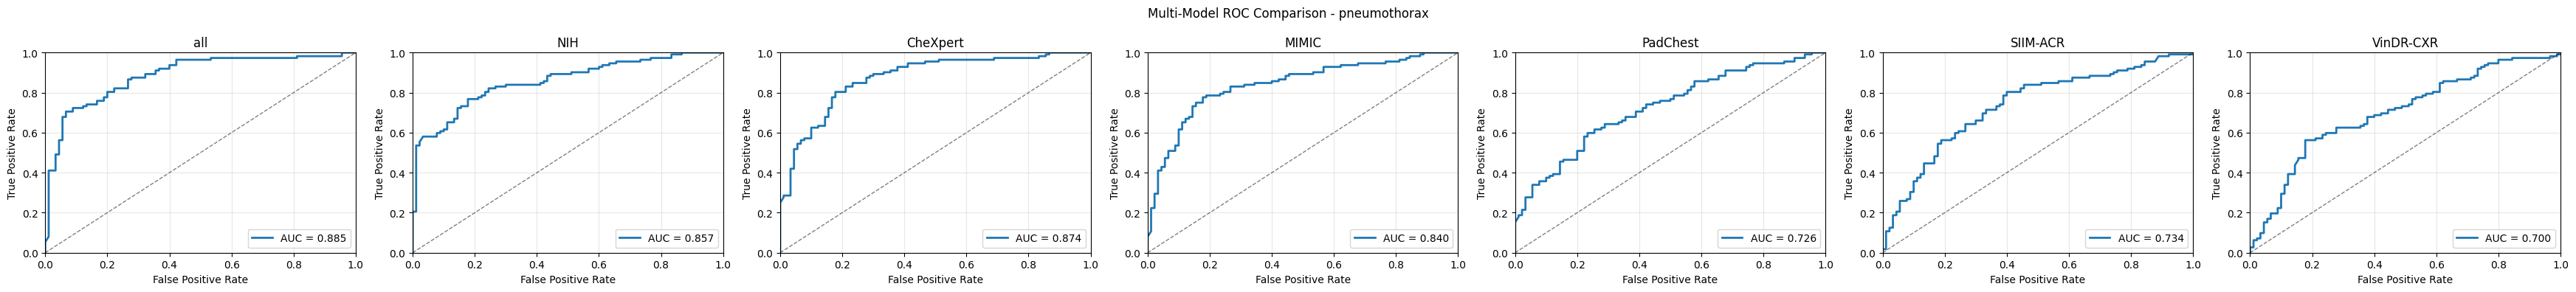

cxr/evaluate.py:2854: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower right")


Saved plot: results/sms_external_validation/multi_model_roc_support_devices.png


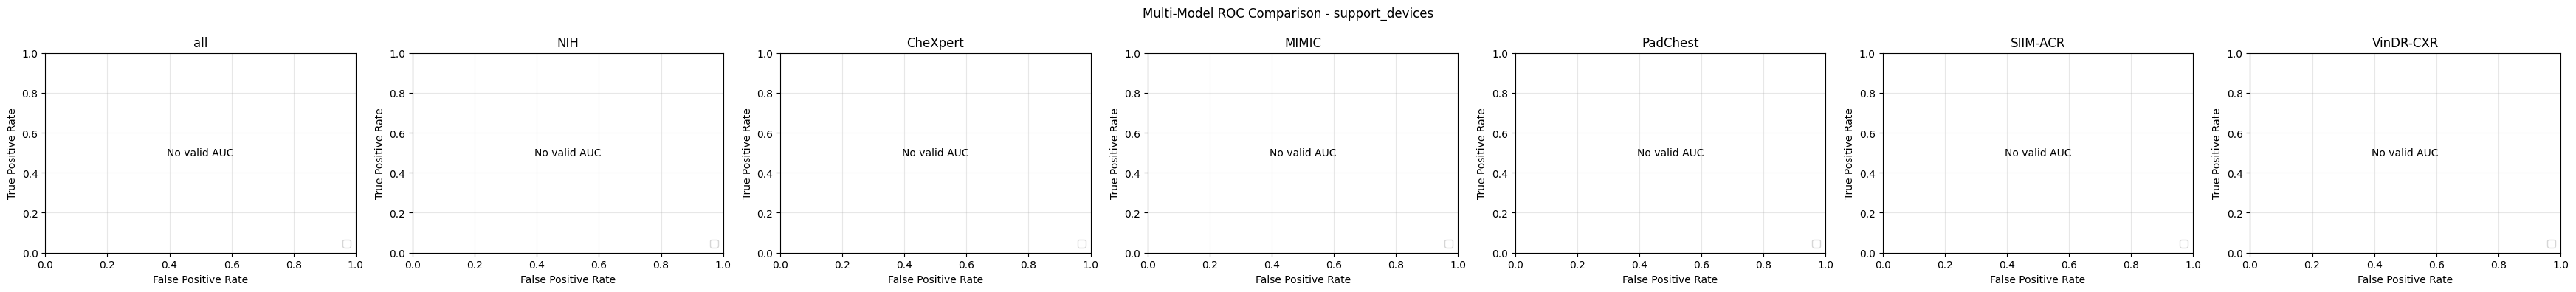

Saved plot: results/sms_external_validation/multi_model_roc_no_finding.png


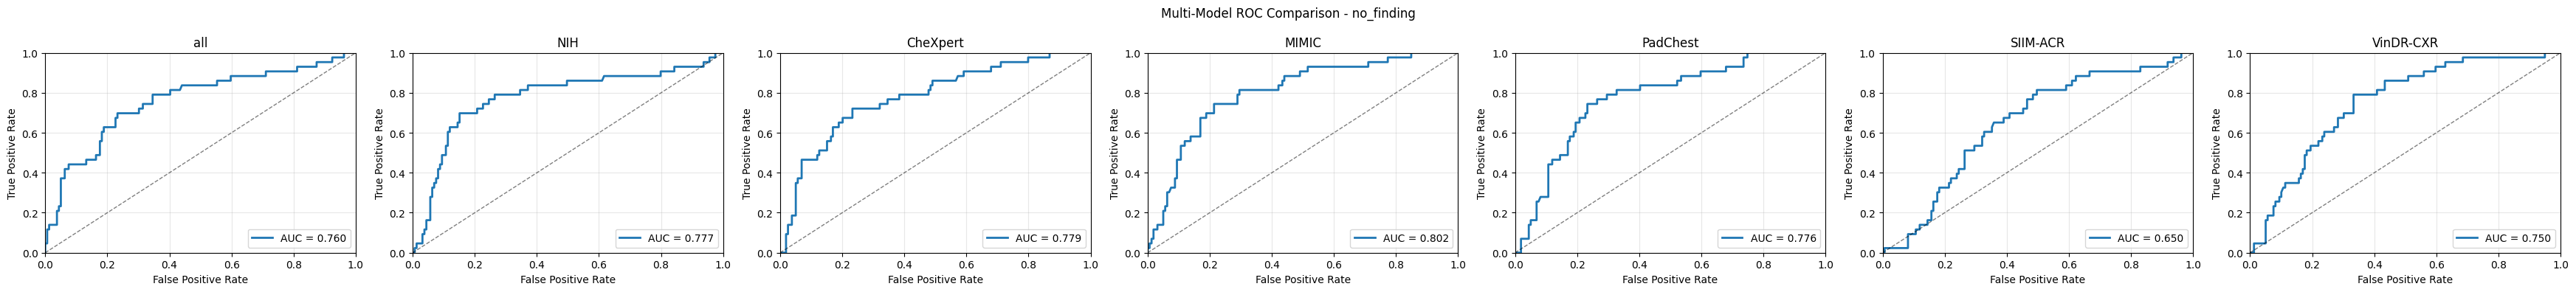

📈 Plotting Multi-Model PR Curves...
Saved plot: results/sms_external_validation/multi_model_pr_pneumothorax.png


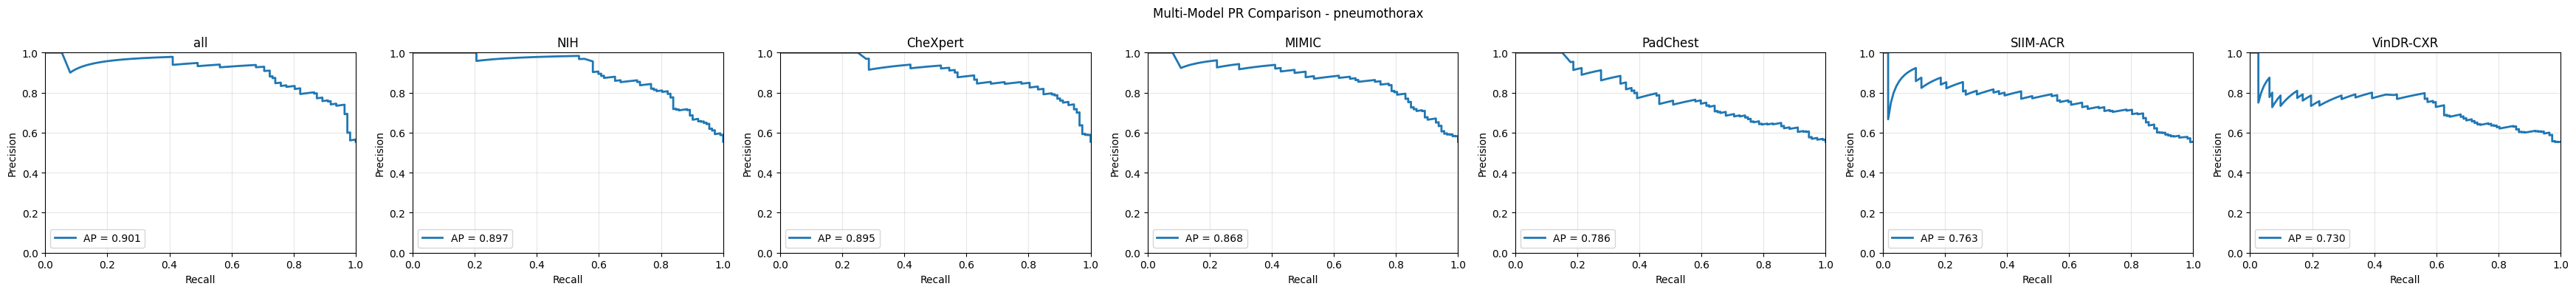

Saved plot: results/sms_external_validation/multi_model_pr_support_devices.png


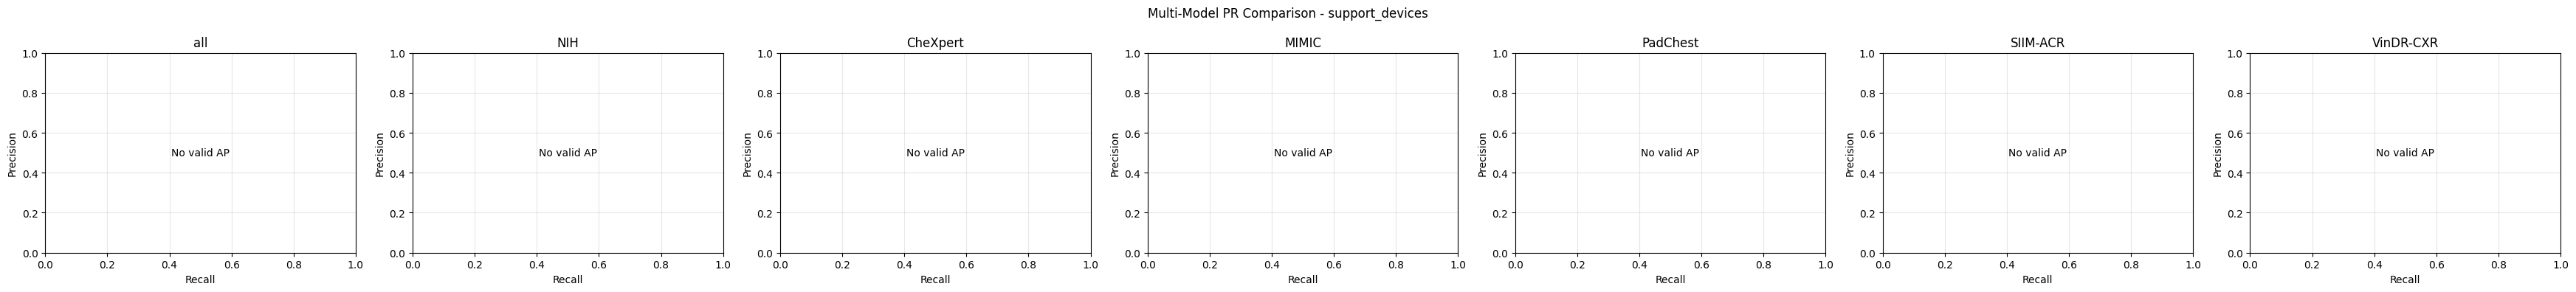

Saved plot: results/sms_external_validation/multi_model_pr_no_finding.png


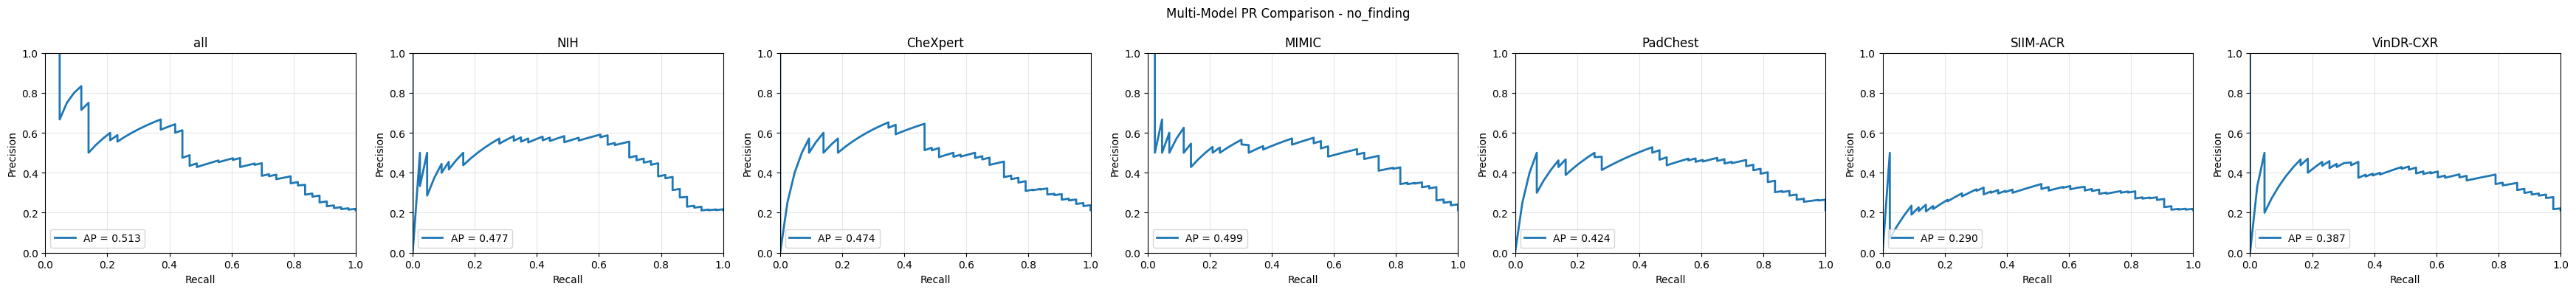

📈 Plotting Multi-Model ROC Curves with Datasets...
Saved plot: results/sms_external_validation/multi_model_roc_with_datasets_pneumothorax.png


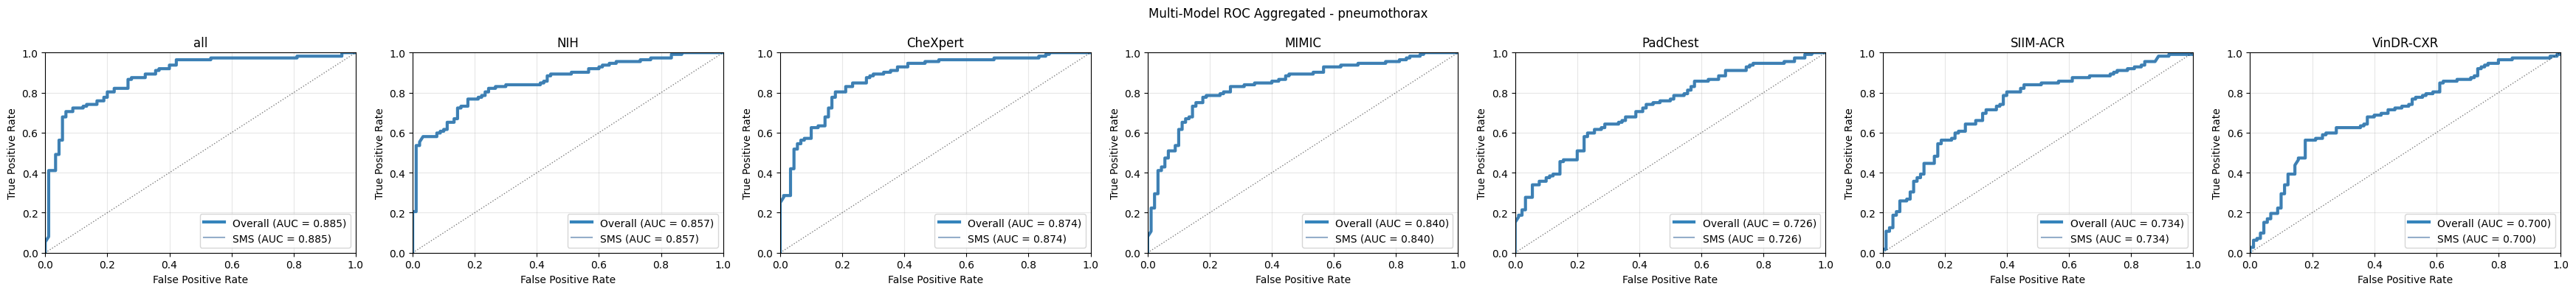

cxr/evaluate.py:3214: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower right")


Saved plot: results/sms_external_validation/multi_model_roc_with_datasets_support_devices.png


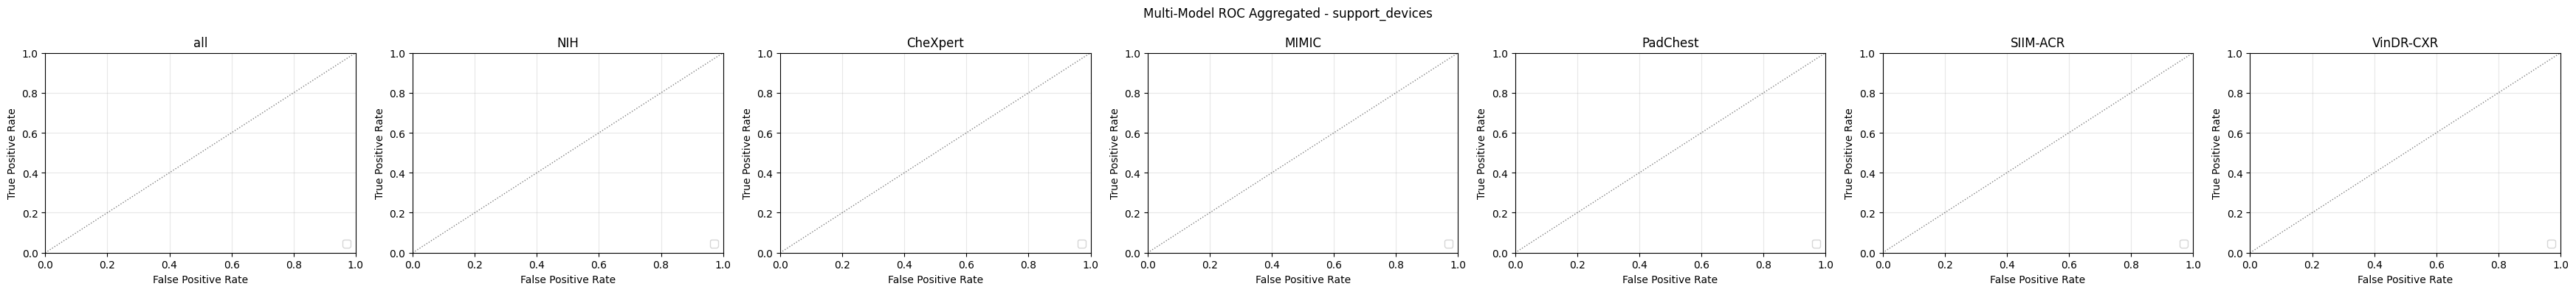

Saved plot: results/sms_external_validation/multi_model_roc_with_datasets_no_finding.png


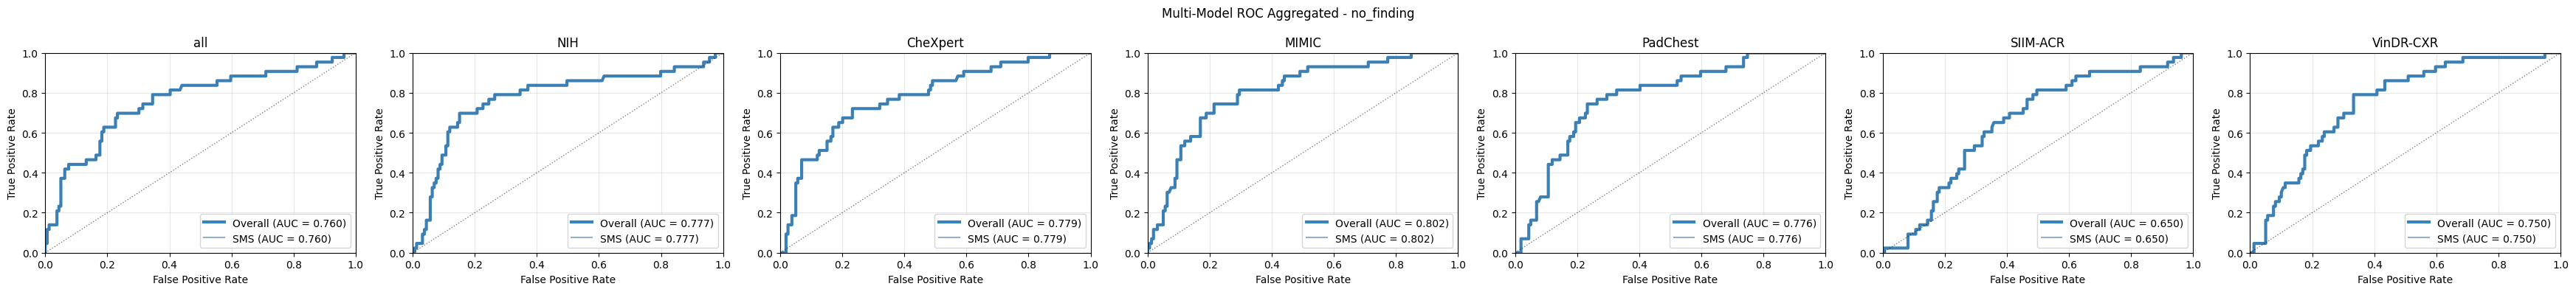

📈 Plotting Multi-Model PR Curves with Datasets...
Saved plot: results/sms_external_validation/multi_model_pr_with_datasets_pneumothorax.png


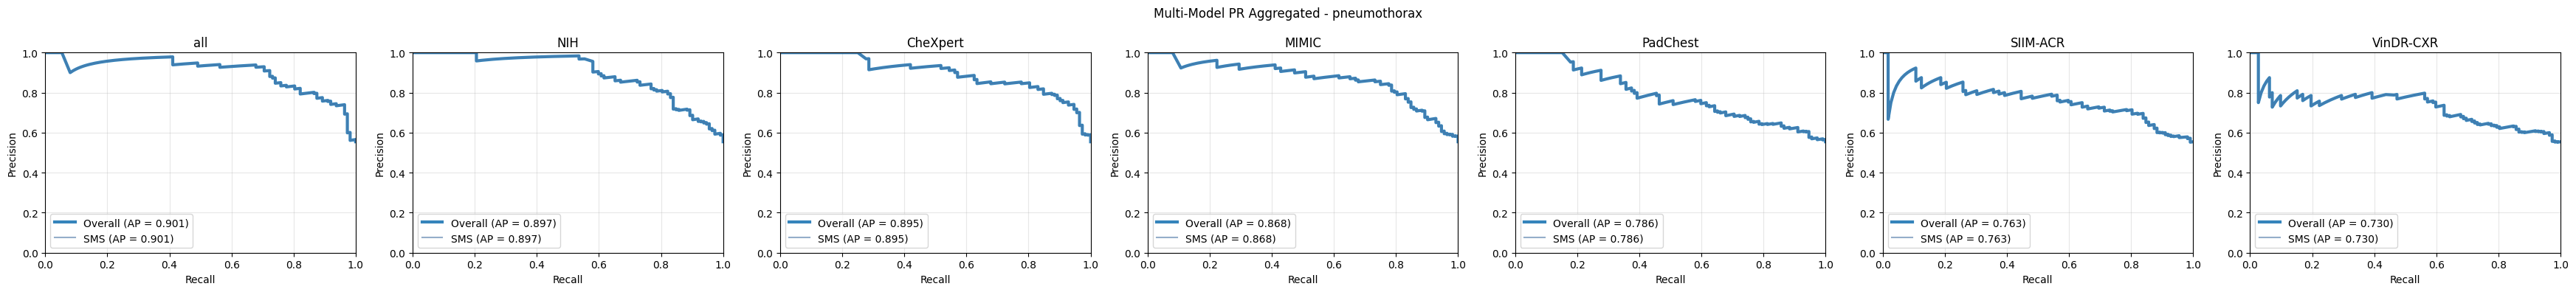

cxr/evaluate.py:3441: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower left")


Saved plot: results/sms_external_validation/multi_model_pr_with_datasets_support_devices.png


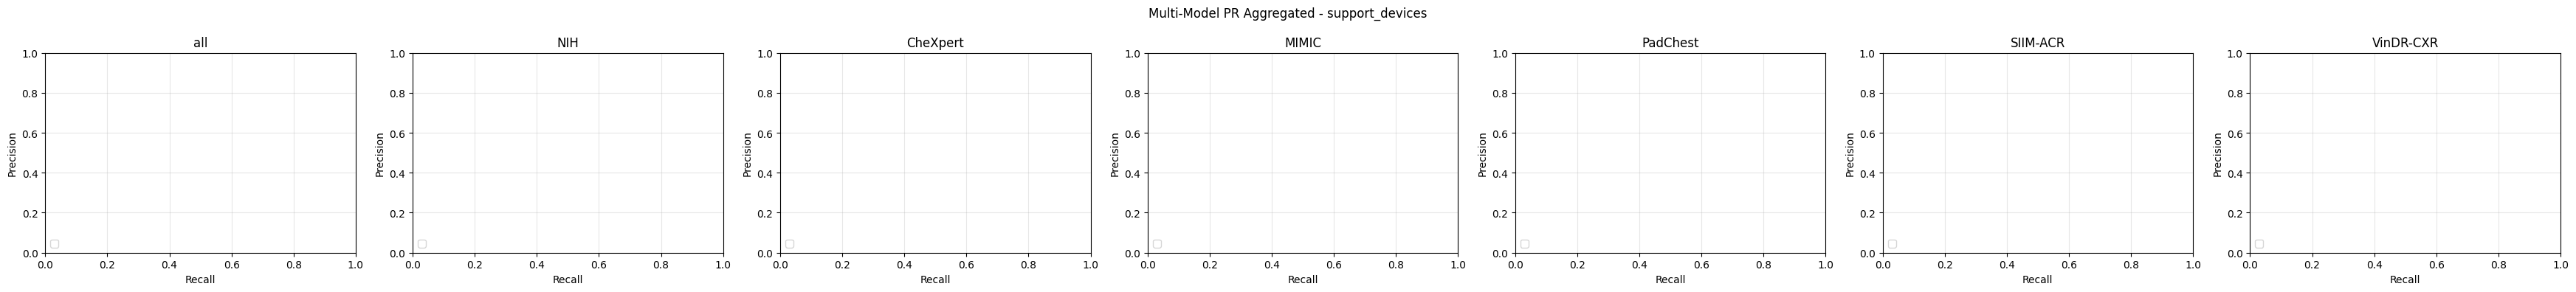

Saved plot: results/sms_external_validation/multi_model_pr_with_datasets_no_finding.png


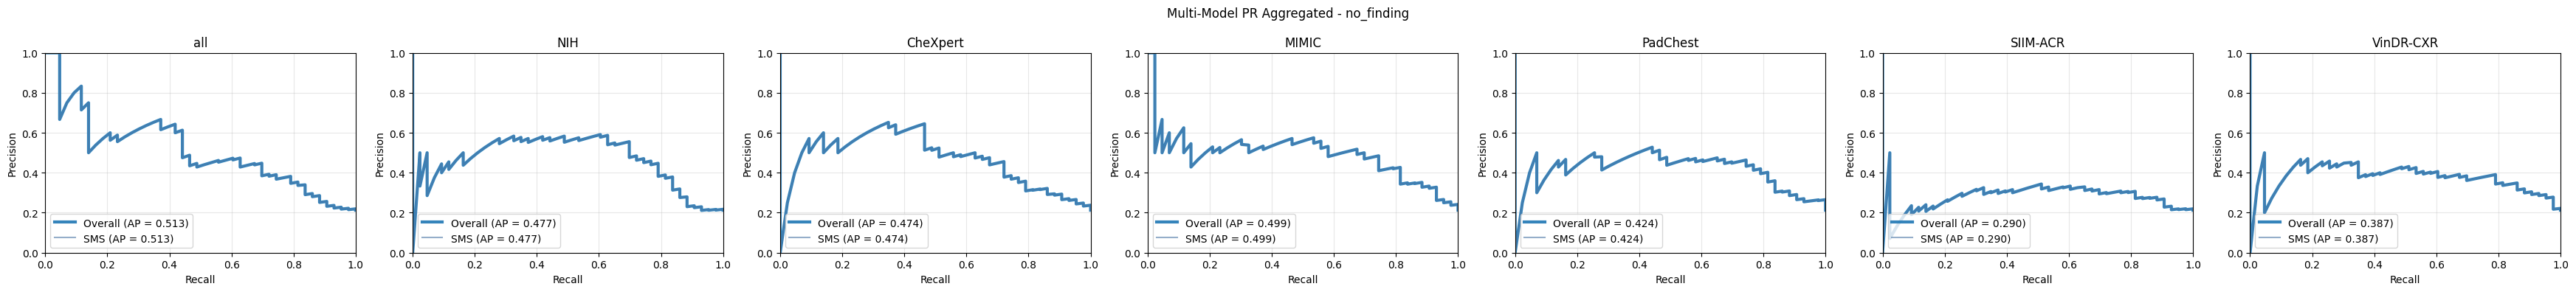

📊 Plotting Multi-Model Comparison - Sensitivity (Recall)...
Saved plot: results/sms_external_validation/multi_model_comparison_Sensitivity_Recall_pneumothorax.png


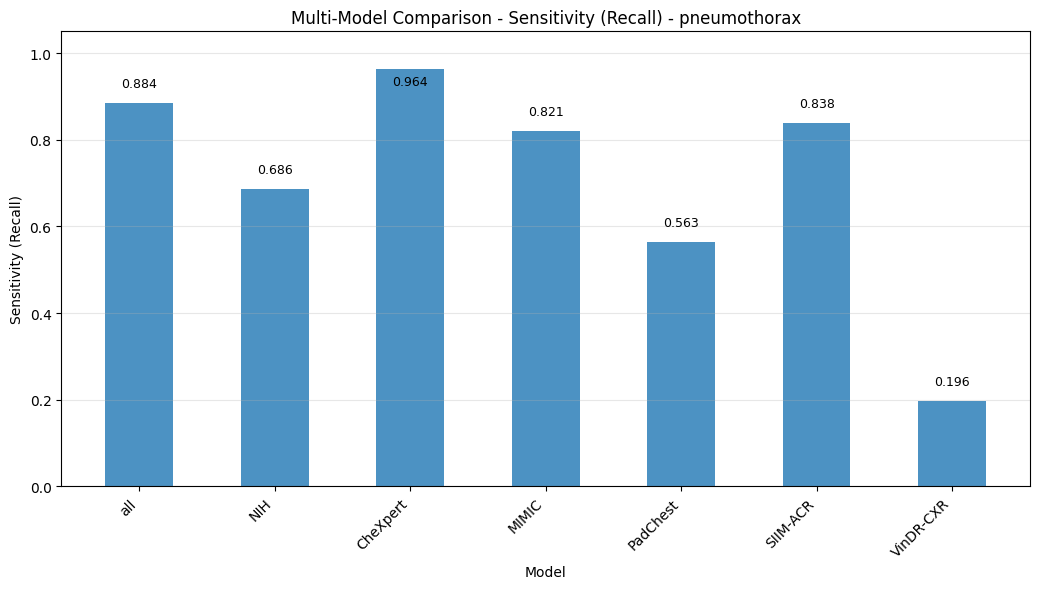

Saved plot: results/sms_external_validation/multi_model_comparison_Sensitivity_Recall_support_devices.png


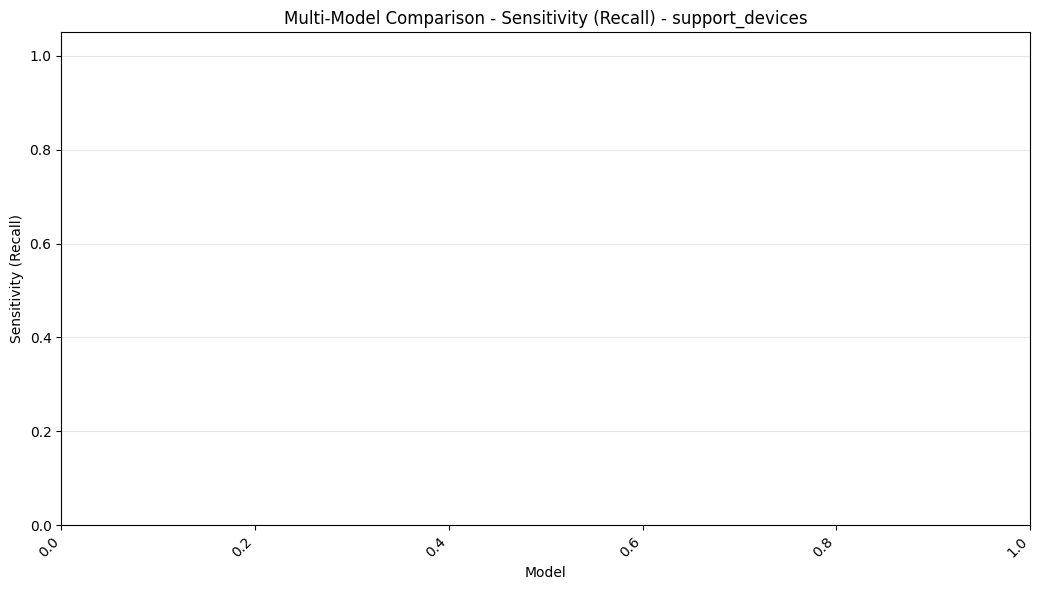

Saved plot: results/sms_external_validation/multi_model_comparison_Sensitivity_Recall_no_finding.png


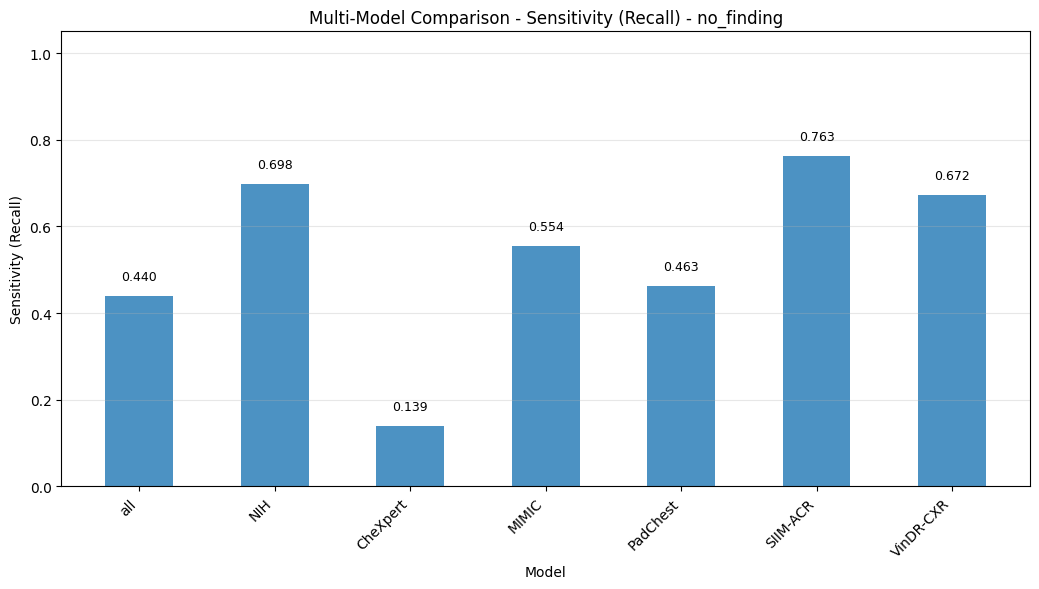

📊 Plotting Multi-Model Comparison - Specificity...
Saved plot: results/sms_external_validation/multi_model_comparison_Specificity_pneumothorax.png


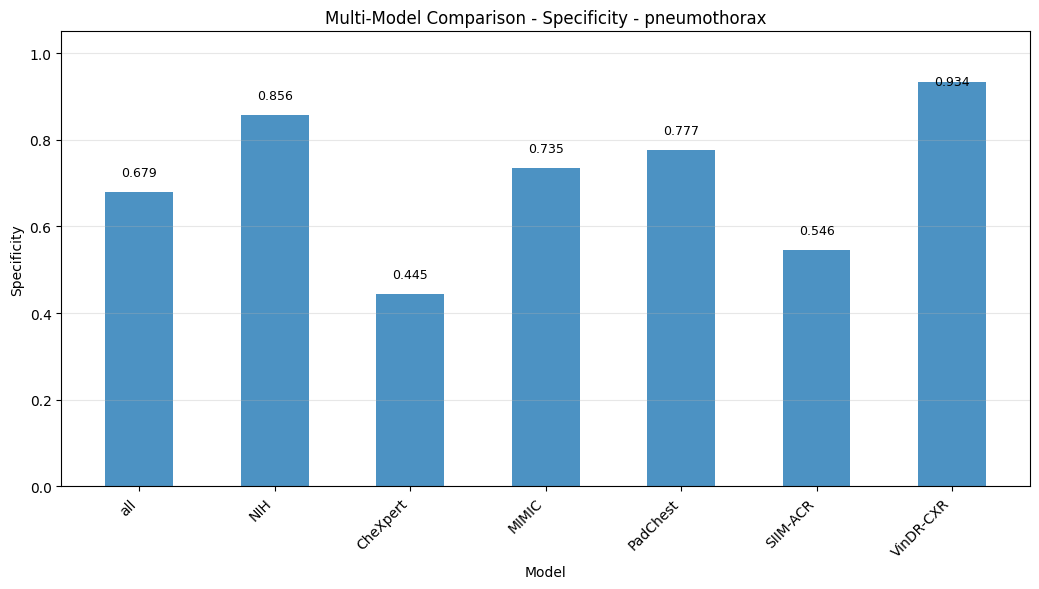

Saved plot: results/sms_external_validation/multi_model_comparison_Specificity_support_devices.png


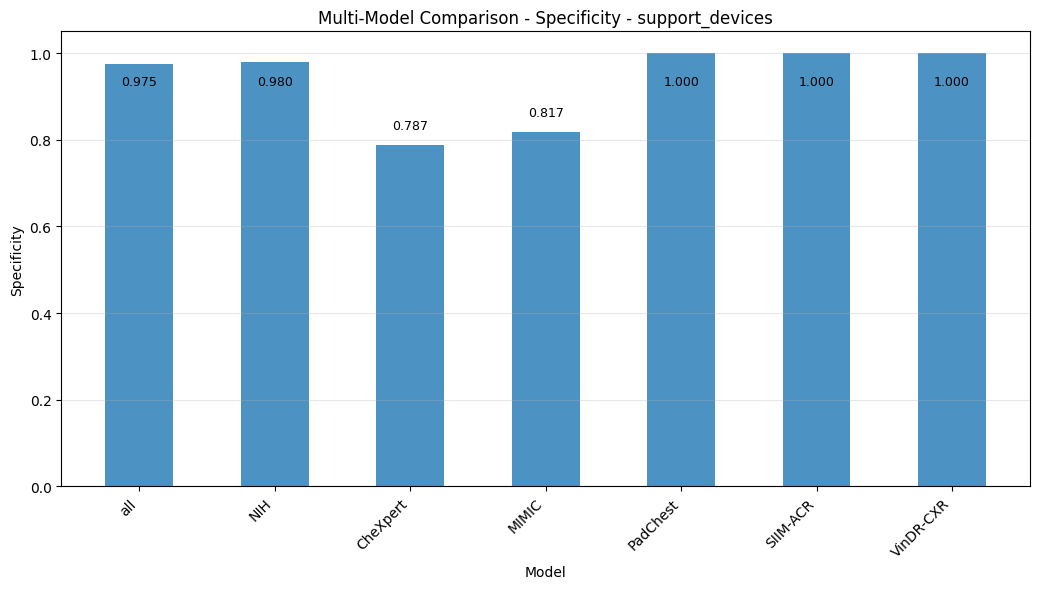

Saved plot: results/sms_external_validation/multi_model_comparison_Specificity_no_finding.png


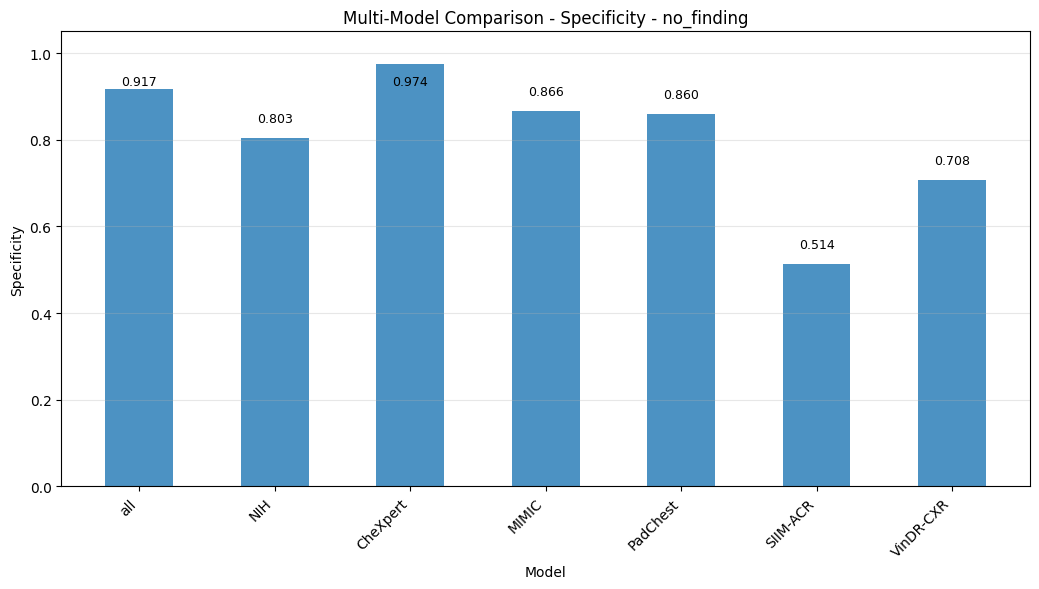

📊 Plotting Multi-Model Comparison - PPV (Precision)...
Saved plot: results/sms_external_validation/multi_model_comparison_PPV_Precision_pneumothorax.png


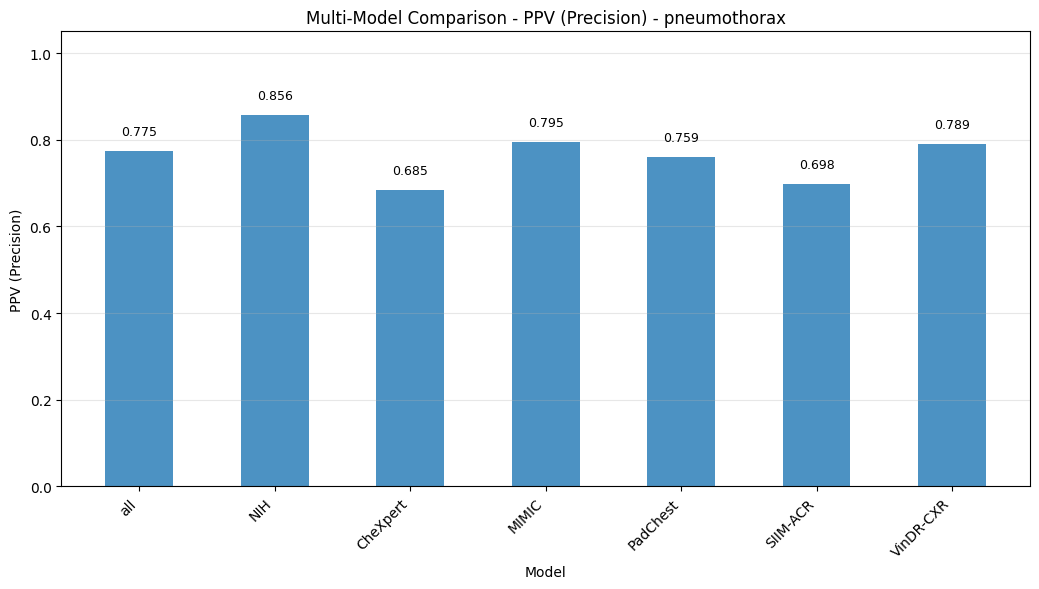

Saved plot: results/sms_external_validation/multi_model_comparison_PPV_Precision_support_devices.png


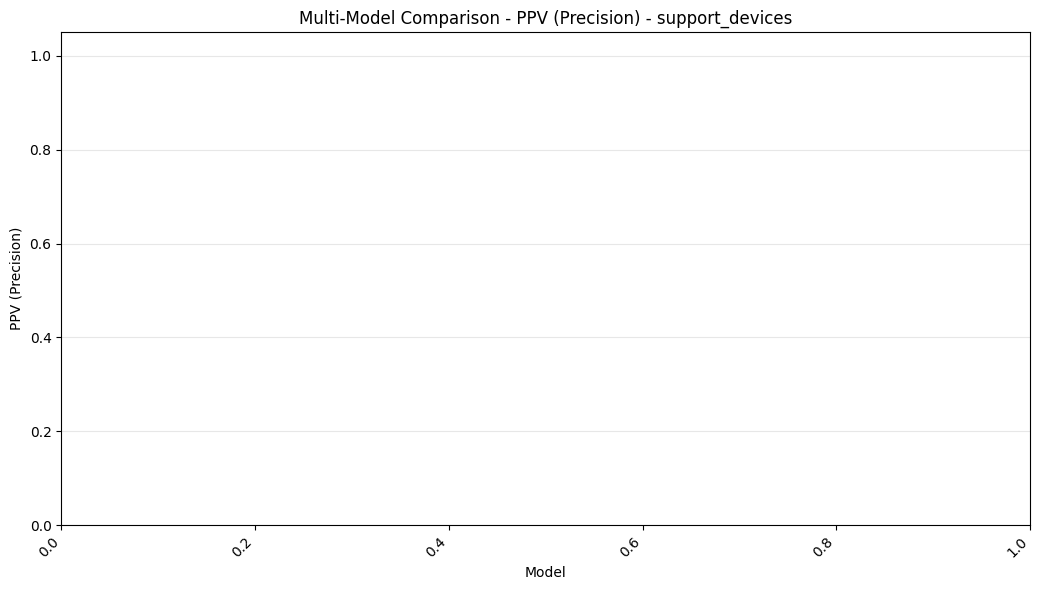

Saved plot: results/sms_external_validation/multi_model_comparison_PPV_Precision_no_finding.png


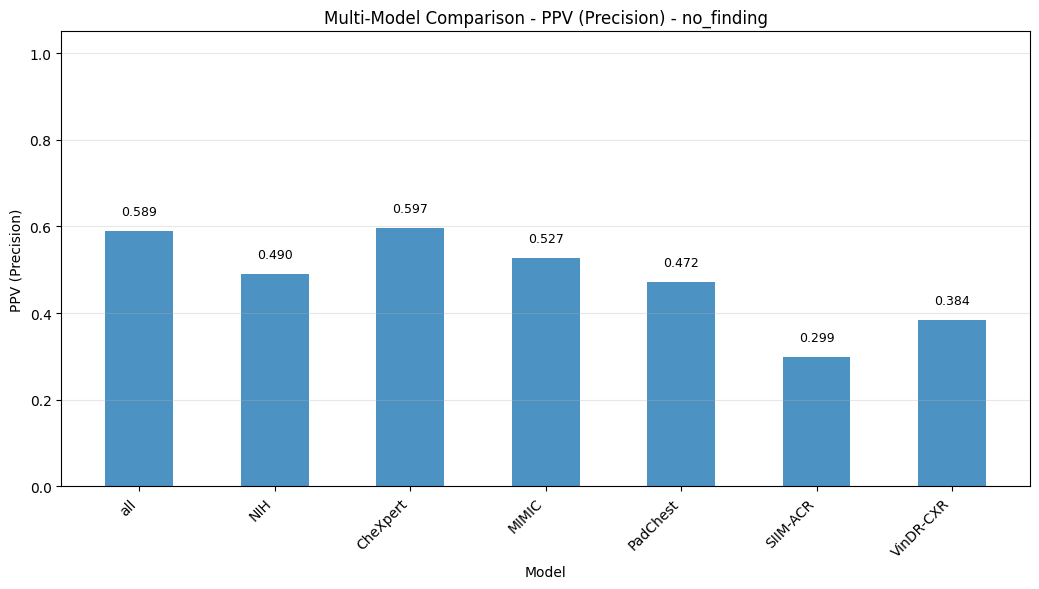

📊 Plotting Multi-Model Comparison - NPV...
Saved plot: results/sms_external_validation/multi_model_comparison_NPV_pneumothorax.png


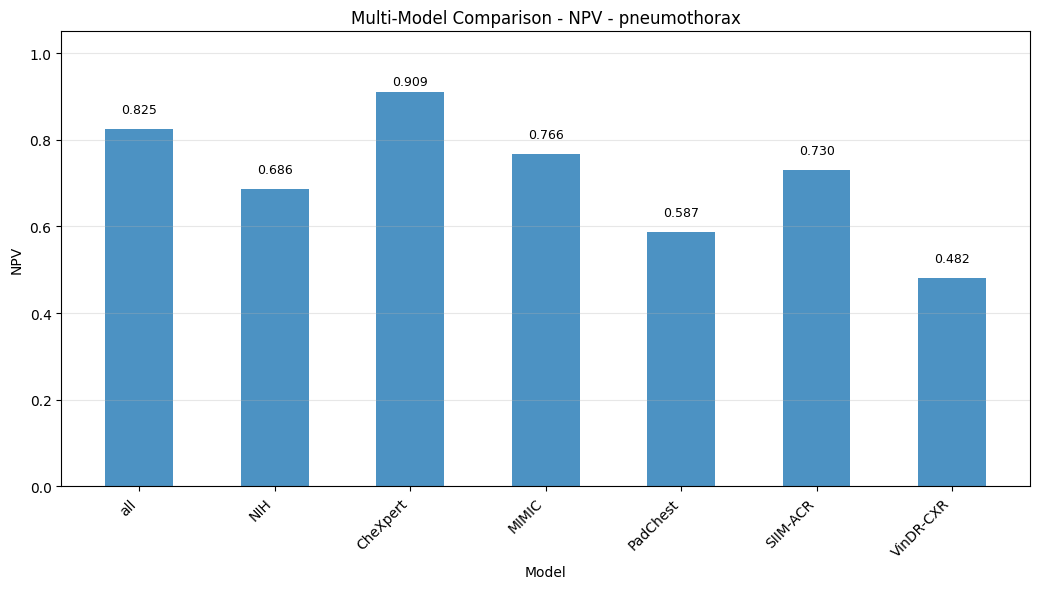

Saved plot: results/sms_external_validation/multi_model_comparison_NPV_support_devices.png


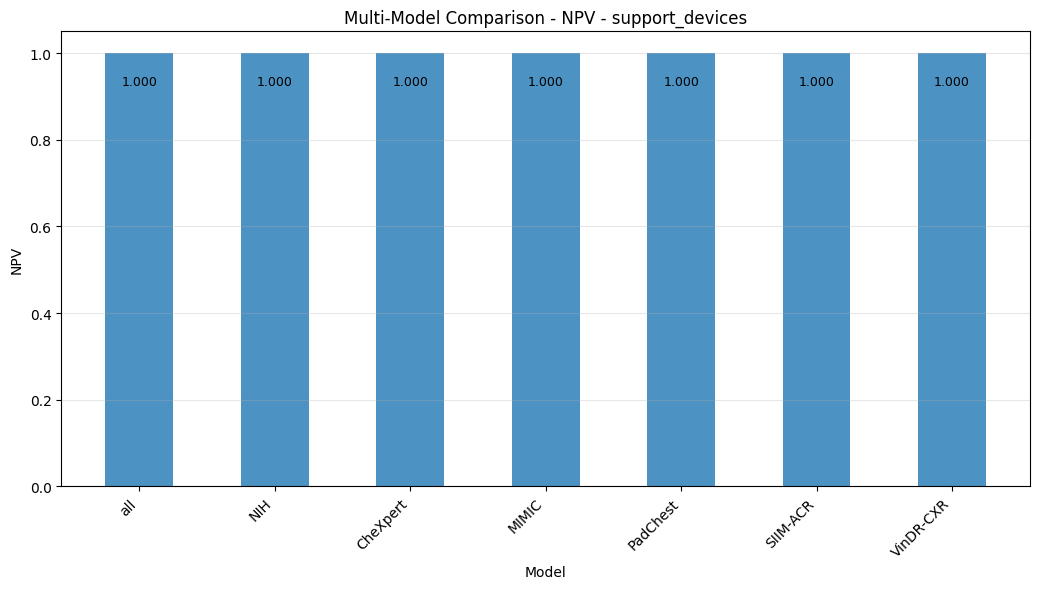

Saved plot: results/sms_external_validation/multi_model_comparison_NPV_no_finding.png


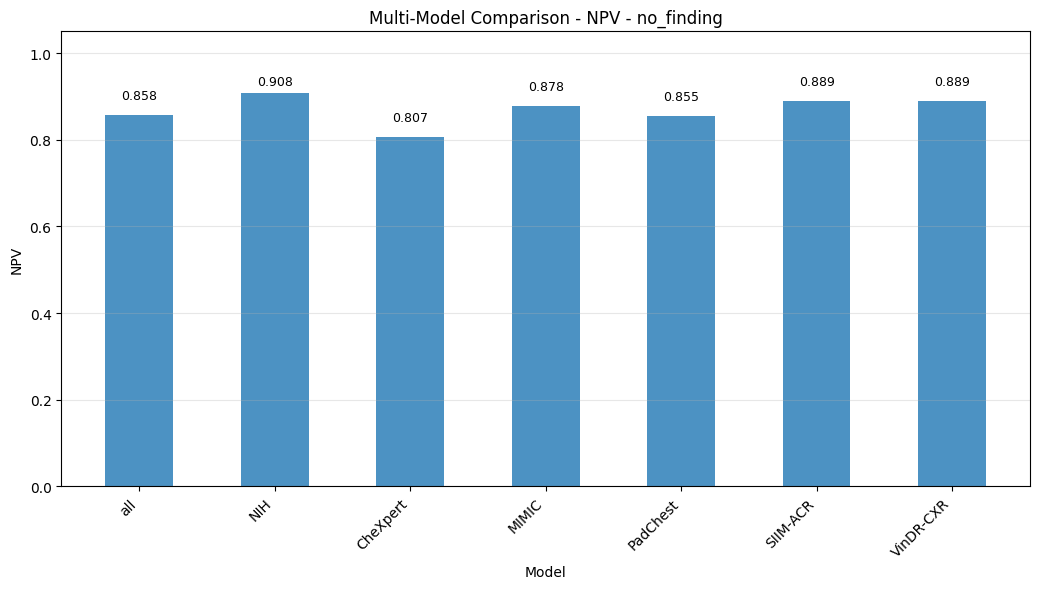

📊 Plotting Multi-Model Comparison - F1-score...
Saved plot: results/sms_external_validation/multi_model_comparison_F1-score_pneumothorax.png


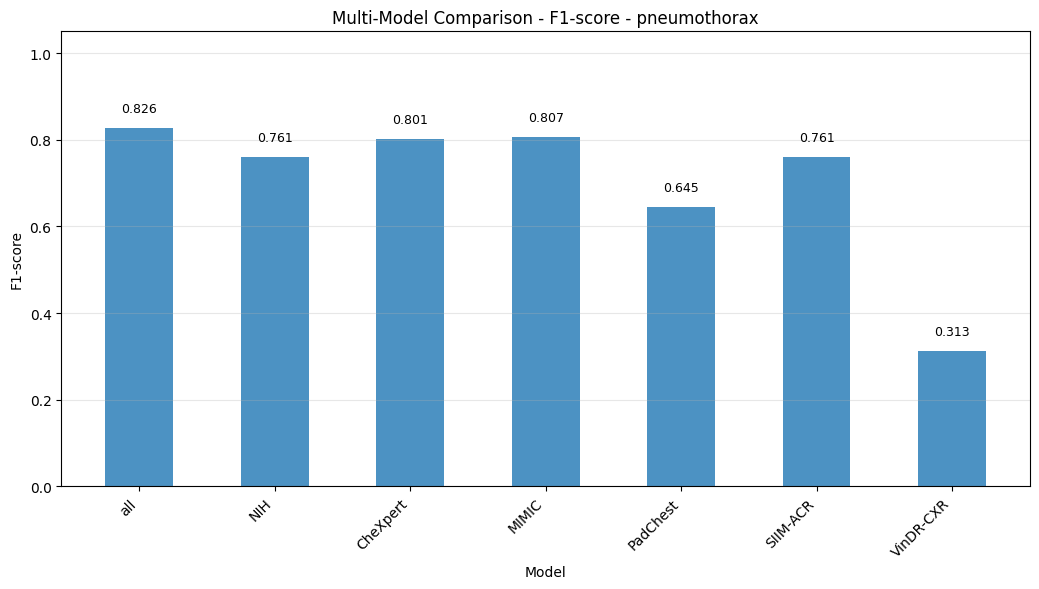

Saved plot: results/sms_external_validation/multi_model_comparison_F1-score_support_devices.png


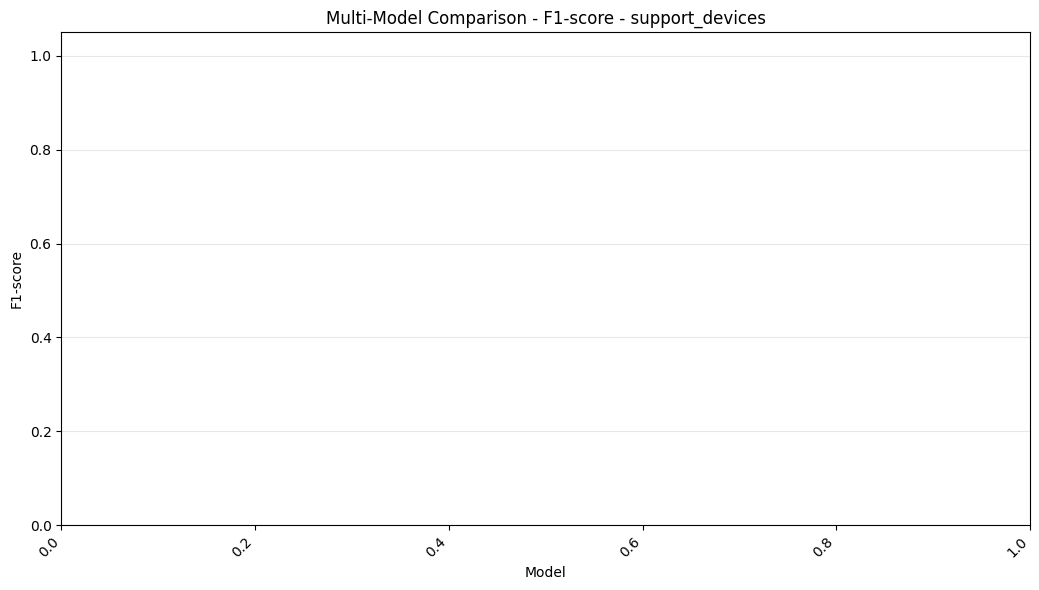

Saved plot: results/sms_external_validation/multi_model_comparison_F1-score_no_finding.png


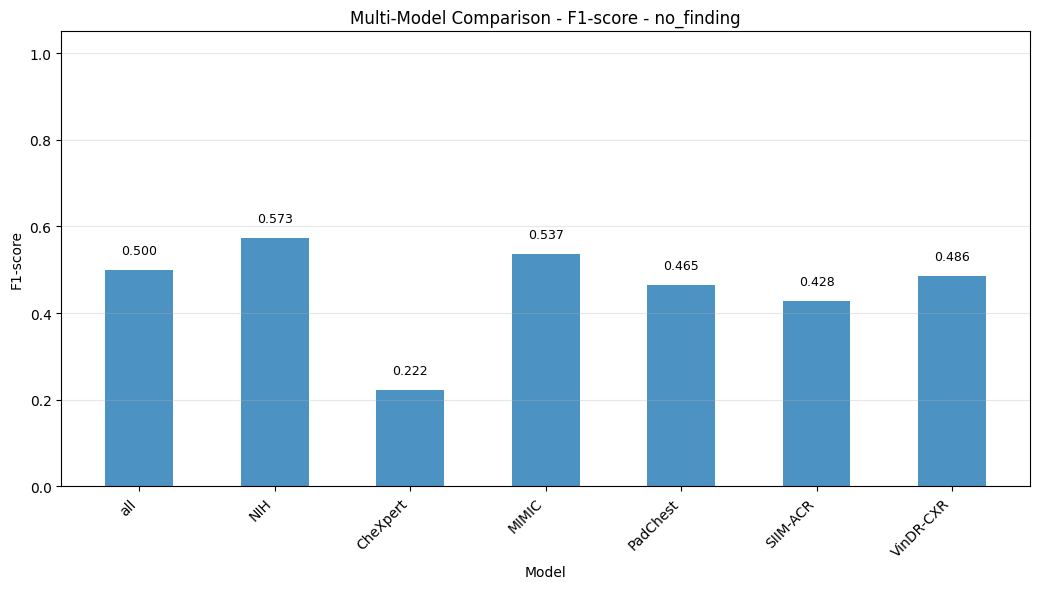

📊 Plotting Multi-Model Comparison - AUC...
Saved plot: results/sms_external_validation/multi_model_comparison_AUC_pneumothorax.png


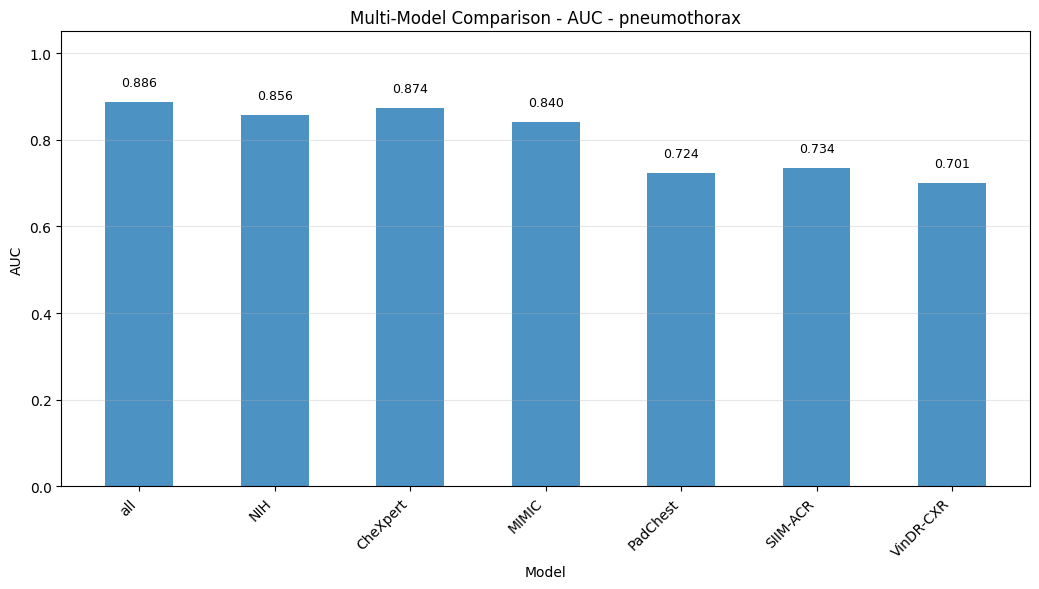

Saved plot: results/sms_external_validation/multi_model_comparison_AUC_support_devices.png


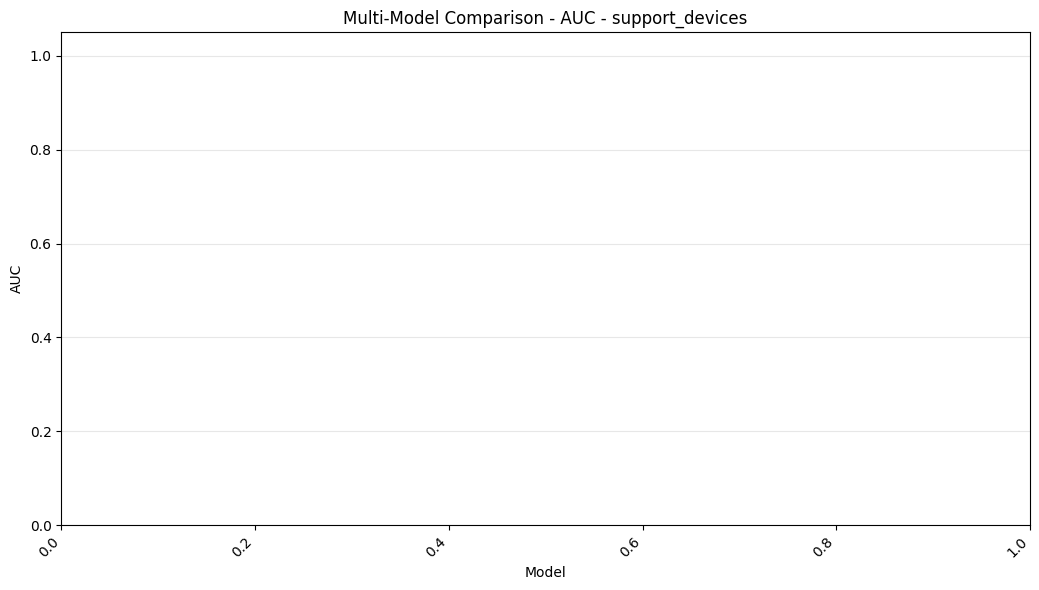

Saved plot: results/sms_external_validation/multi_model_comparison_AUC_no_finding.png


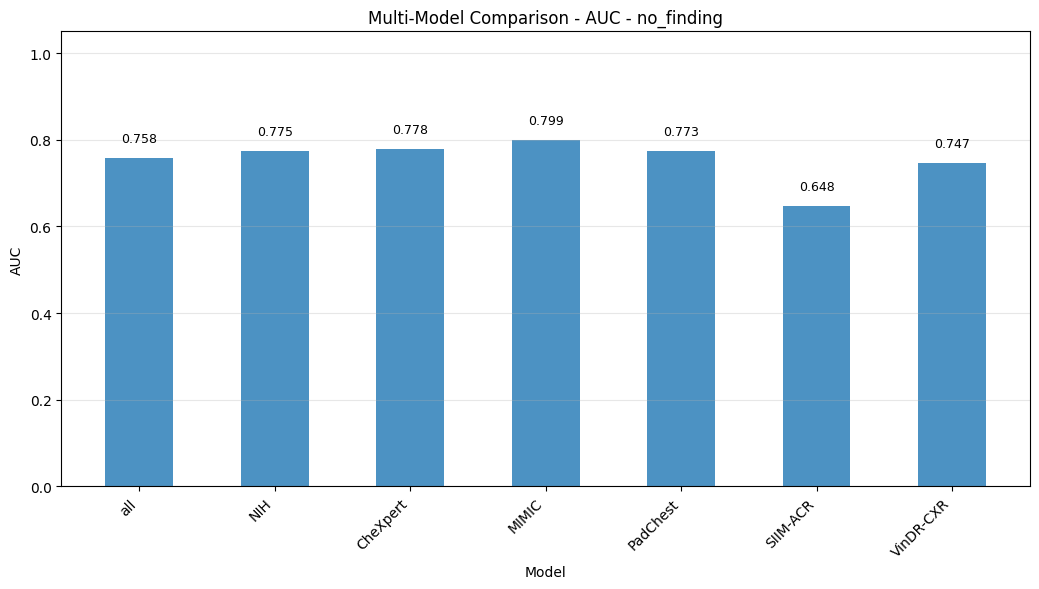

📊 Plotting Multi-Model Comparison - AP...
Saved plot: results/sms_external_validation/multi_model_comparison_AP_pneumothorax.png


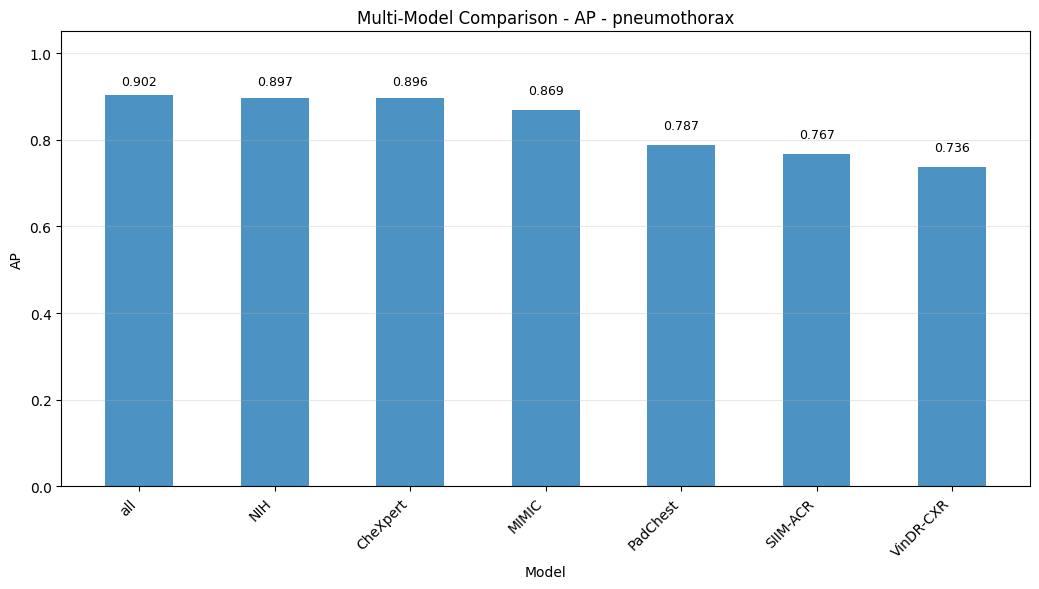

Saved plot: results/sms_external_validation/multi_model_comparison_AP_support_devices.png


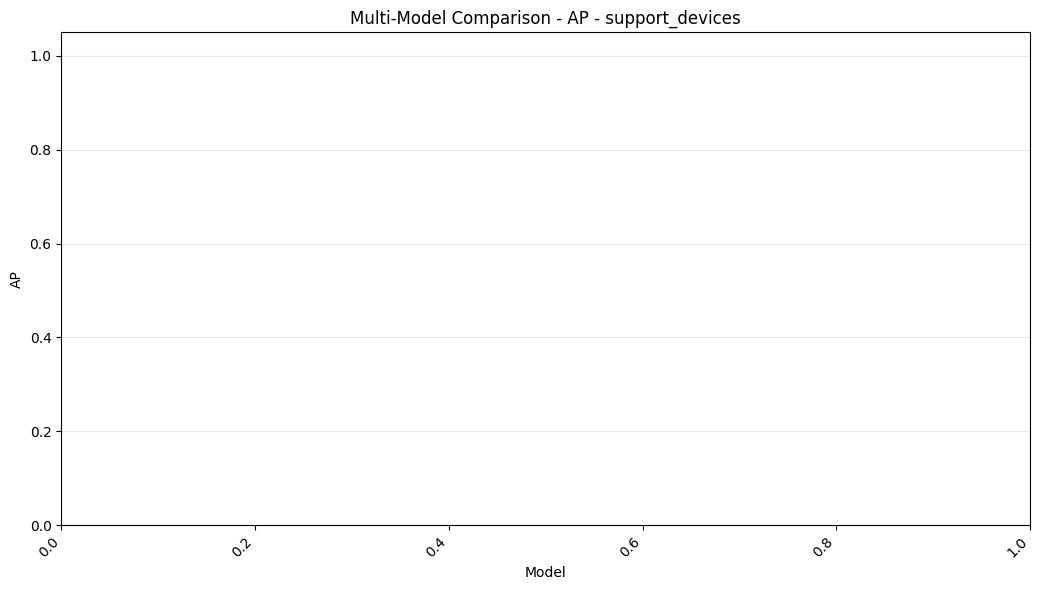

Saved plot: results/sms_external_validation/multi_model_comparison_AP_no_finding.png


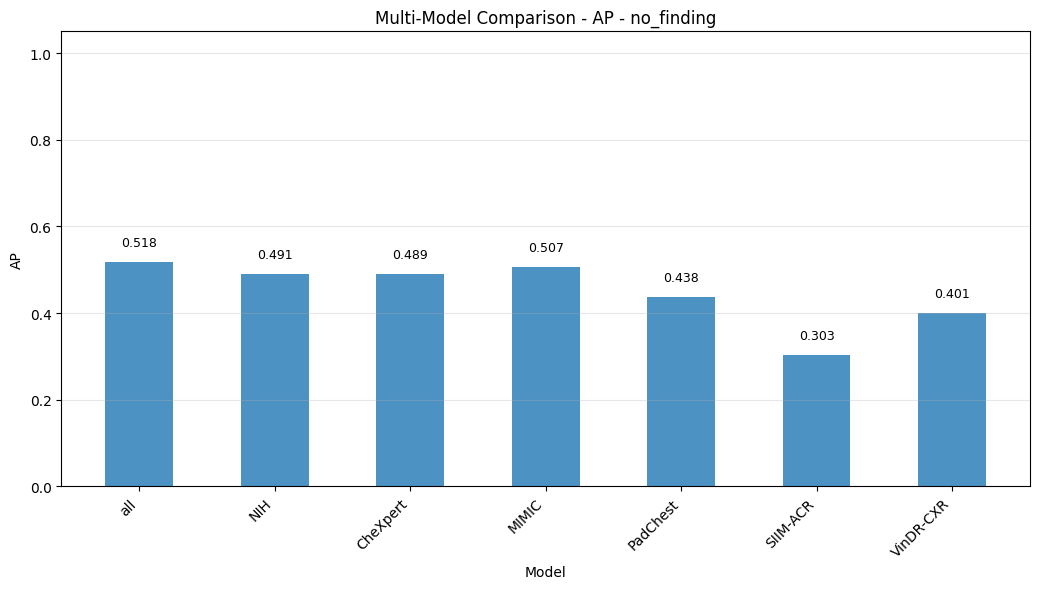

📊 Plotting Multi-Model Comprehensive Comparison...
Saved plot: results/sms_external_validation/multi_model_comprehensive_pneumothorax.png


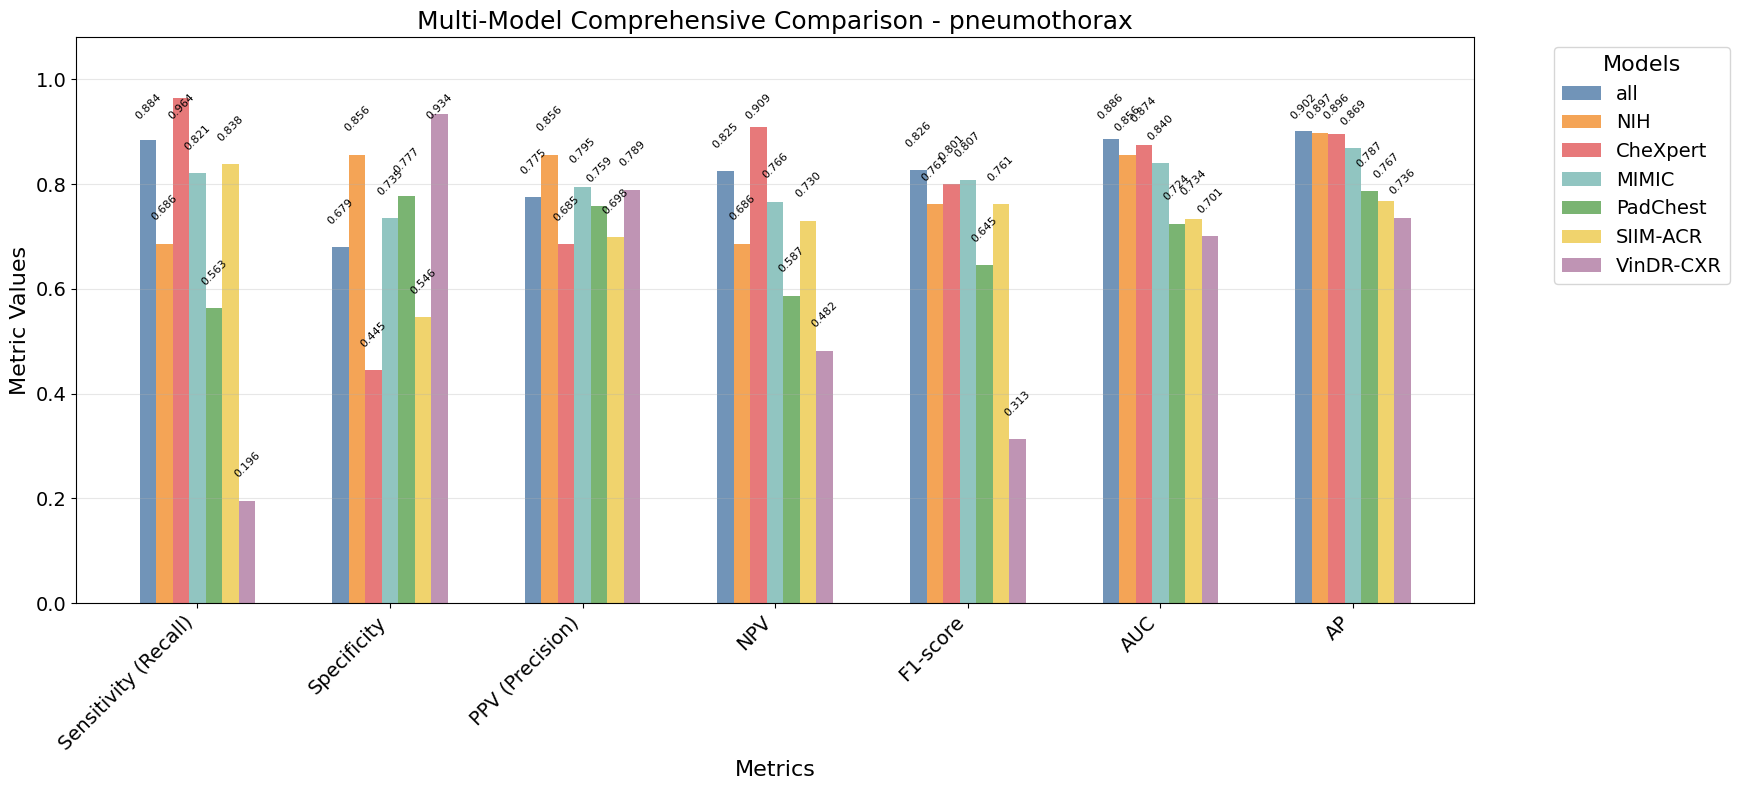

Saved plot: results/sms_external_validation/multi_model_comprehensive_support_devices.png


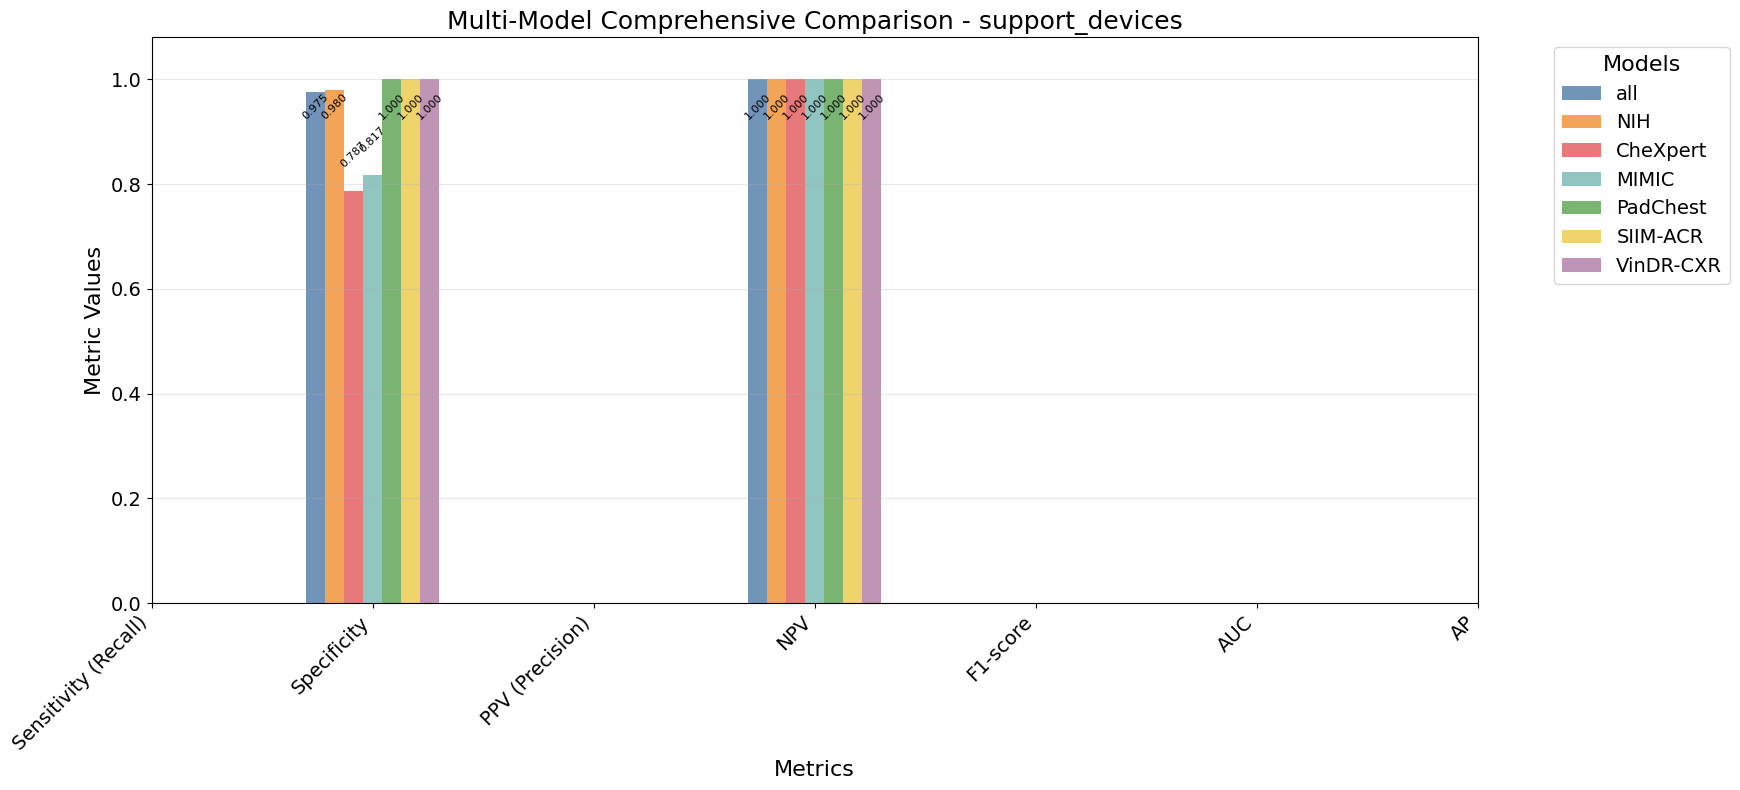

Saved plot: results/sms_external_validation/multi_model_comprehensive_no_finding.png


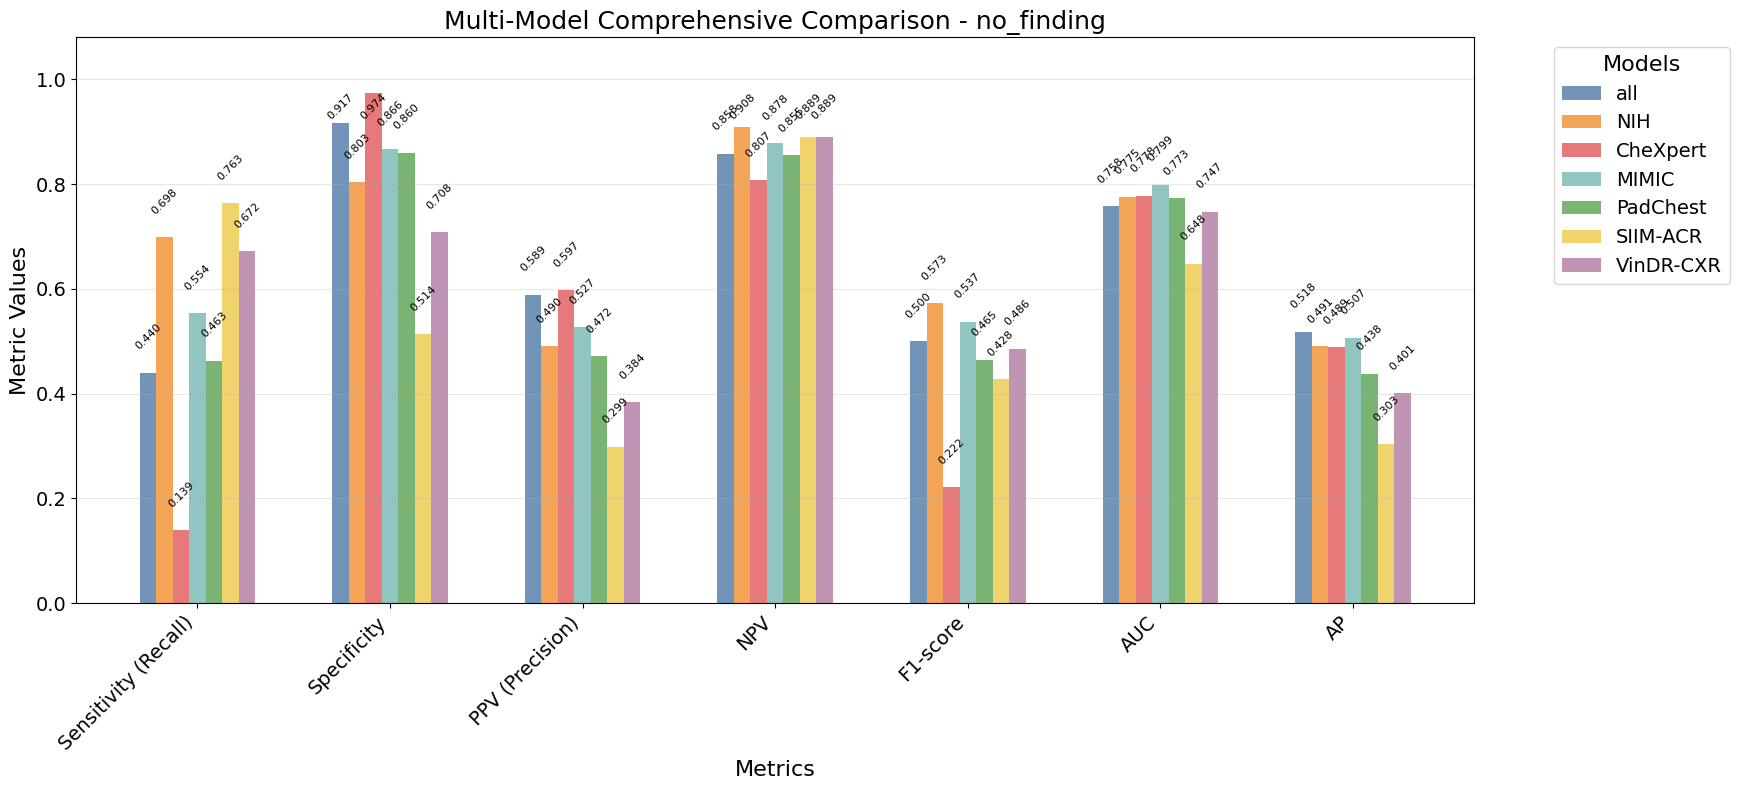

📊 Plotting Multi-Model Confusion Matrices...
Saved plot: results/sms_external_validation/multi_model_confusion_matrices_pneumothorax.png


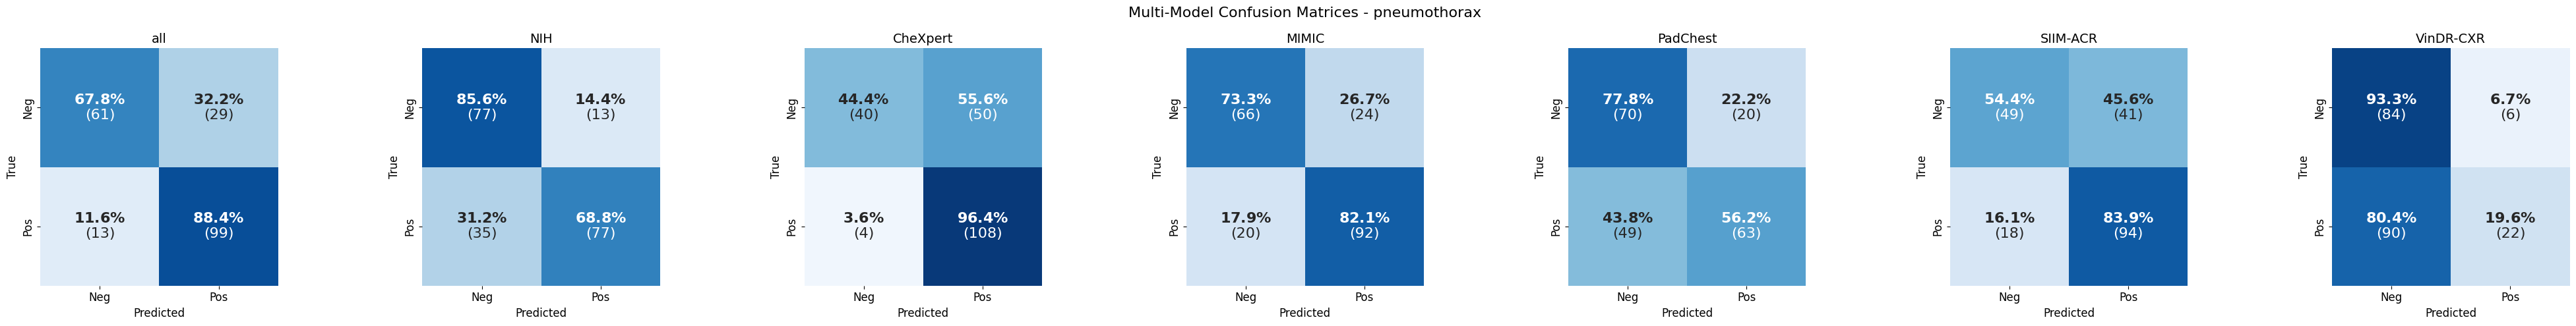

Saved plot: results/sms_external_validation/multi_model_confusion_matrices_support_devices.png


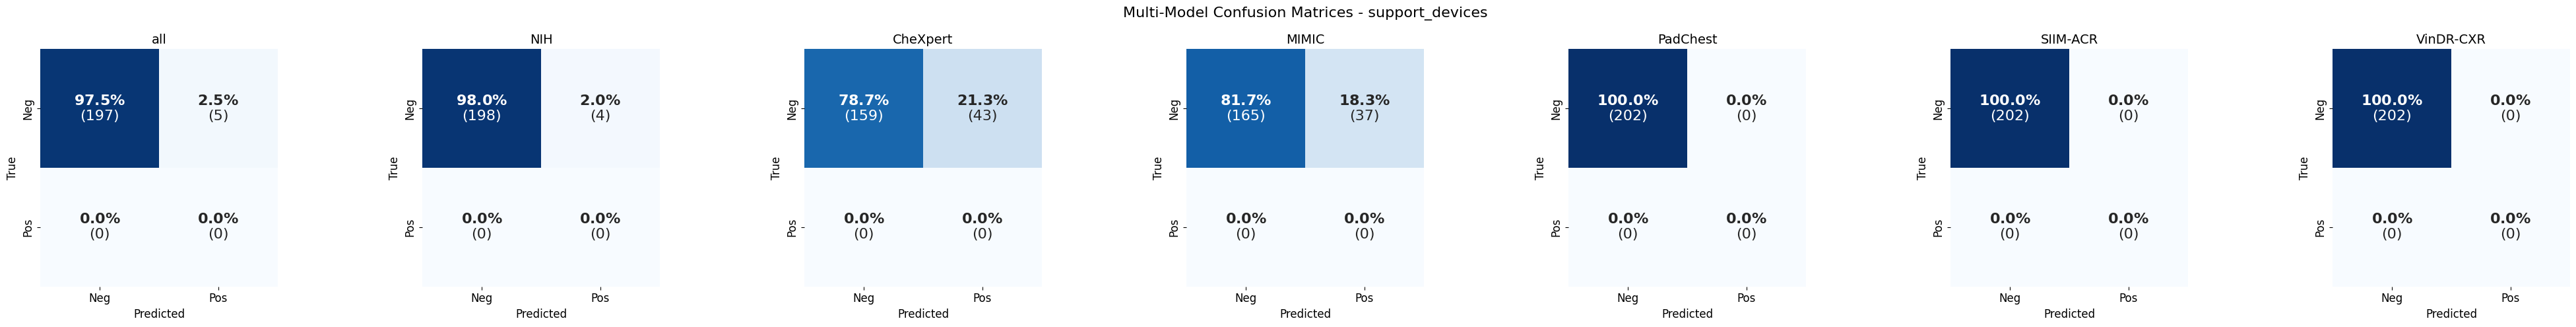

Saved plot: results/sms_external_validation/multi_model_confusion_matrices_no_finding.png


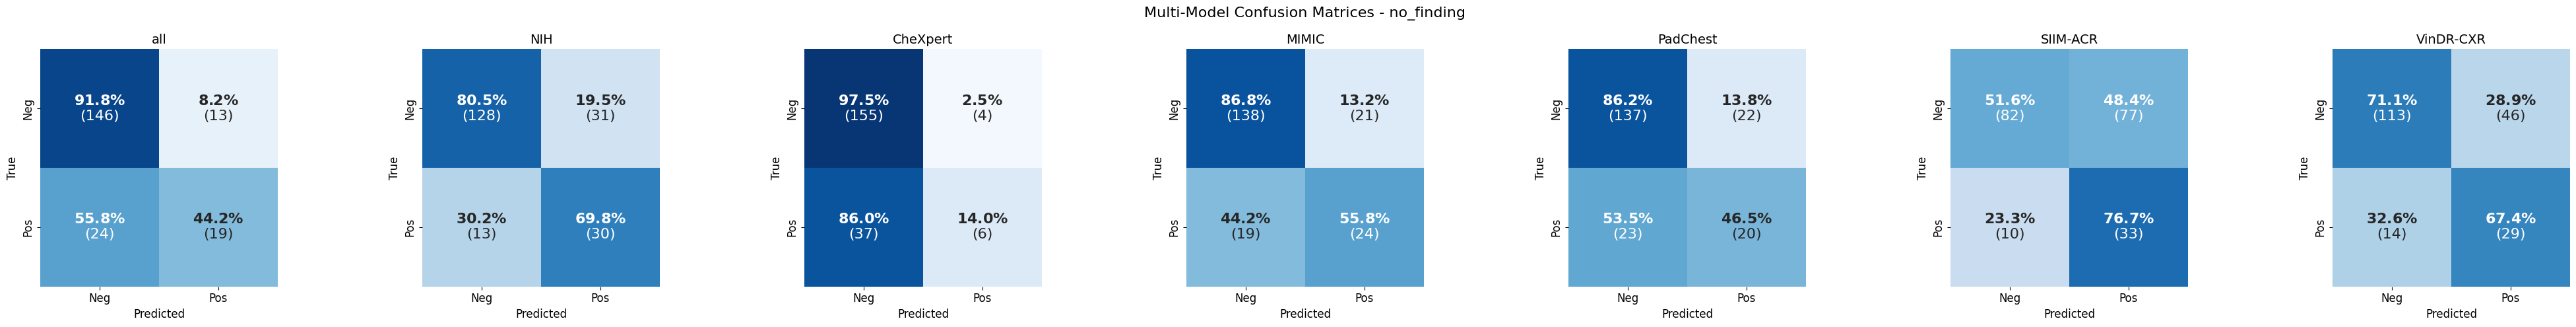

📊 Plotting Multi-Model Dataset Confusion Matrices...


cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/sms_external_validation/multi_model_dataset_confusion_matrices_pneumothorax.png


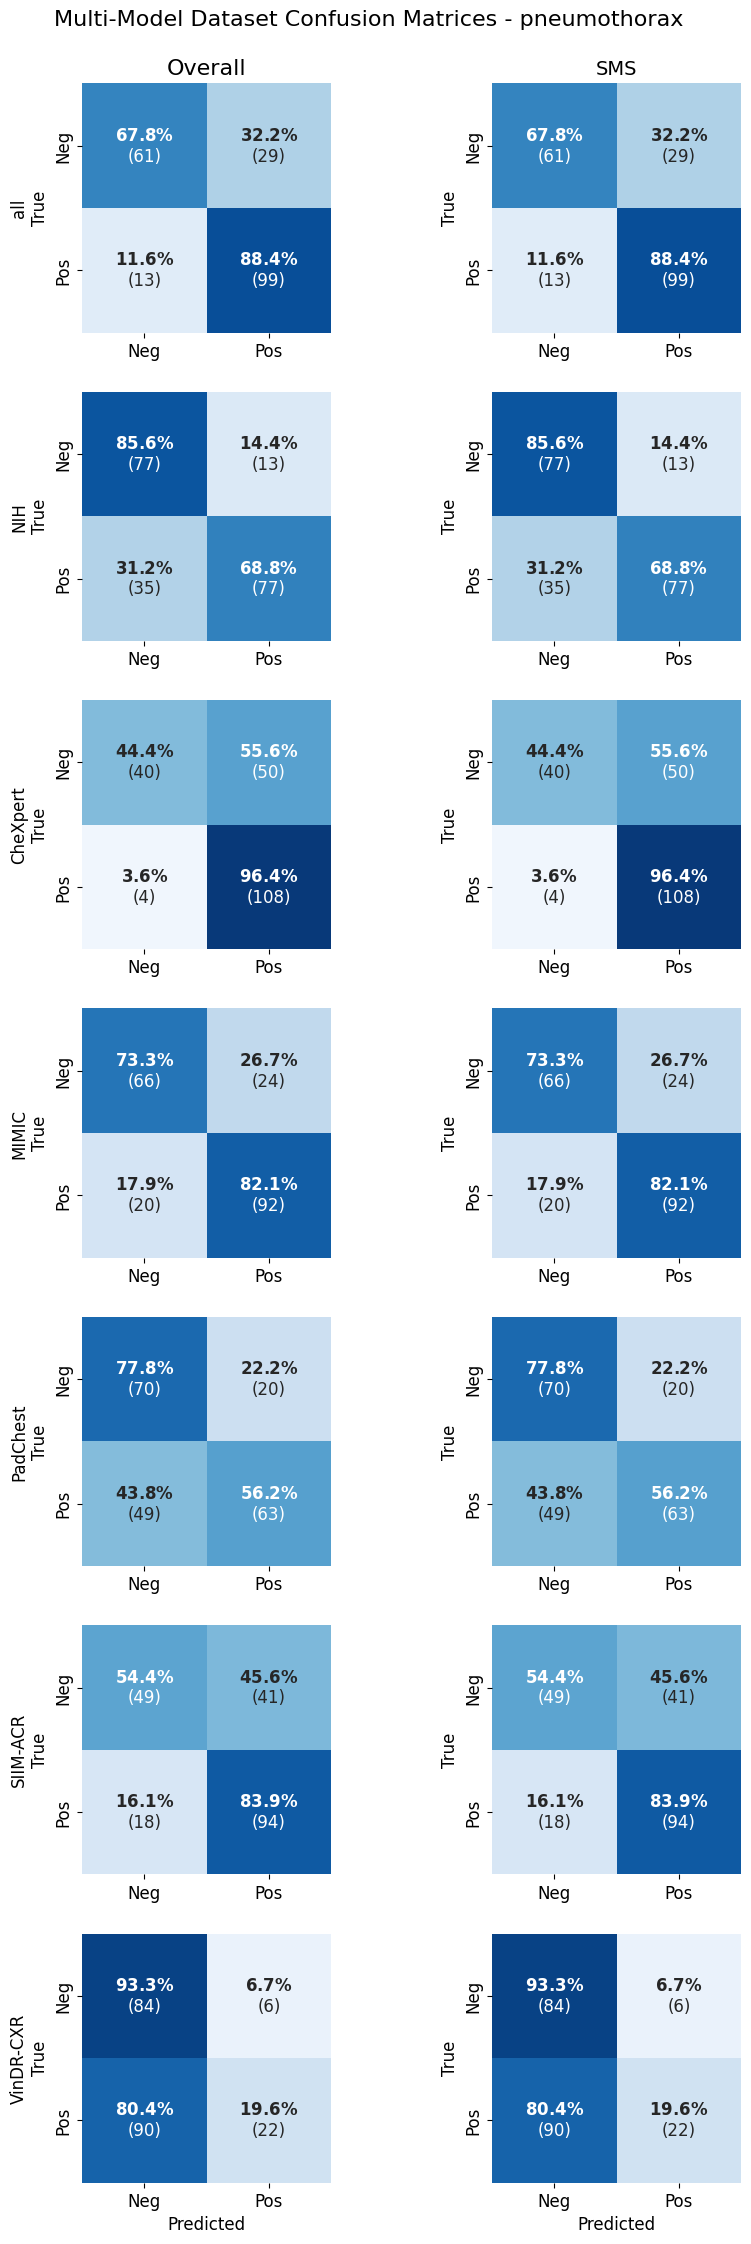

cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/sms_external_validation/multi_model_dataset_confusion_matrices_support_devices.png


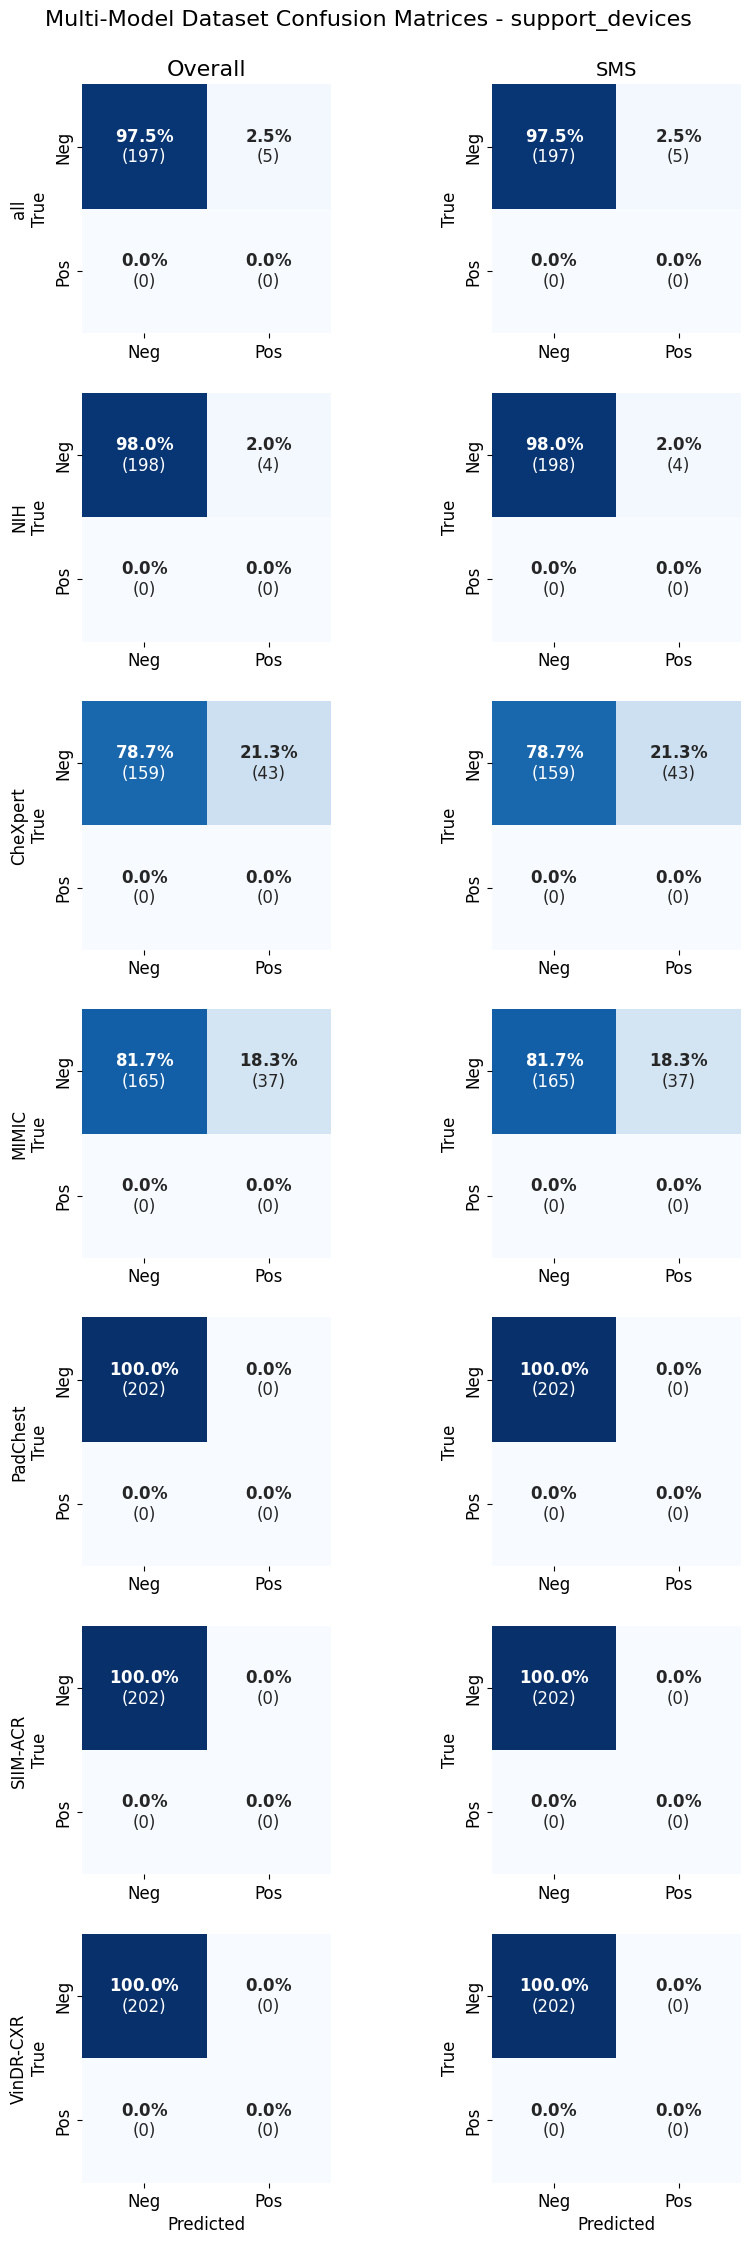

cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/sms_external_validation/multi_model_dataset_confusion_matrices_no_finding.png


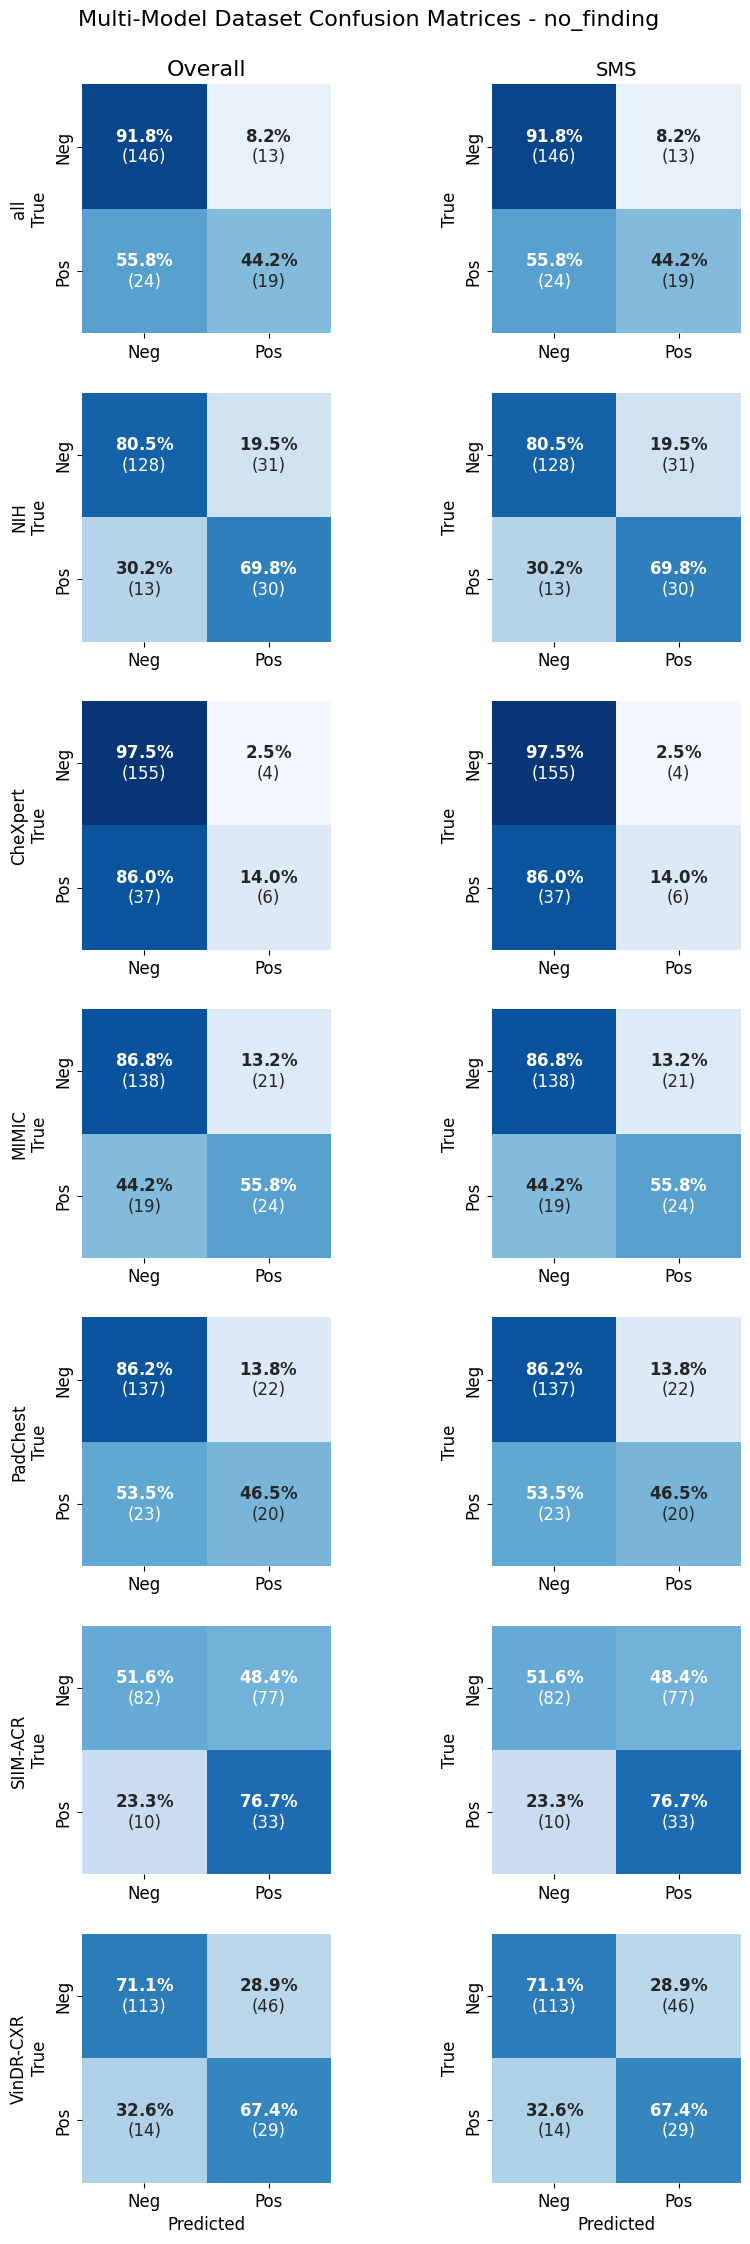


MULTI-MODEL COMPARISON SUMMARY
📊 Aggregated 7 models
📈 Generated ROC and PR comparison plots
📈 Generated ROC and PR plots with individual datasets
📊 Generated comparison plots for 7 metrics
📊 Generated confusion matrix comparison plots
💾 All results saved to: results/sms_external_validation


In [99]:
# Run comprehensive multi-model evaluation
multi_model_results = evaluate_multiple_models(
    model_evaluation_dict=model_evaluation_dict,
    class_names=class_names,
    save_dir='results/sms_external_validation',
    log_wandb=False,
    display=True,
    comparison_metrics=None,
)

# Access results
individual_results = multi_model_results['individual_results']
aggregated_results = multi_model_results['aggregated_results']

In [100]:
multi_model_results_bk = multi_model_results.copy()

# Use model trained with also valid set for comparison


In [101]:
# [checkpoint not released] weight_path_dictionary['all_valid'] = 'wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras'

In [102]:
weight_path_dictionary_multilabel = {key:value for key, value in weight_path_dictionary.items() if not key.endswith('binary')}

In [103]:
weight_path_dictionary_multilabel

{'all': 'wandb/run-20250429_005742-771kvn05/files/best_model_5_2.keras',
 'NIH': 'wandb/run-20250508_001521-obec6sw2/files/best_model_5.keras',
 'CheXpert': 'wandb/run-20250509_190645-z31hcpn7/files/best_model_5.keras',
 'MIMIC': 'wandb/run-20250511_164510-v3azo7z0/files/best_model_5.keras',
 'PadChest': 'wandb/run-20250513_230811-5nn8el06/files/best_model_5.keras',
 'SIIM-ACR': 'wandb/run-20250515_035838-b5h7q4r1/files/best_model_5.keras',
 'VinDR-CXR': 'wandb/run-20250515_090659-nncp4yw8/files/best_model_5.keras',
 'all_valid': 'wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras'}

In [105]:
model_evaluation_dict = {}
model_path_dictionary = weight_path_dictionary_multilabel

for model_name, model_path in model_path_dictionary.items():
    if model_name == 'all_valid':
        print(model_name)
        print(f'Loading {model_path}')
        #model.load_weights(model_path_dictionary.get(model_name))
        print('Model loaded successfully')
        
        # LOAD THE MODEL
        y_probs = model.predict(external_test_generator, verbose=1)
        df = save_predictions_to_df(df, y_probs, class_names, model_name=model_name)
        df.to_csv('external_test_filled.csv', index = False)
        y_true, y_probs = get_predictions_from_df(df, class_names, model_name=model_name, dataset=None)
        dataset_values = df['dataset'].values
    
        # Store evaluation parameters for this model
        model_evaluation_dict[model_name] = {
            'y_true': y_true,
            'y_probs': y_probs,
            'dataset_values': dataset_values,
            'threshold': [0.2, 0.5, 0.5],
            'use_optimal_thresholds': False,
            'n_bootstraps': 1000,
        }



all_valid
Loading wandb/run-20250429_005742-771kvn05/files/best_model_5_valid_2.keras
Model loaded successfully
26/26 [==============================] - 15s 555ms/step


In [106]:
df['all_pneumothorax_pred'] = df['all_valid_pneumothorax_pred']
df['all_no_finding_pred'] = df['all_valid_no_finding_pred']
df['all_support_devices_pred'] = df['all_valid_support_devices_pred']

In [107]:
model_name = 'all'
y_true, y_probs = get_predictions_from_df(df, class_names, model_name=model_name, dataset=None)
dataset_values = df['dataset'].values

In [108]:
from cxr.evaluate import evaluate_model

--- Starting Model Evaluation ---
Dataset-specific evaluation enabled. Found datasets: ['SMS']
Dataset 'SMS': 202 samples
🧩 Calculating Label Co-occurrence...
Saved plot: results/sms_external_validation/all/label_cooccurrence_matrix.png


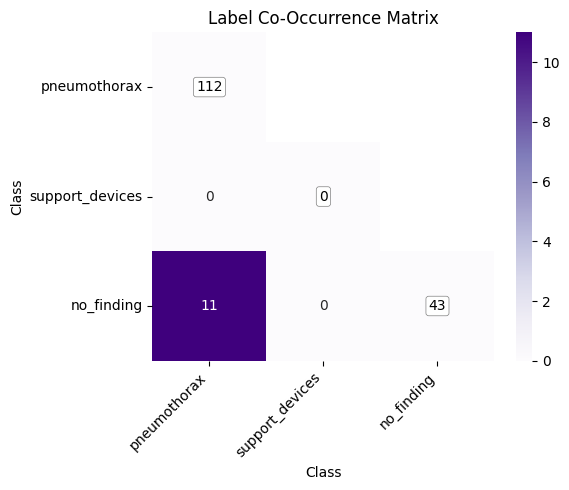


Using provided list/array of thresholds.

OVERALL DATASET EVALUATION

--- Evaluating Dataset: Overall ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (202, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (202, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.200', 'support_devices': '0.500', 'no_finding': '0.500'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG: Starting bootstrap loop. n_samples: 202, type: <class 'int'>


Bootstrapping:   0%|                                                                      | 0/1000 [00:00<?, ?it/s]

DEBUG Boot 0: indices type: <class 'numpy.ndarray'>, shape: (202,)
DEBUG Boot 0: y_true type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG Boot 0: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG Boot 0: y_probs type: <class 'numpy.ndarray'>, shape: (202, 3)


Bootstrapping: 100%|███████████████████████████████████████████████████████████| 1000/1000 [00:14<00:00, 70.27it/s]



DATASET-SPECIFIC EVALUATION

--- Evaluating Dataset: SMS ---
🔄 Calculating Metrics with Bootstrapping (n=1000)...
DEBUG: calculate_bootstrap_metrics received:
DEBUG: y_true type: <class 'numpy.ndarray'>, y_true shape: (202, 3)
DEBUG: y_probs type: <class 'numpy.ndarray'>, y_probs shape: (202, 3)
DEBUG: thresholds_dict type: <class 'dict'>, content: {'pneumothorax': 0.2, 'support_devices': 0.5, 'no_finding': 0.5}
DEBUG: n_bootstraps type: <class 'int'>, value: 1000
Using thresholds for bootstrapping: {'pneumothorax': '0.200', 'support_devices': '0.500', 'no_finding': '0.500'}
DEBUG: valid_thresholds for y_pred_baseline shape: (3,)
DEBUG: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG: Starting bootstrap loop. n_samples: 202, type: <class 'int'>


Bootstrapping:   1%|▍                                                             | 8/1000 [00:00<00:13, 71.50it/s]

DEBUG Boot 0: indices type: <class 'numpy.ndarray'>, shape: (202,)
DEBUG Boot 0: y_true type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG Boot 0: y_pred_baseline type: <class 'numpy.ndarray'>, shape: (202, 3)
DEBUG Boot 0: y_probs type: <class 'numpy.ndarray'>, shape: (202, 3)


Bootstrapping: 100%|███████████████████████████████████████████████████████████| 1000/1000 [00:14<00:00, 70.87it/s]


Saved combined dataset metrics: results/sms_external_validation/all/combined_dataset_metrics_summary.csv

============================== METRICS SUMMARY ==============================
🔍 Global Metrics (Mean, 95% CI):
        Category            Accuracy           Precision Recall (Sensitivity)            F1-score AUC
         Overall 0.389 (0.317–0.455)                 N/A                  N/A                 N/A N/A
   Macro Average                 N/A 0.391 (0.328–0.452)   0.29 (0.238–0.341) 0.266 (0.213–0.314) N/A
   Micro Average                 N/A  0.493 (0.394–0.59)    0.328 (0.252–0.4) 0.394 (0.313–0.465) N/A
Weighted Average                 N/A 0.678 (0.558–0.784)    0.328 (0.252–0.4) 0.362 (0.273–0.439) N/A

📊 Per-Class Metrics (Mean, 95% CI):
          Class      Prevalence Sensitivity (Recall)         Specificity     PPV (Precision)                 NPV            F1-score                 AUC                  AP
   pneumothorax 55.4% (112/202)   0.196 (0.123–0.27) 0.934 (0.8

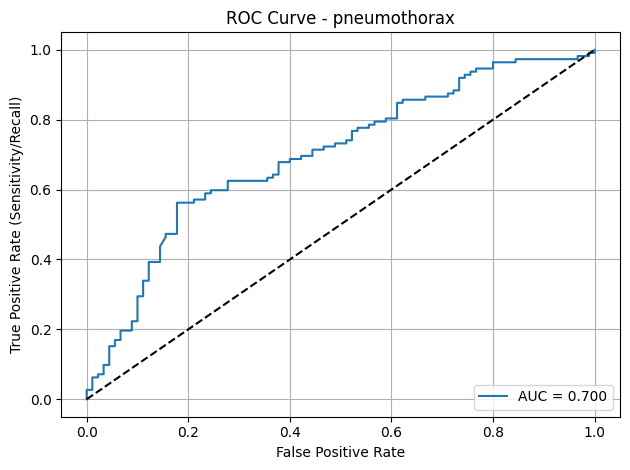

Saved plot: results/sms_external_validation/all/roc_curve_no_finding.png


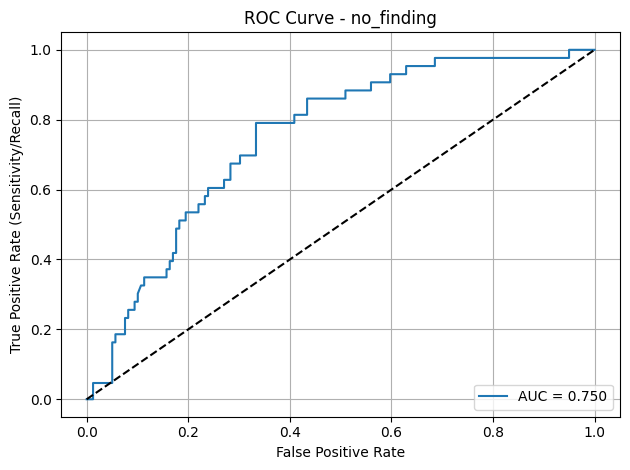

📈 Plotting Precision-Recall Curves...
Saved plot: results/sms_external_validation/all/pr_curve_pneumothorax.png


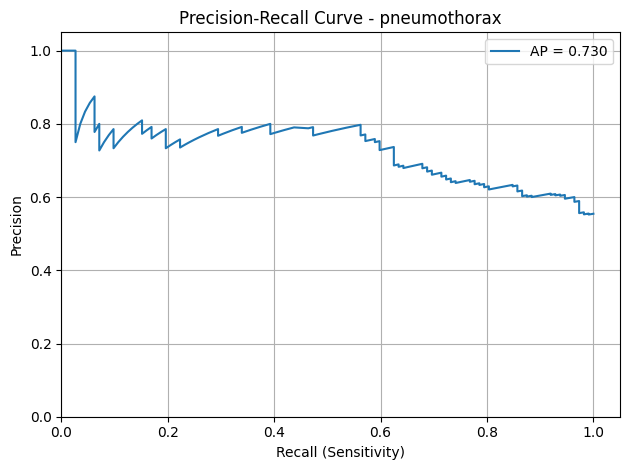

Saved plot: results/sms_external_validation/all/pr_curve_no_finding.png


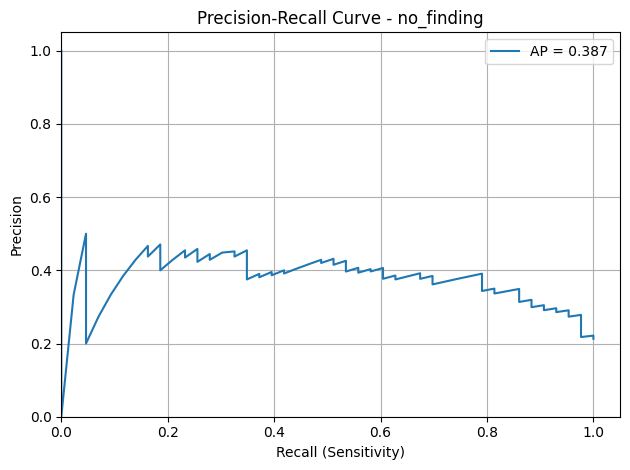

📊 Plotting Confusion Matrices...
Saved plot: results/sms_external_validation/all/confusion_matrix_norm_pneumothorax.png


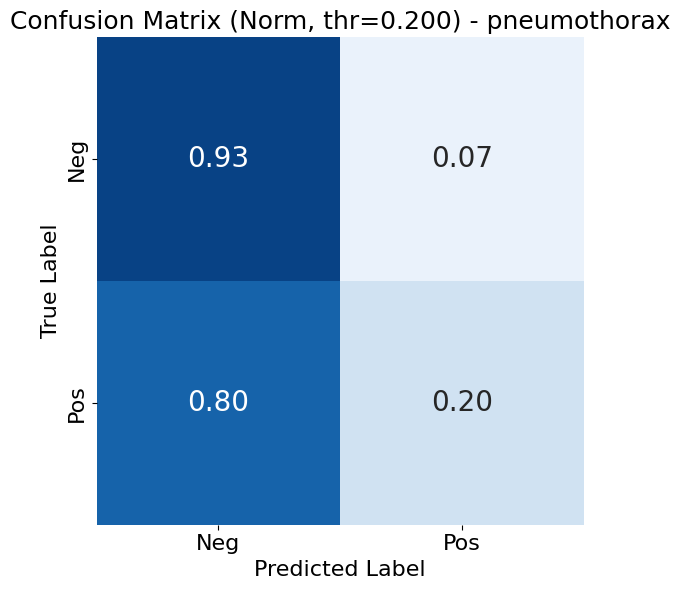

Saved plot: results/sms_external_validation/all/confusion_matrix_raw_pneumothorax.png


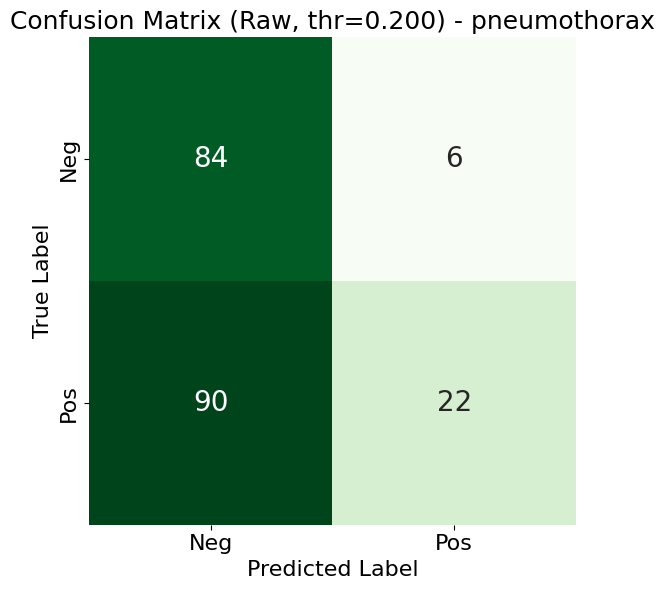

Saved plot: results/sms_external_validation/all/confusion_matrix_combined_pneumothorax.png


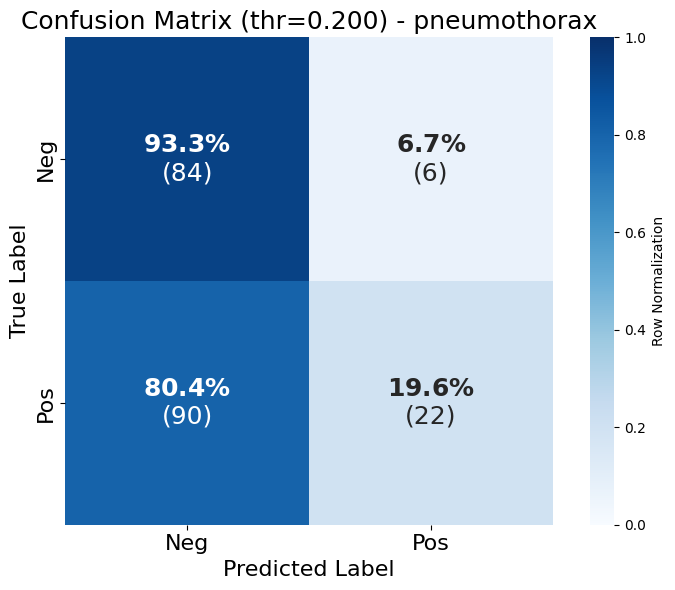

Saved plot: results/sms_external_validation/all/confusion_matrix_norm_support_devices.png


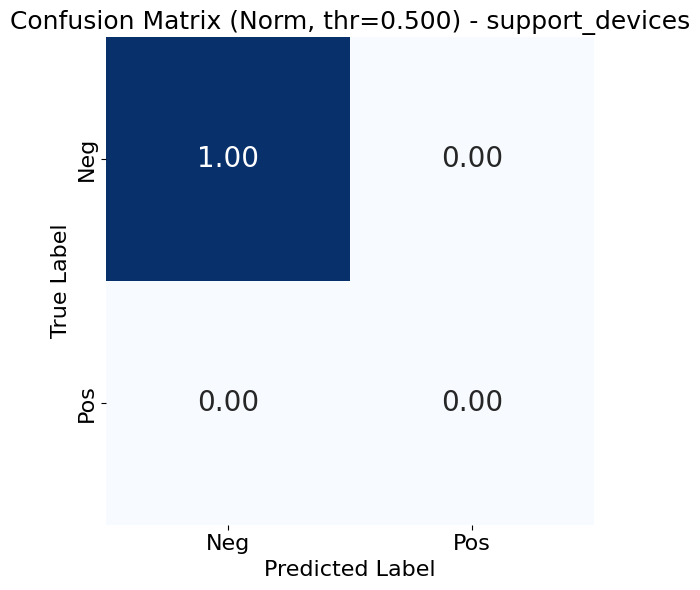

Saved plot: results/sms_external_validation/all/confusion_matrix_raw_support_devices.png


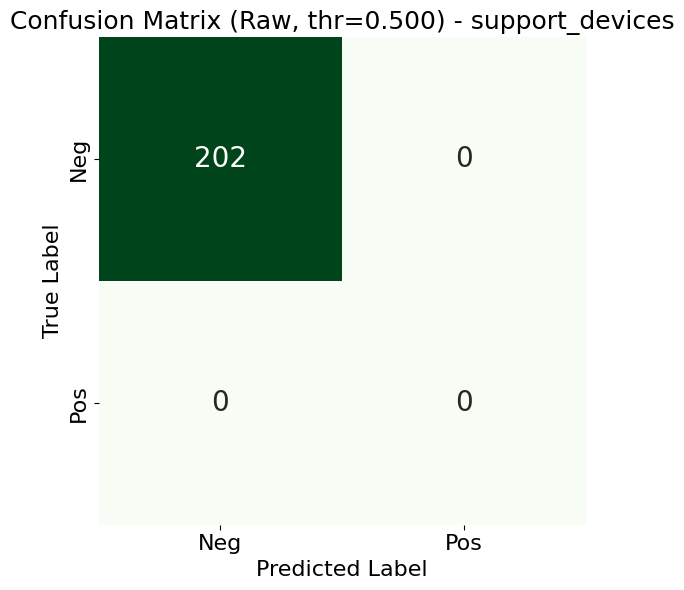

Saved plot: results/sms_external_validation/all/confusion_matrix_combined_support_devices.png


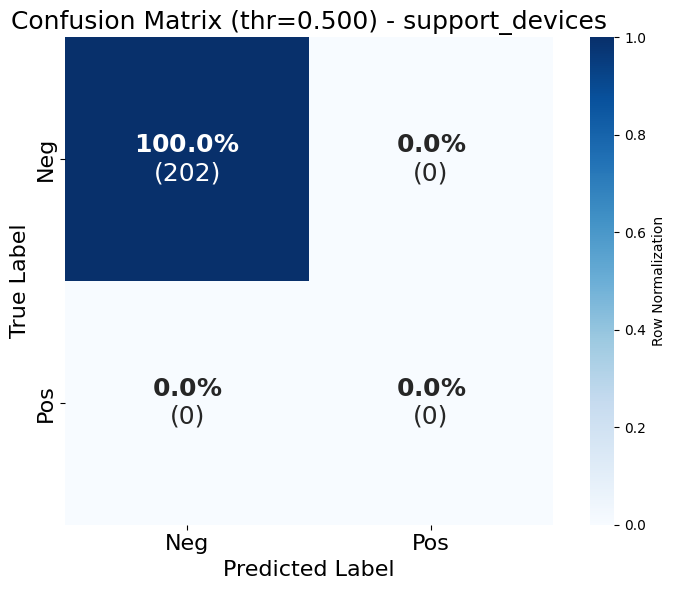

Saved plot: results/sms_external_validation/all/confusion_matrix_norm_no_finding.png


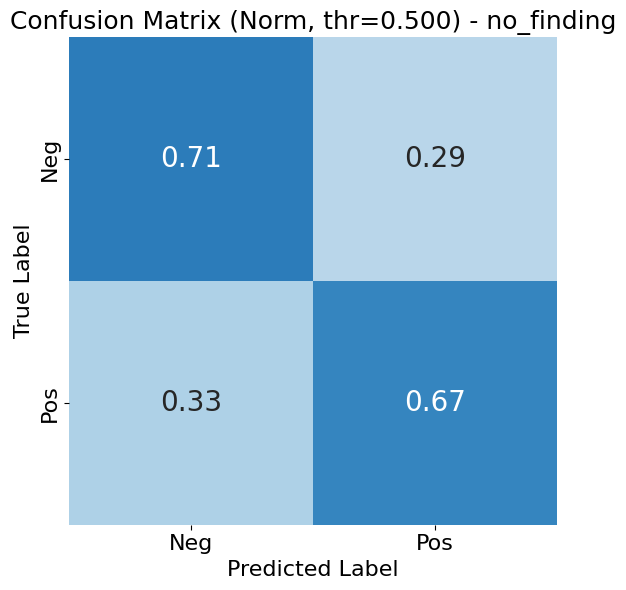

Saved plot: results/sms_external_validation/all/confusion_matrix_raw_no_finding.png


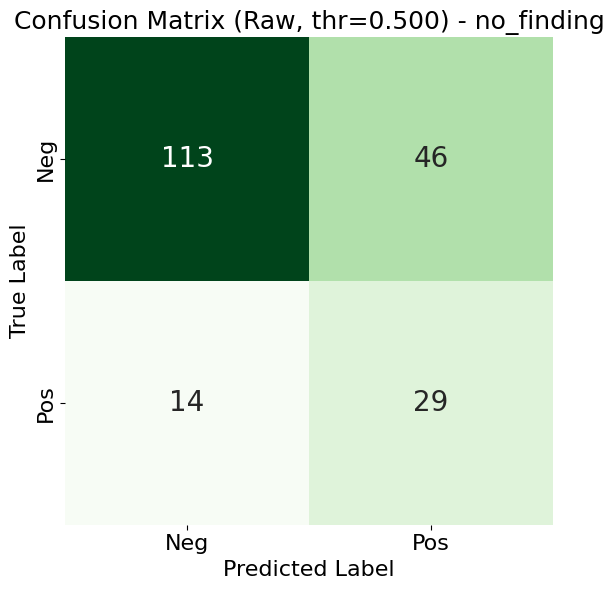

Saved plot: results/sms_external_validation/all/confusion_matrix_combined_no_finding.png


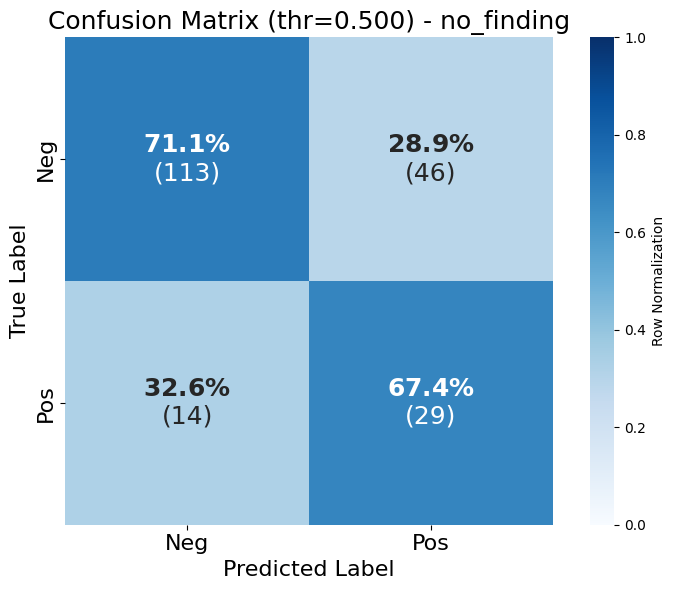

🧹 Plotting Threshold Sweep Metrics...
Saved plot: results/sms_external_validation/all/threshold_sweep_pneumothorax.png


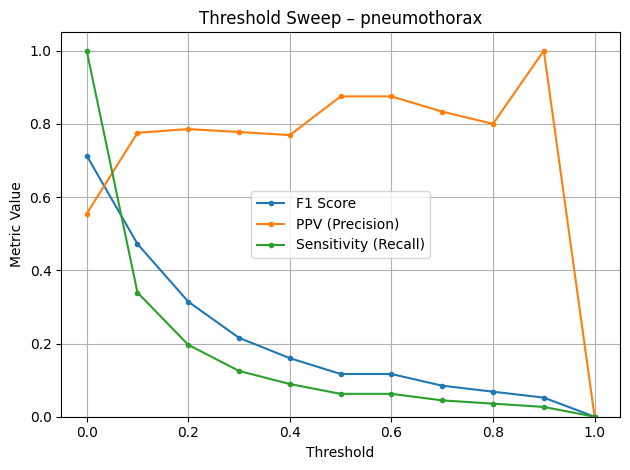

Saved plot: results/sms_external_validation/all/threshold_sweep_support_devices.png


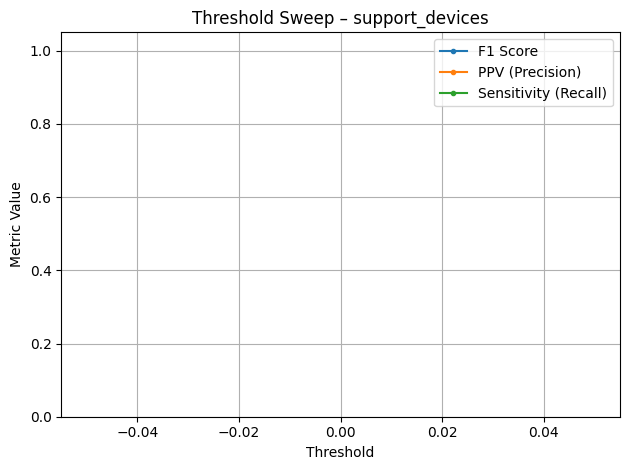

Saved plot: results/sms_external_validation/all/threshold_sweep_no_finding.png


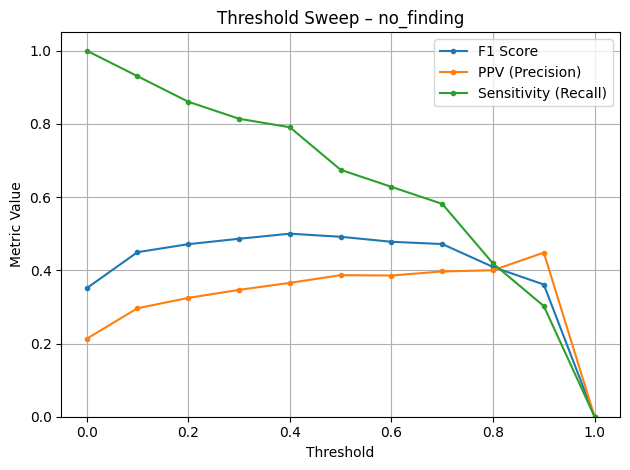

Saved threshold sweep table: results/sms_external_validation/all/threshold_sweep_table.csv

Generating dataset-specific plots...

Plots for dataset: SMS
📈 Plotting ROC Curves - SMS...
Saved plot: results/sms_external_validation/all/dataset_SMS/roc_curve_pneumothorax.png


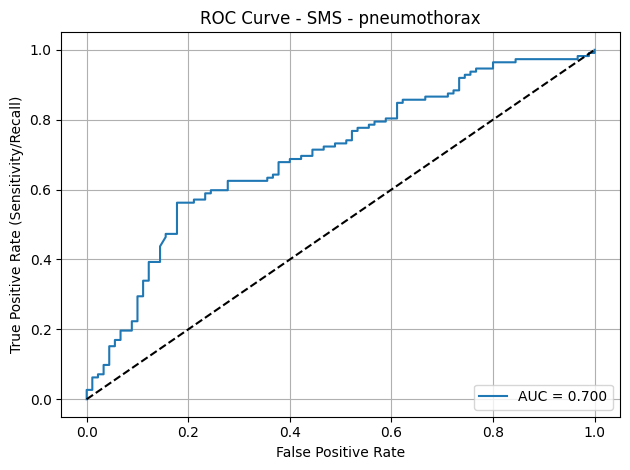

Saved plot: results/sms_external_validation/all/dataset_SMS/roc_curve_no_finding.png


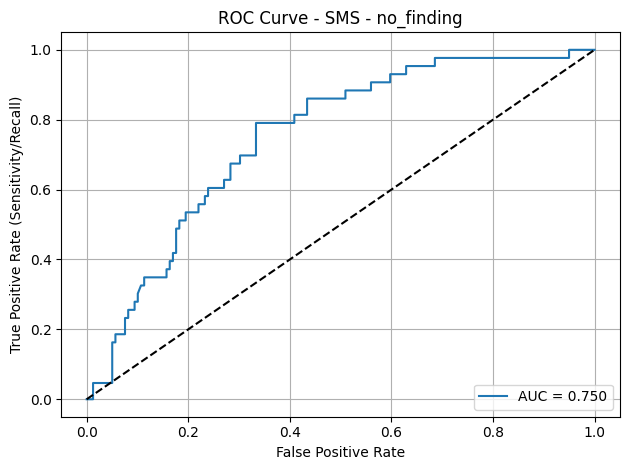

📈 Plotting Precision-Recall Curves - SMS...
Saved plot: results/sms_external_validation/all/dataset_SMS/pr_curve_pneumothorax.png


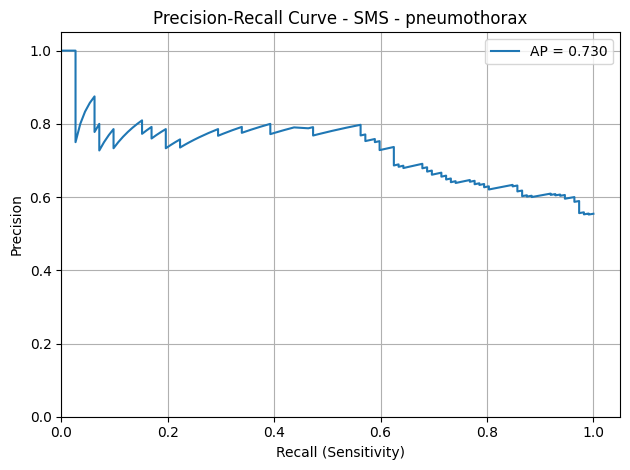

Saved plot: results/sms_external_validation/all/dataset_SMS/pr_curve_no_finding.png


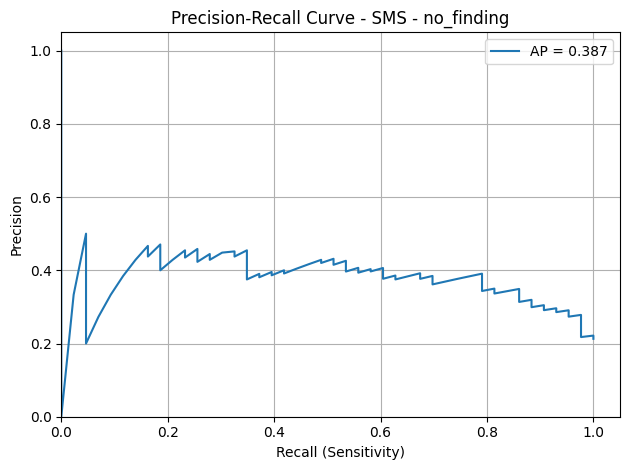

📊 Plotting Confusion Matrices - SMS...
Saved plot: results/sms_external_validation/all/dataset_SMS/confusion_matrix_norm_pneumothorax.png


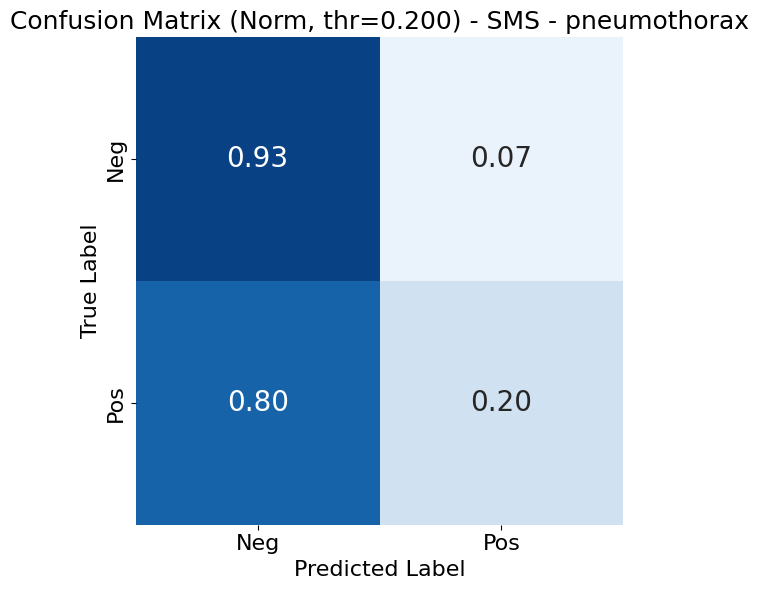

Saved plot: results/sms_external_validation/all/dataset_SMS/confusion_matrix_raw_pneumothorax.png


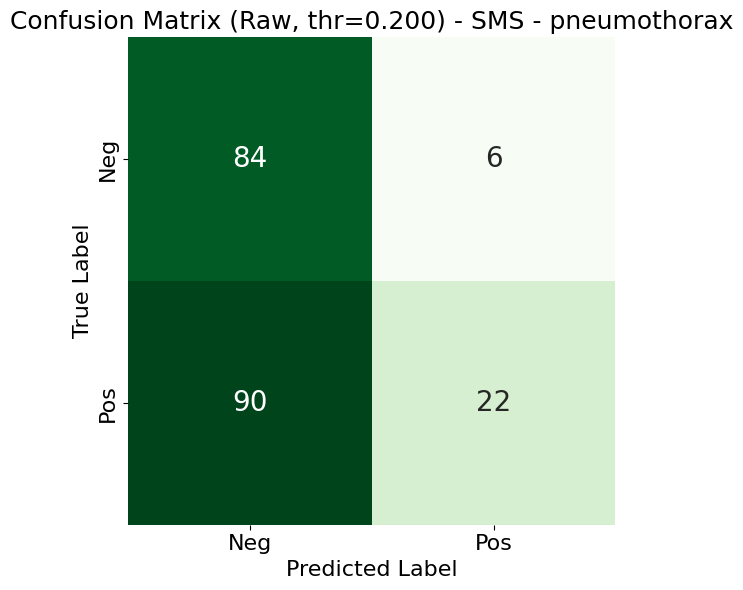

Saved plot: results/sms_external_validation/all/dataset_SMS/confusion_matrix_combined_pneumothorax.png


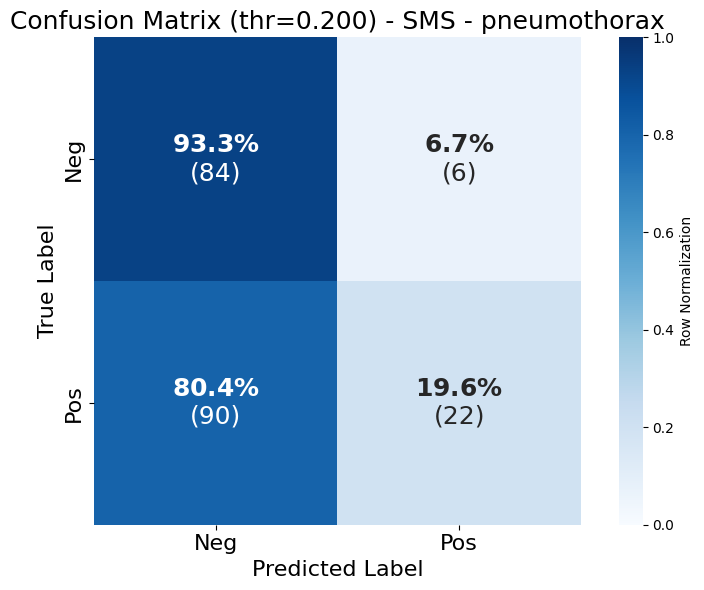

Saved plot: results/sms_external_validation/all/dataset_SMS/confusion_matrix_norm_support_devices.png


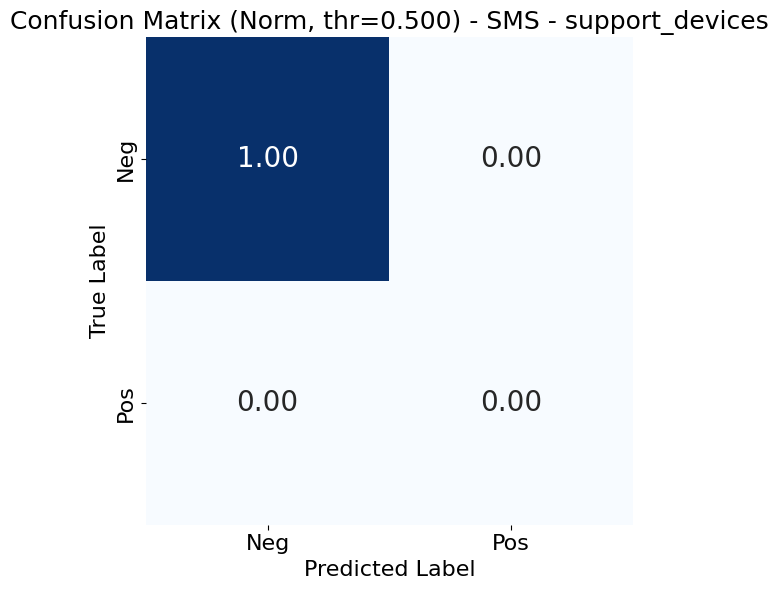

Saved plot: results/sms_external_validation/all/dataset_SMS/confusion_matrix_raw_support_devices.png


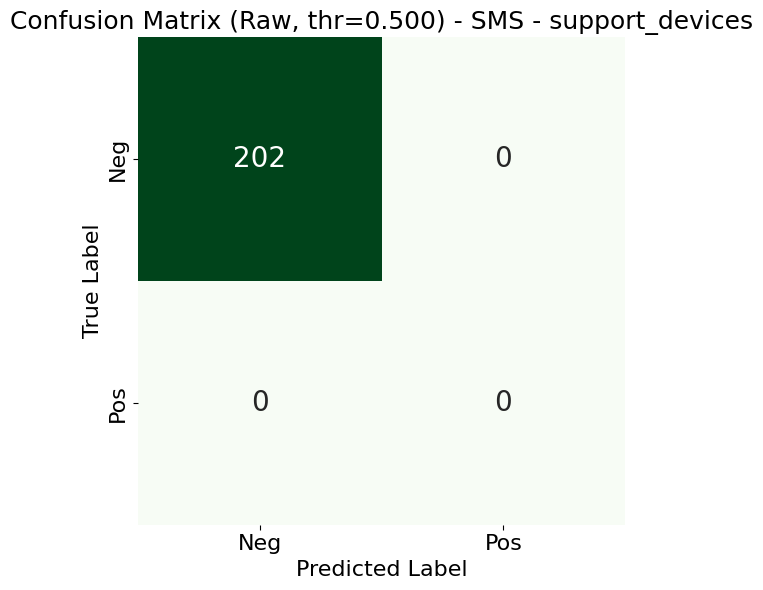

Saved plot: results/sms_external_validation/all/dataset_SMS/confusion_matrix_combined_support_devices.png


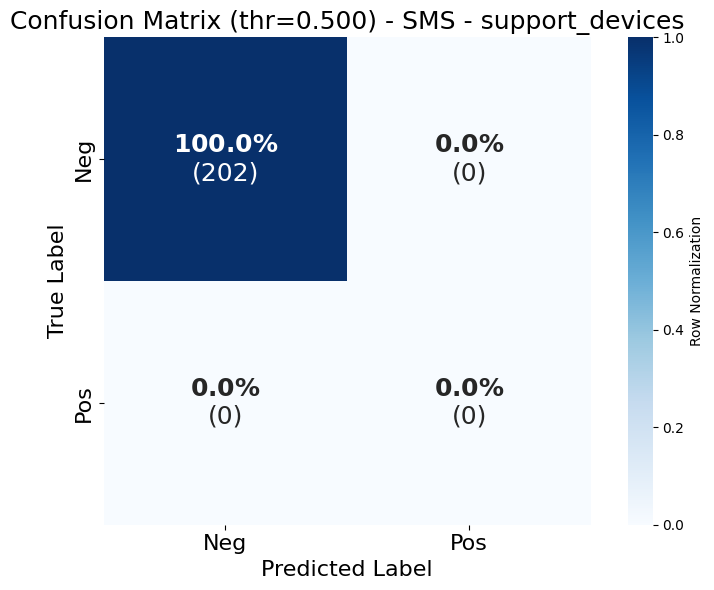

Saved plot: results/sms_external_validation/all/dataset_SMS/confusion_matrix_norm_no_finding.png


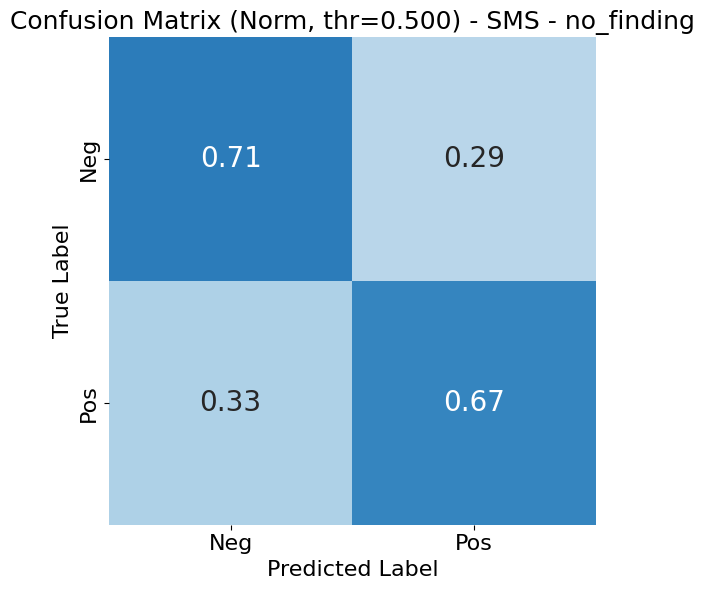

Saved plot: results/sms_external_validation/all/dataset_SMS/confusion_matrix_raw_no_finding.png


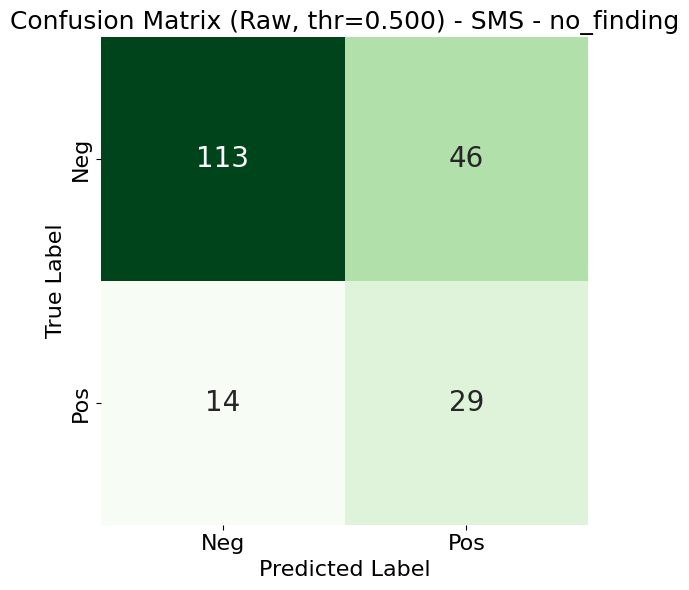

Saved plot: results/sms_external_validation/all/dataset_SMS/confusion_matrix_combined_no_finding.png


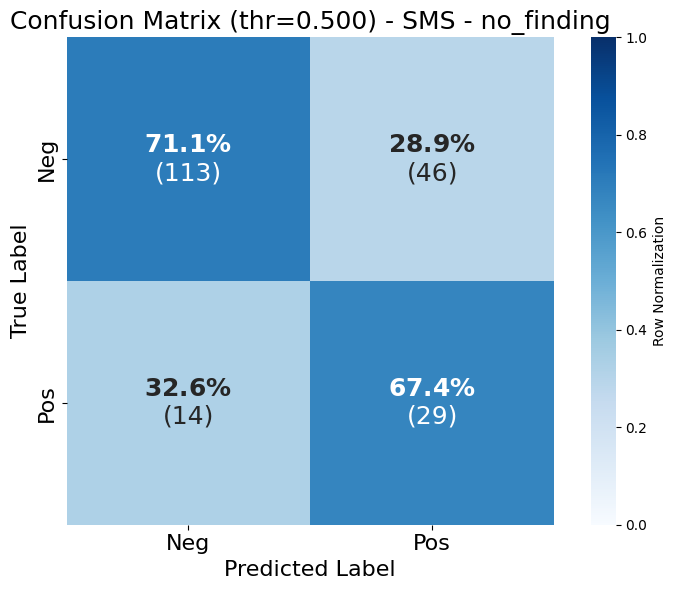

🧹 Plotting Threshold Sweep Metrics...
Saved plot: results/sms_external_validation/all/dataset_SMS/threshold_sweep_pneumothorax.png


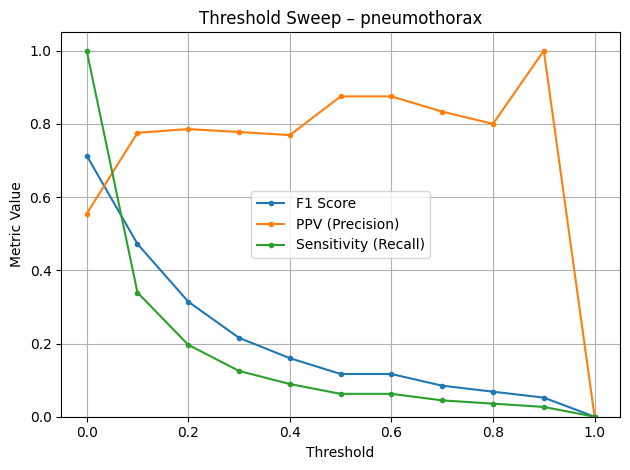

Saved plot: results/sms_external_validation/all/dataset_SMS/threshold_sweep_support_devices.png


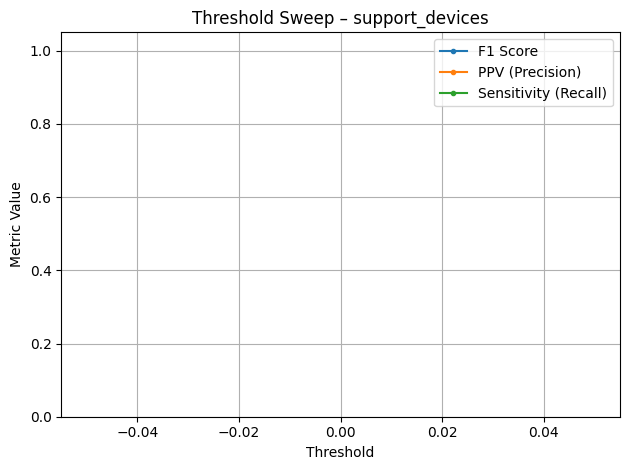

Saved plot: results/sms_external_validation/all/dataset_SMS/threshold_sweep_no_finding.png


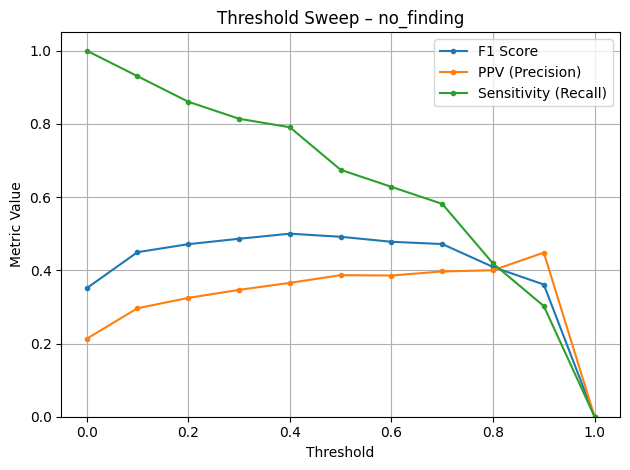

Saved threshold sweep table: results/sms_external_validation/all/dataset_SMS/threshold_sweep_table.csv
🧩 Calculating Label Co-occurrence...
Saved plot: results/sms_external_validation/all/dataset_SMS/label_cooccurrence_matrix.png


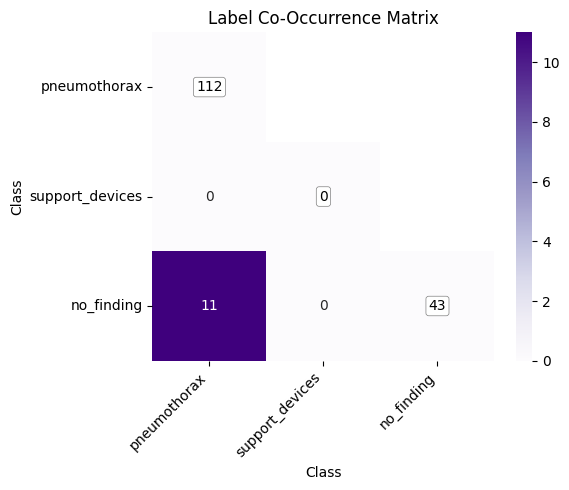


Generating combined dataset plots...
📈 Plotting Combined ROC Curves...
Saved plot: results/sms_external_validation/all/combined_roc_curve_pneumothorax.png


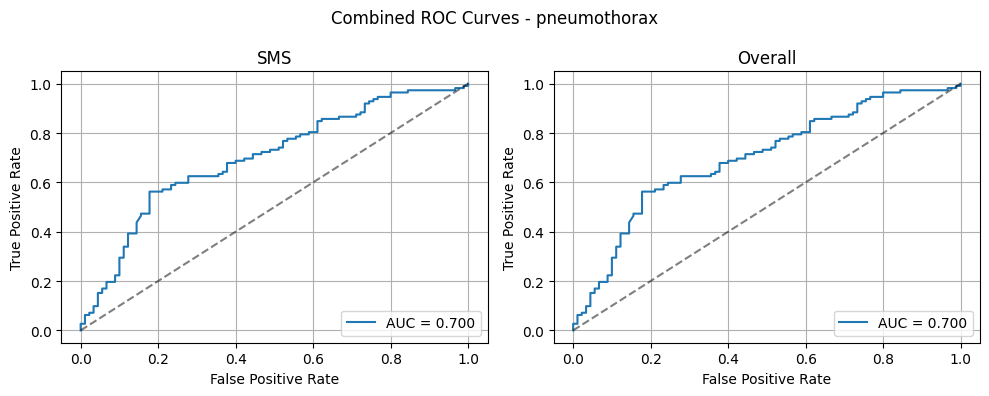

Saved plot: results/sms_external_validation/all/combined_roc_curve_support_devices.png


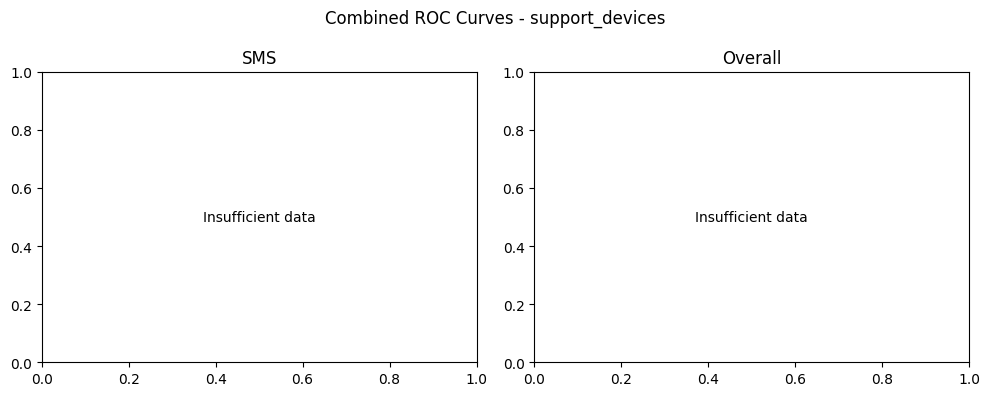

Saved plot: results/sms_external_validation/all/combined_roc_curve_no_finding.png


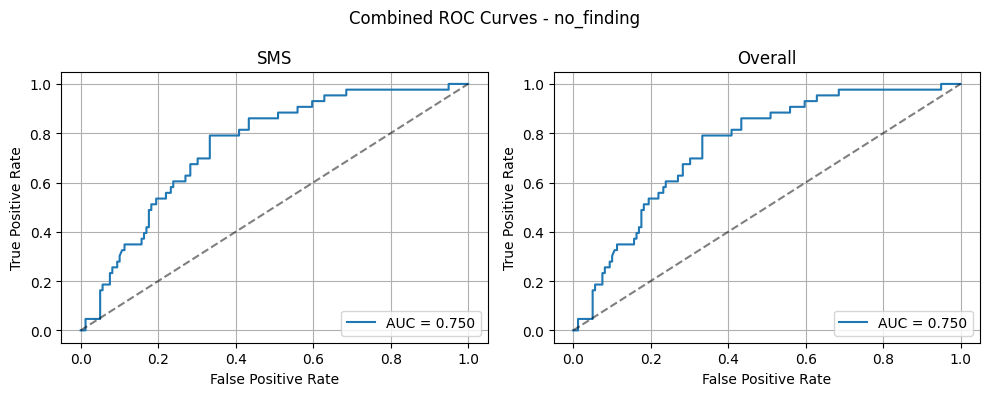

📈 Plotting Combined PR Curves...
Saved plot: results/sms_external_validation/all/combined_pr_curve_pneumothorax.png


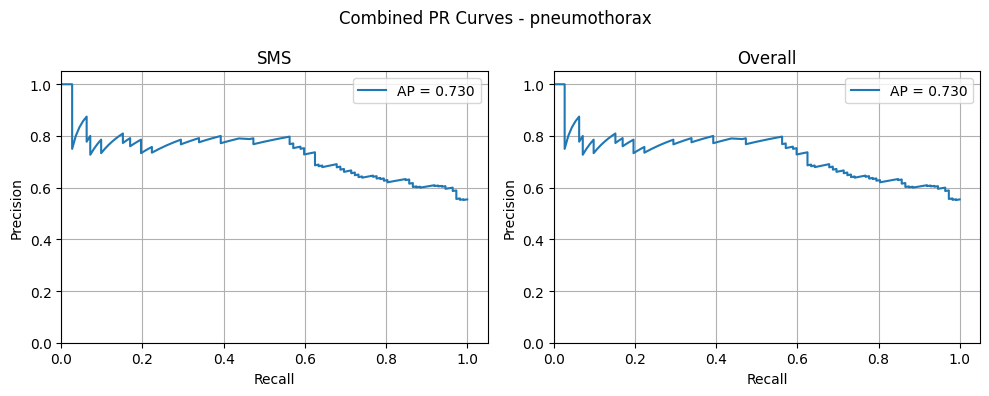

Saved plot: results/sms_external_validation/all/combined_pr_curve_support_devices.png


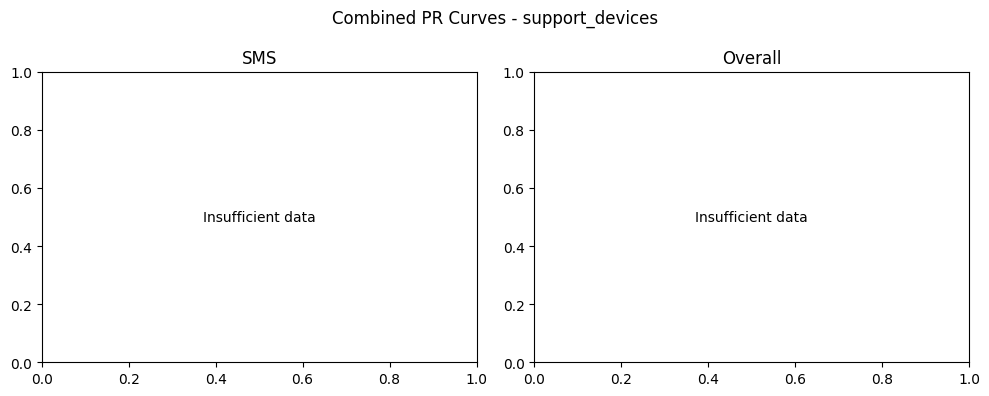

Saved plot: results/sms_external_validation/all/combined_pr_curve_no_finding.png


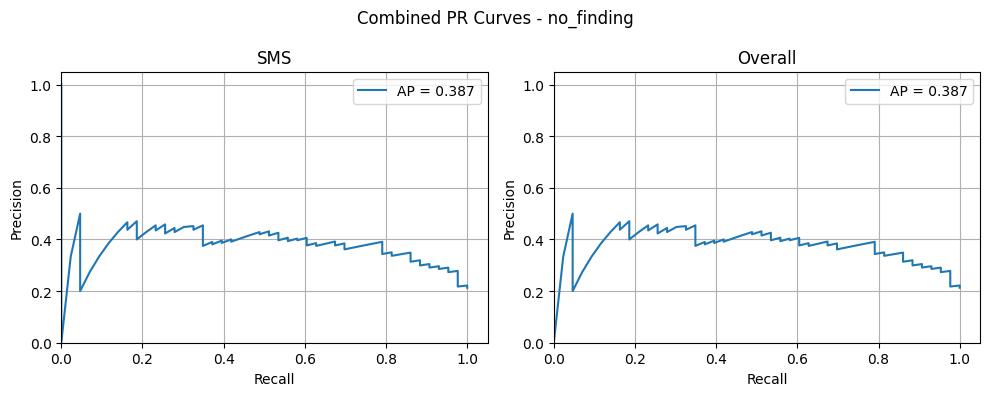

📊 Plotting Combined Confusion Matrices...
Saved plot: results/sms_external_validation/all/combined_confusion_matrix_pneumothorax.png


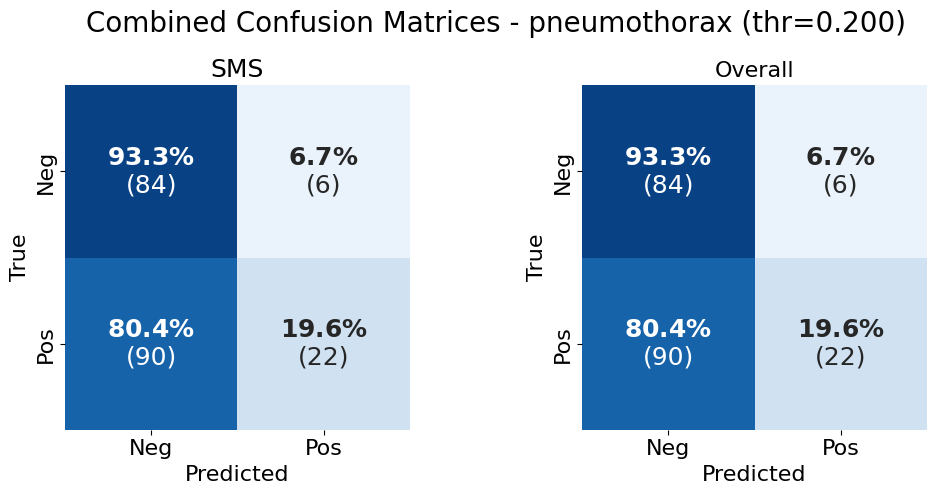

Saved plot: results/sms_external_validation/all/combined_confusion_matrix_support_devices.png


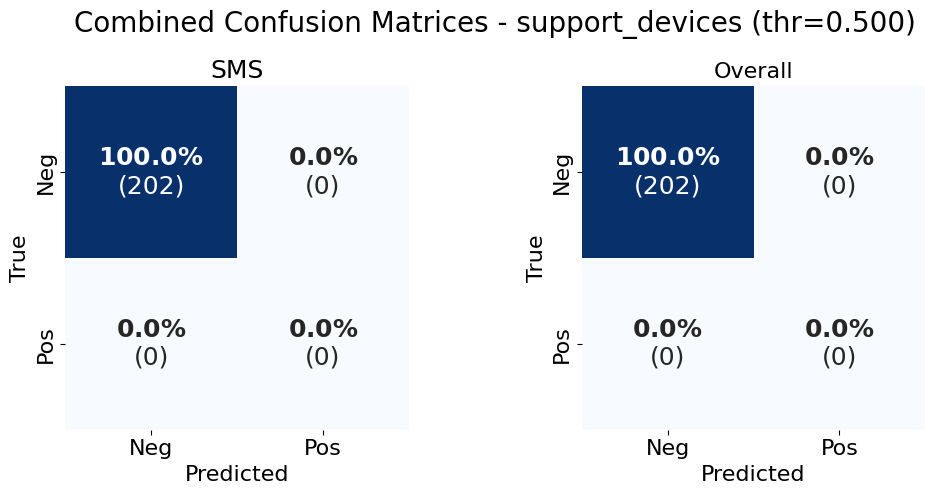

Saved plot: results/sms_external_validation/all/combined_confusion_matrix_no_finding.png


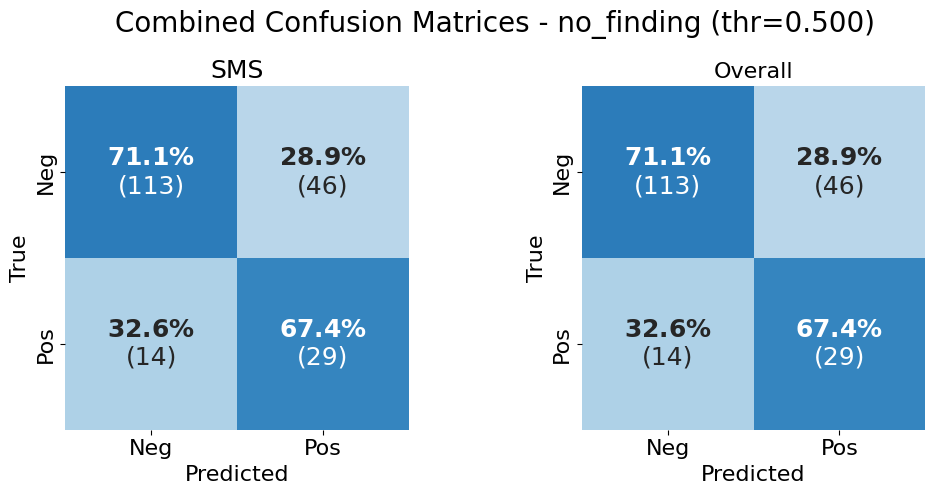


Generating single plots with all datasets...
📈 Plotting Single ROC Curves (All Datasets)...
Saved plot: results/sms_external_validation/all/single_roc_curve_pneumothorax.png


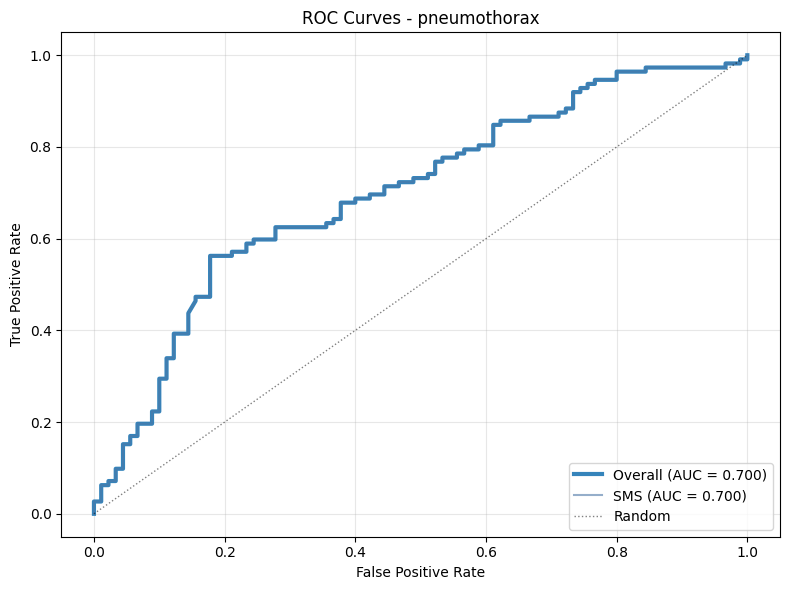

Saved plot: results/sms_external_validation/all/single_roc_curve_support_devices.png


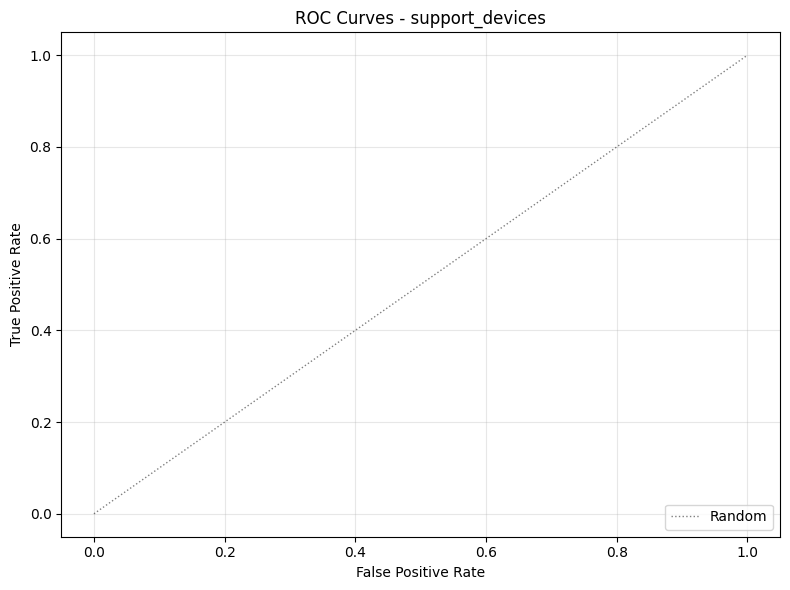

Saved plot: results/sms_external_validation/all/single_roc_curve_no_finding.png


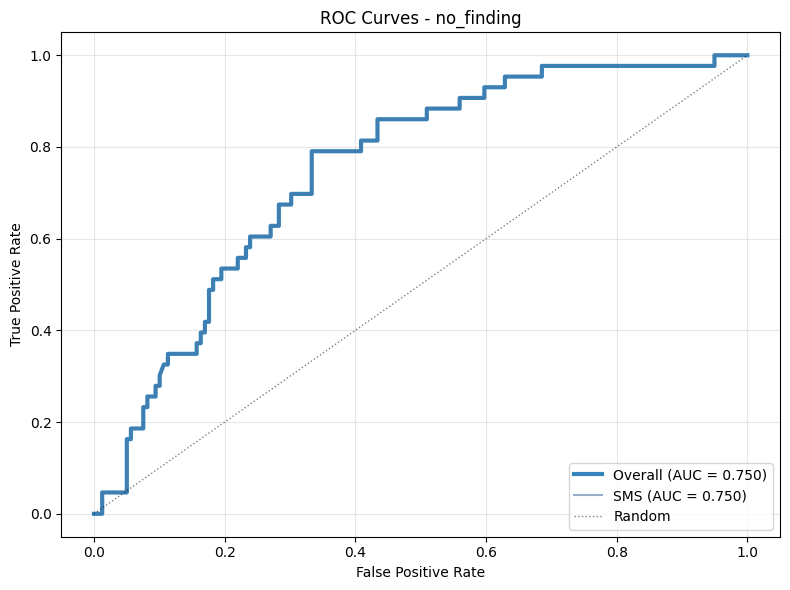

📈 Plotting Single PR Curves (All Datasets)...
Saved plot: results/sms_external_validation/all/single_pr_curve_pneumothorax.png


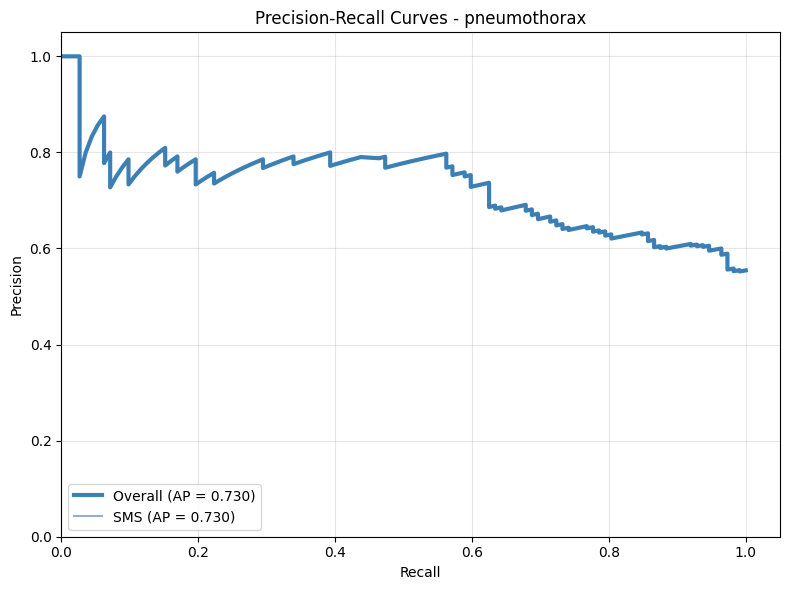

Saved plot: results/sms_external_validation/all/single_pr_curve_support_devices.png


cxr/evaluate.py:2542: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower left")


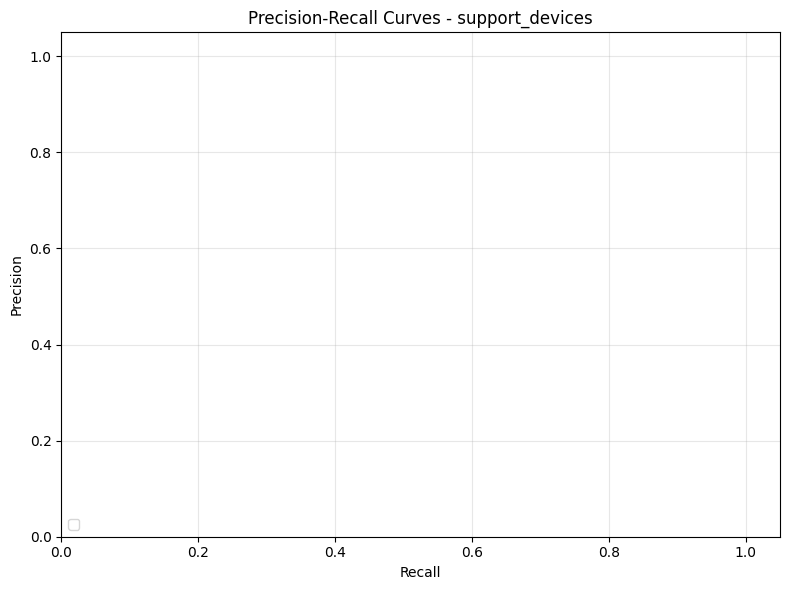

Saved plot: results/sms_external_validation/all/single_pr_curve_no_finding.png


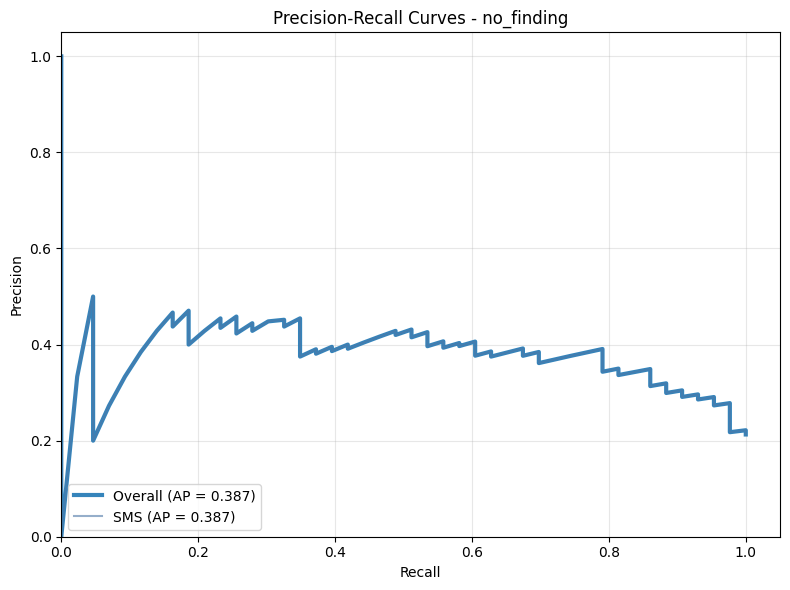


🔍 Analyzing Precision-Recall Tradeoffs...

Precision-Recall Tradeoffs:
       Class Target Metric  Target Value Achieved Metric  Achieved Value  Actual Precision  Threshold  Actual Recall
pneumothorax     Precision         0.850          Recall           0.062             0.875      0.460            N/A
pneumothorax     Precision         0.900          Recall           0.027             1.000      0.837            N/A
pneumothorax     Precision         0.950          Recall           0.027             1.000      0.837            N/A
pneumothorax        Recall         0.800       Precision           0.633               N/A      0.010          0.848
pneumothorax        Recall         0.850       Precision           0.632               N/A      0.009          0.857
pneumothorax        Recall         0.900       Precision           0.609               N/A      0.006          0.920
  no_finding     Precision         0.850          Recall           0.000             1.000      0.993        

In [109]:
all_valid_results = evaluate_model(y_true, y_probs, class_names, threshold = [0.2, 0.5, 0.5], save_dir = 'results/sms_external_validation/all', use_optimal_thresholds=False, log_wandb=False, display = True, dataset_values=dataset_values)

In [110]:
individual_results['all'] = all_valid_results
individual_results['all']['y_true'] = y_true
individual_results['all']['y_probs'] = y_probs
individual_results['all']['dataset_values'] = dataset_values


AGGREGATING MULTI-MODEL RESULTS

📊 Dataset Availability Check:
✅ Models with dataset information: ['all', 'NIH', 'CheXpert', 'MIMIC', 'PadChest', 'SIIM-ACR', 'VinDR-CXR']
❌ Models without dataset information: []
🔄 Aggregating results from multiple models...
Creating per-metric CSV files...
  Creating CSV for metric: Sensitivity (Recall)
    Saved: results/sms_external_validation2/metric_Sensitivity_Recall_models_vs_datasets.csv
  Creating CSV for metric: Specificity
    Saved: results/sms_external_validation2/metric_Specificity_models_vs_datasets.csv
  Creating CSV for metric: PPV (Precision)
    Saved: results/sms_external_validation2/metric_PPV_Precision_models_vs_datasets.csv
  Creating CSV for metric: NPV
    Saved: results/sms_external_validation2/metric_NPV_models_vs_datasets.csv
  Creating CSV for metric: F1-score
    Saved: results/sms_external_validation2/metric_F1-score_models_vs_datasets.csv
  Creating CSV for metric: AUC
    Saved: results/sms_external_validation2/metric_A

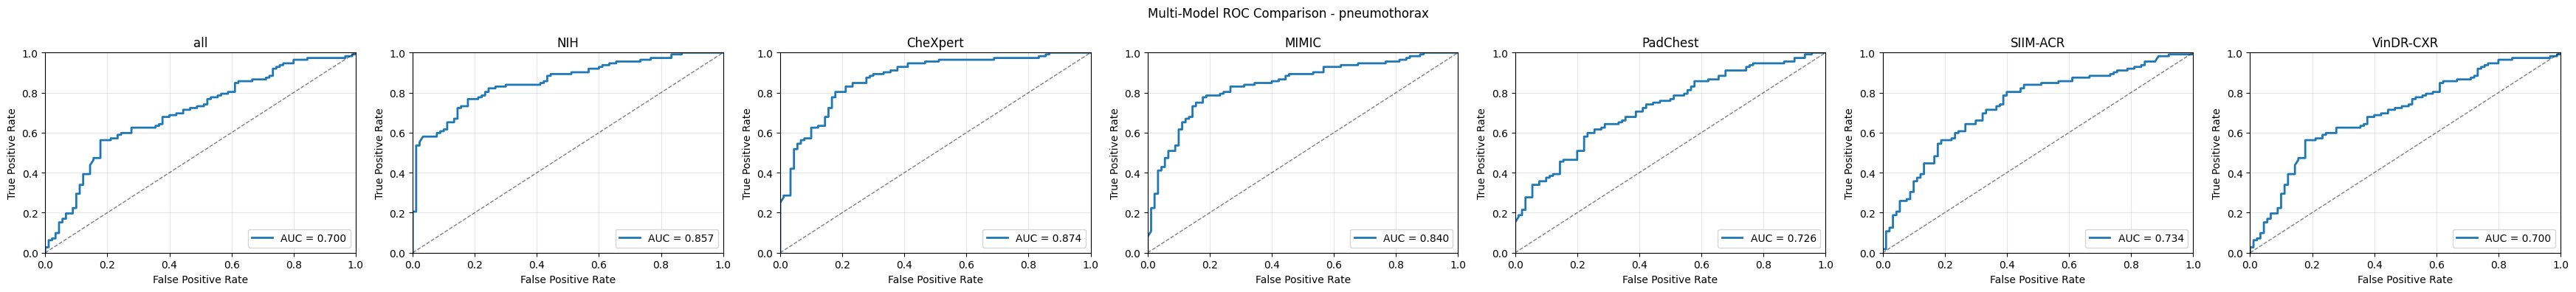

cxr/evaluate.py:2854: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower right")


Saved plot: results/sms_external_validation2/multi_model_roc_support_devices.png


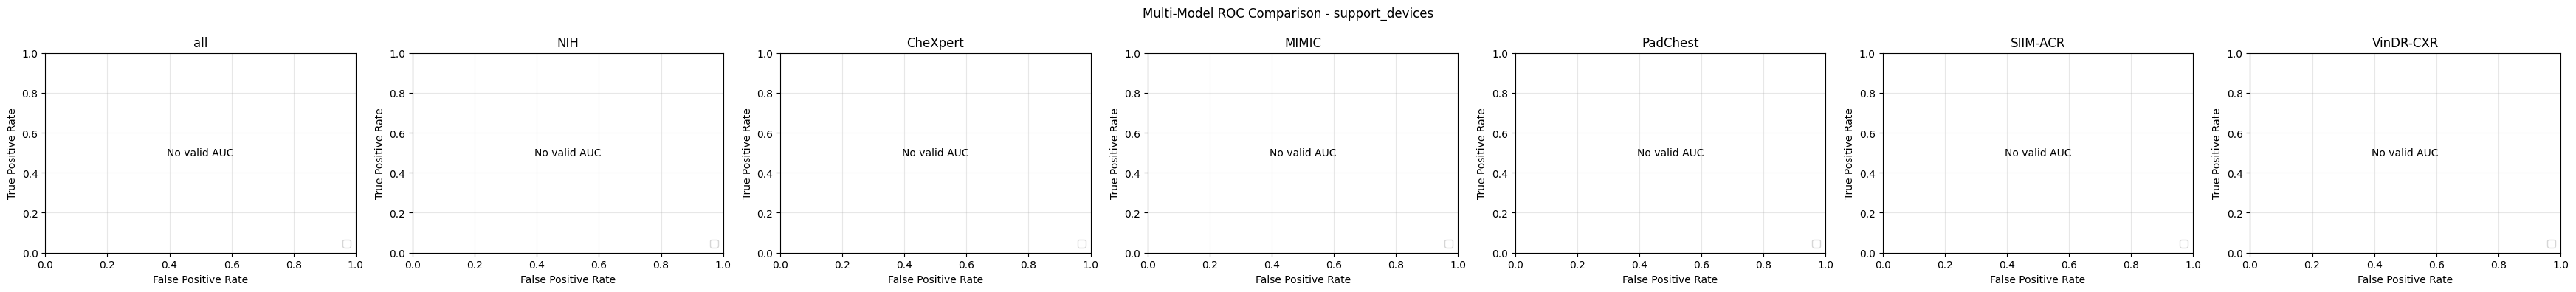

Saved plot: results/sms_external_validation2/multi_model_roc_no_finding.png


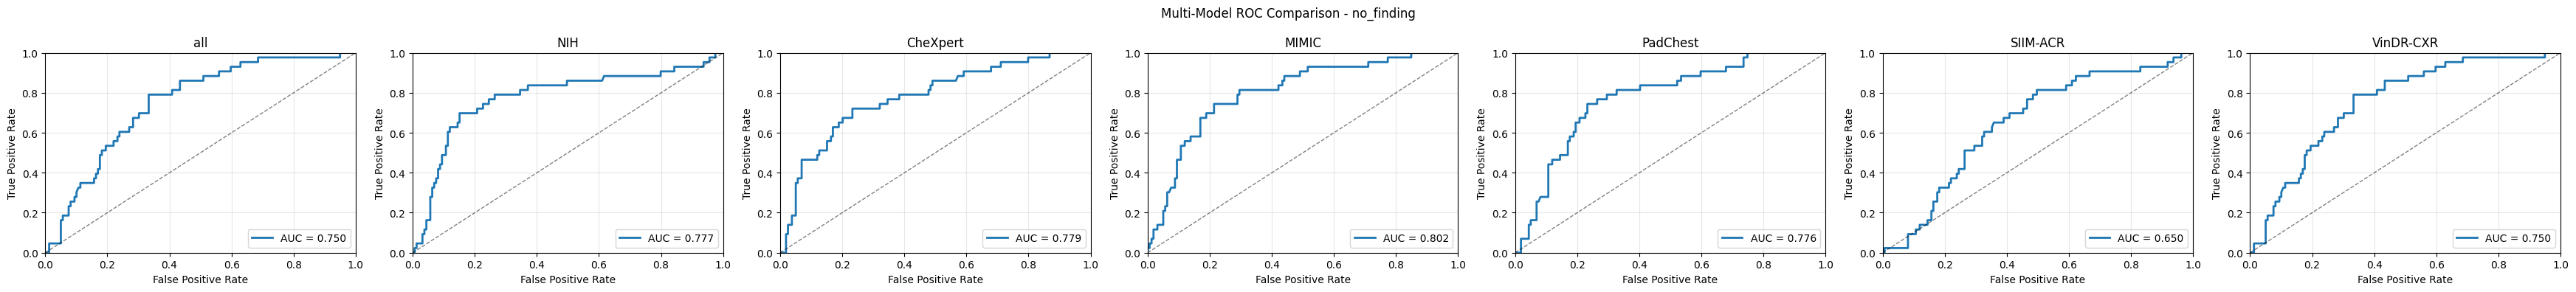

📈 Plotting Multi-Model PR Curves...
Saved plot: results/sms_external_validation2/multi_model_pr_pneumothorax.png


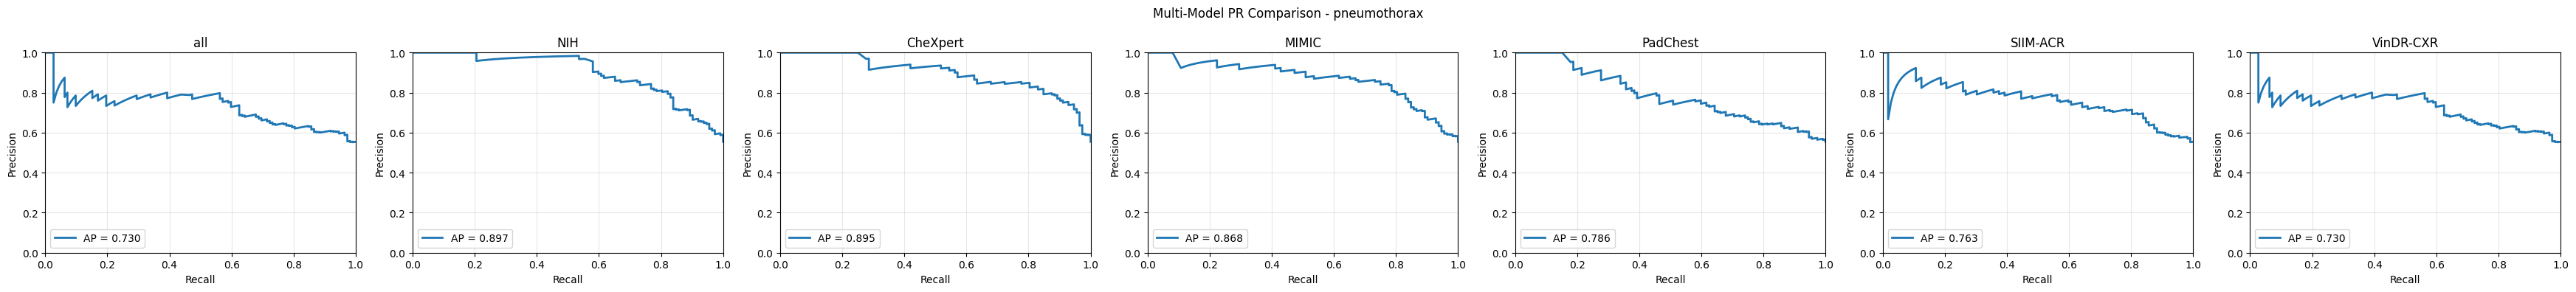

Saved plot: results/sms_external_validation2/multi_model_pr_support_devices.png


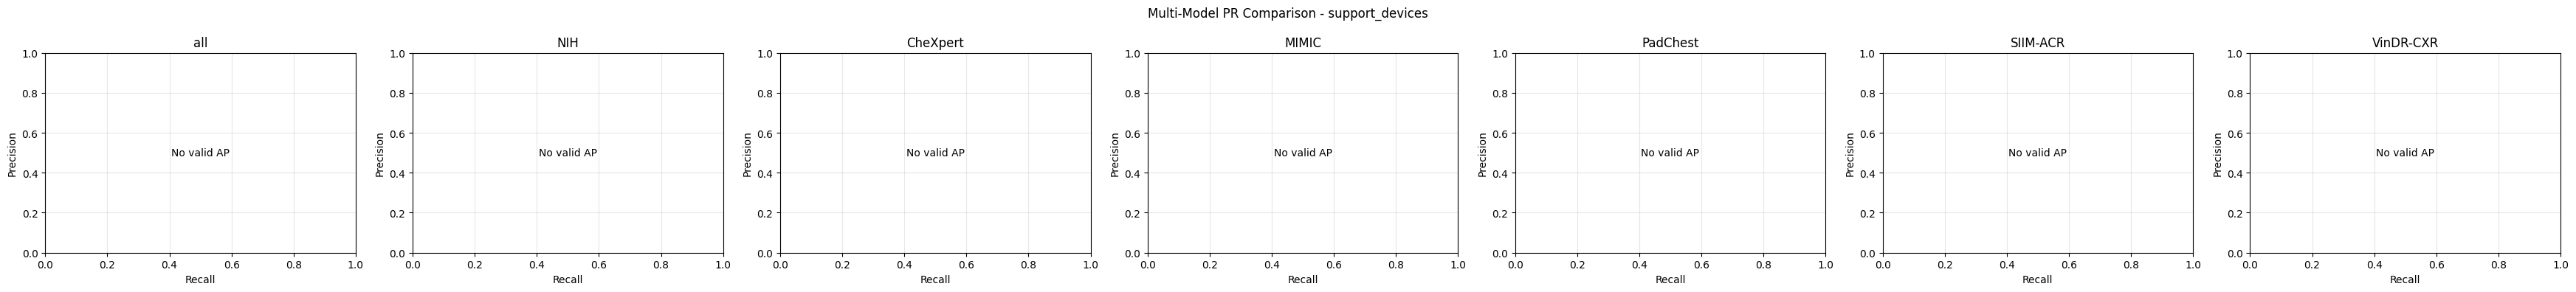

Saved plot: results/sms_external_validation2/multi_model_pr_no_finding.png


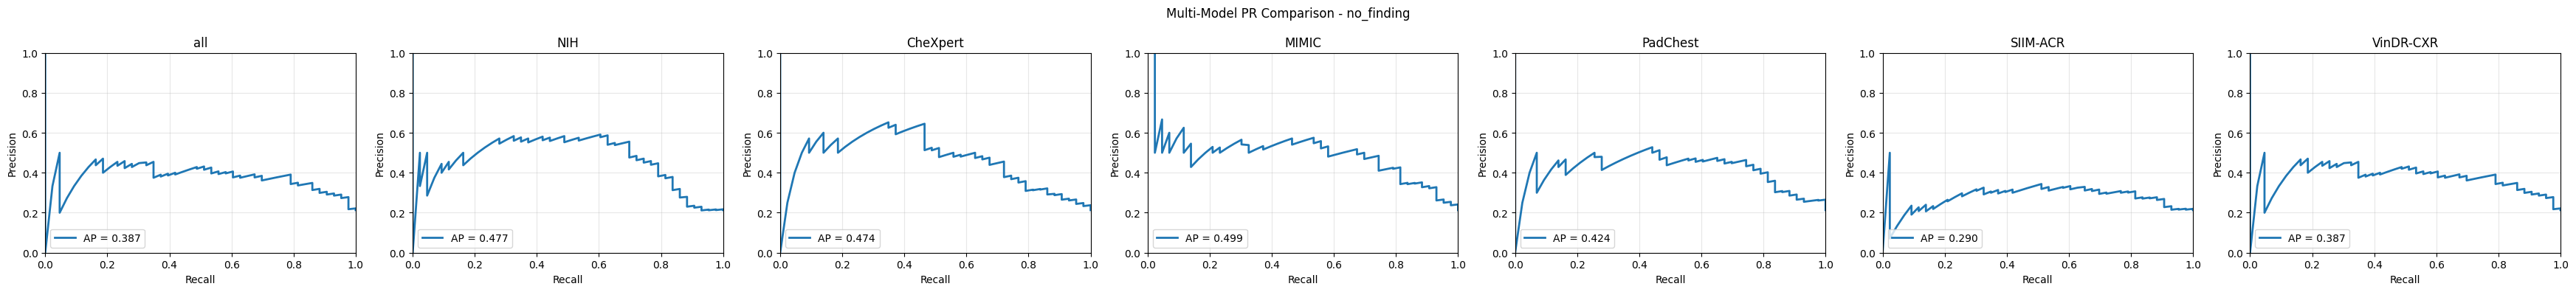

📈 Plotting Multi-Model ROC Curves with Datasets...
Saved plot: results/sms_external_validation2/multi_model_roc_with_datasets_pneumothorax.png


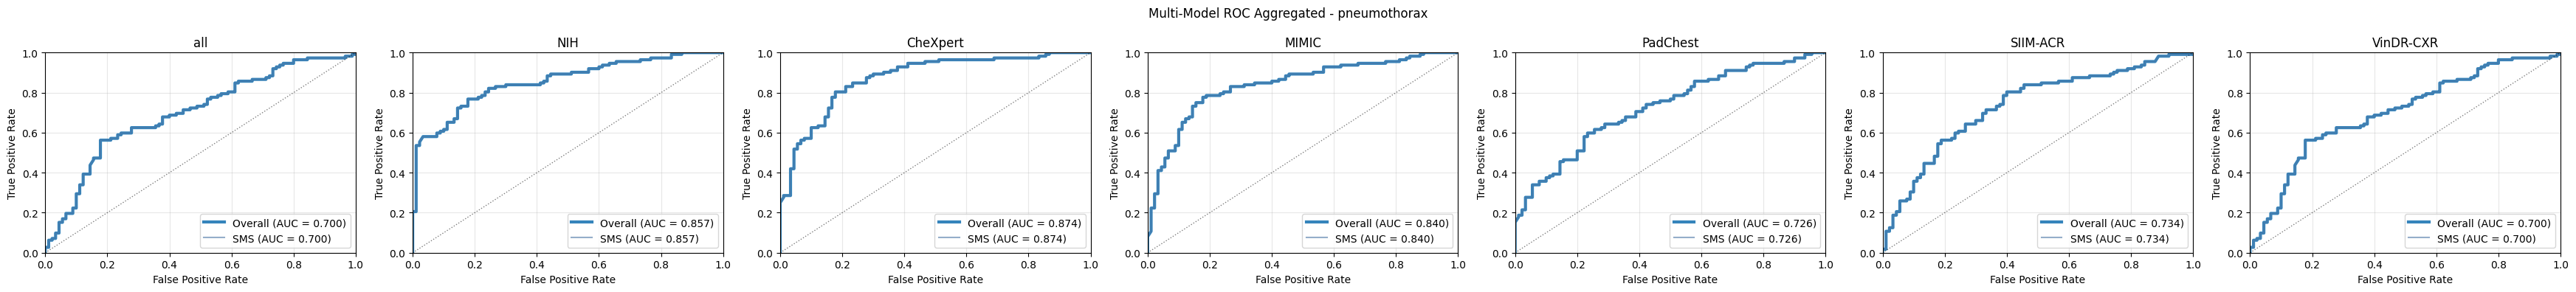

cxr/evaluate.py:3214: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower right")


Saved plot: results/sms_external_validation2/multi_model_roc_with_datasets_support_devices.png


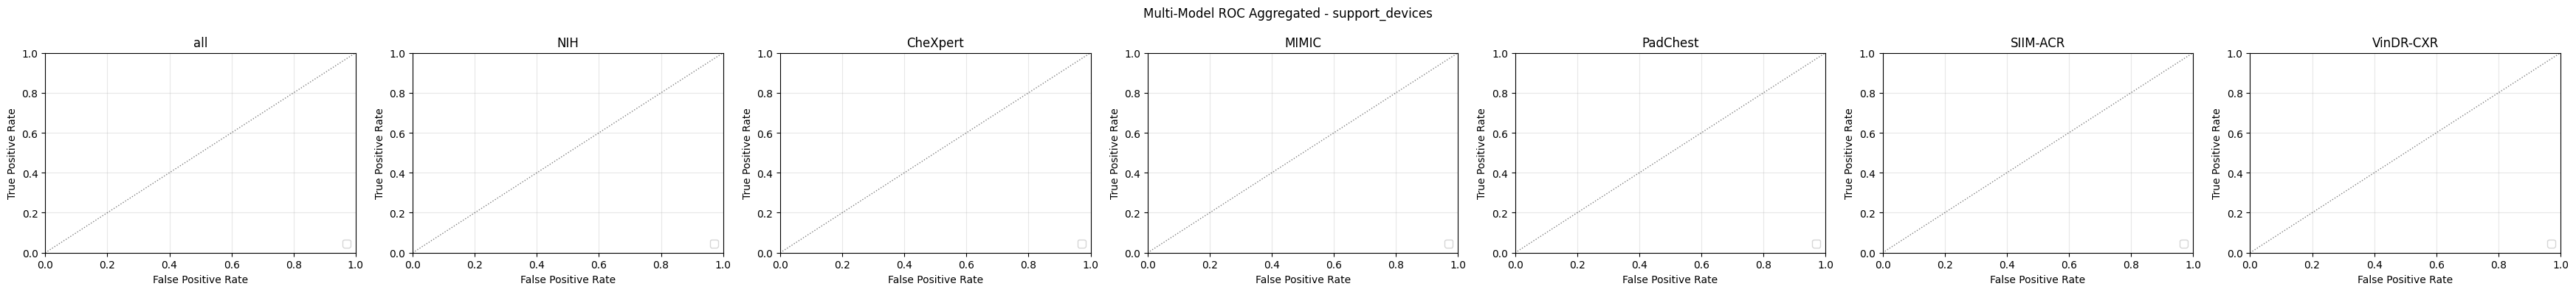

Saved plot: results/sms_external_validation2/multi_model_roc_with_datasets_no_finding.png


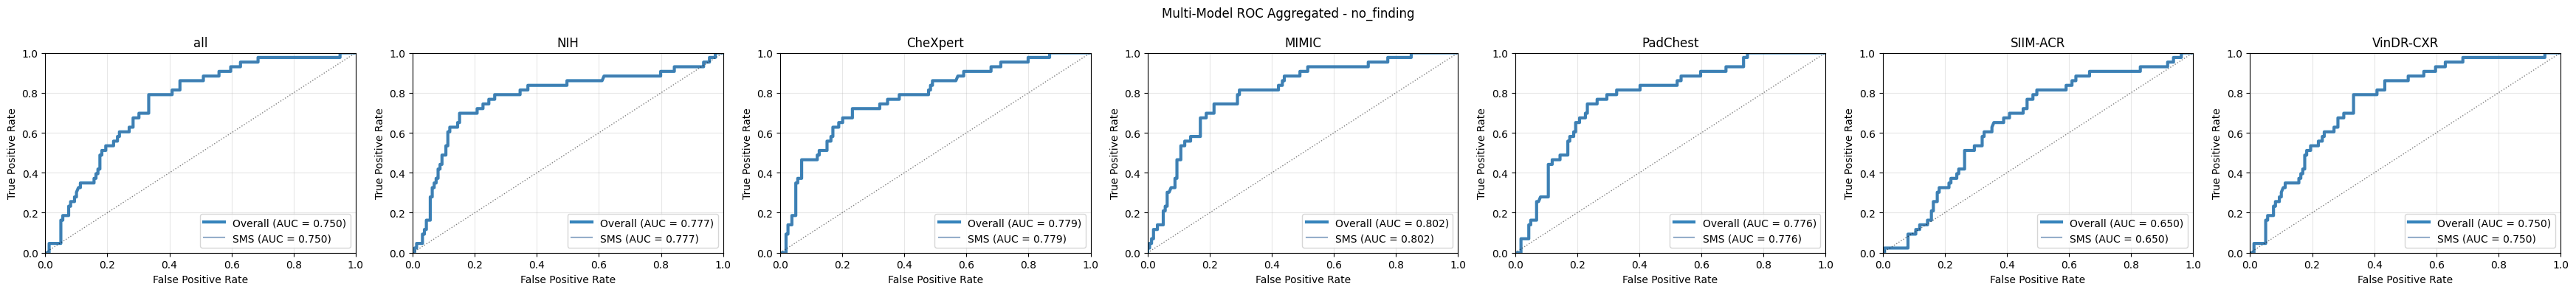

📈 Plotting Multi-Model PR Curves with Datasets...
Saved plot: results/sms_external_validation2/multi_model_pr_with_datasets_pneumothorax.png


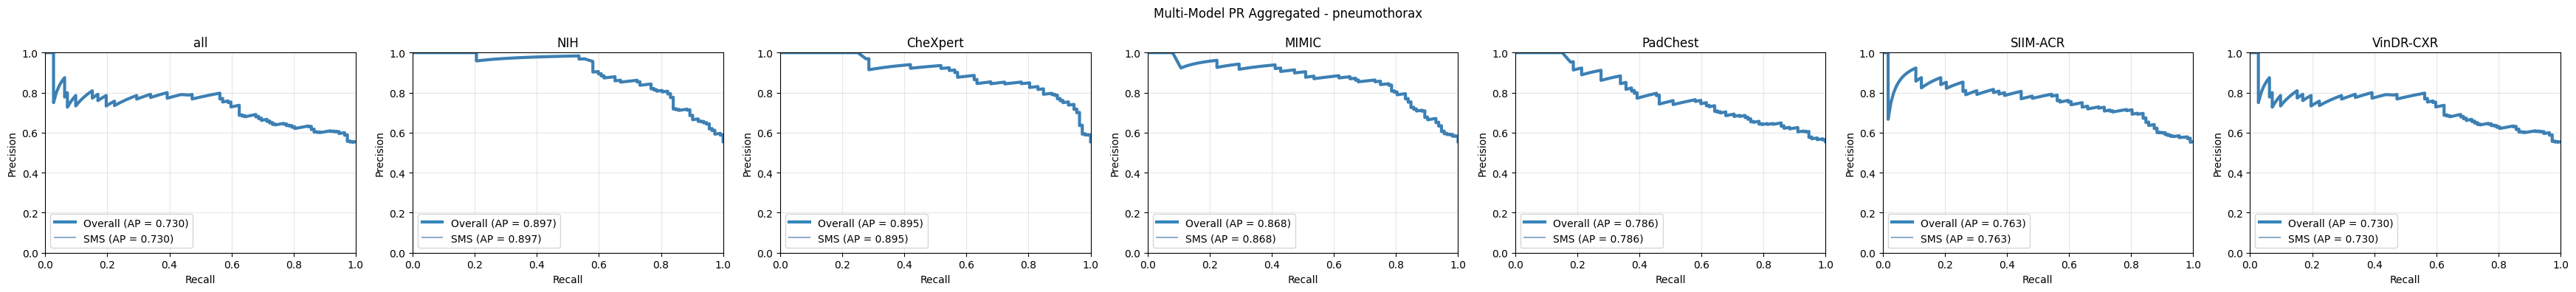

cxr/evaluate.py:3441: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower left")


Saved plot: results/sms_external_validation2/multi_model_pr_with_datasets_support_devices.png


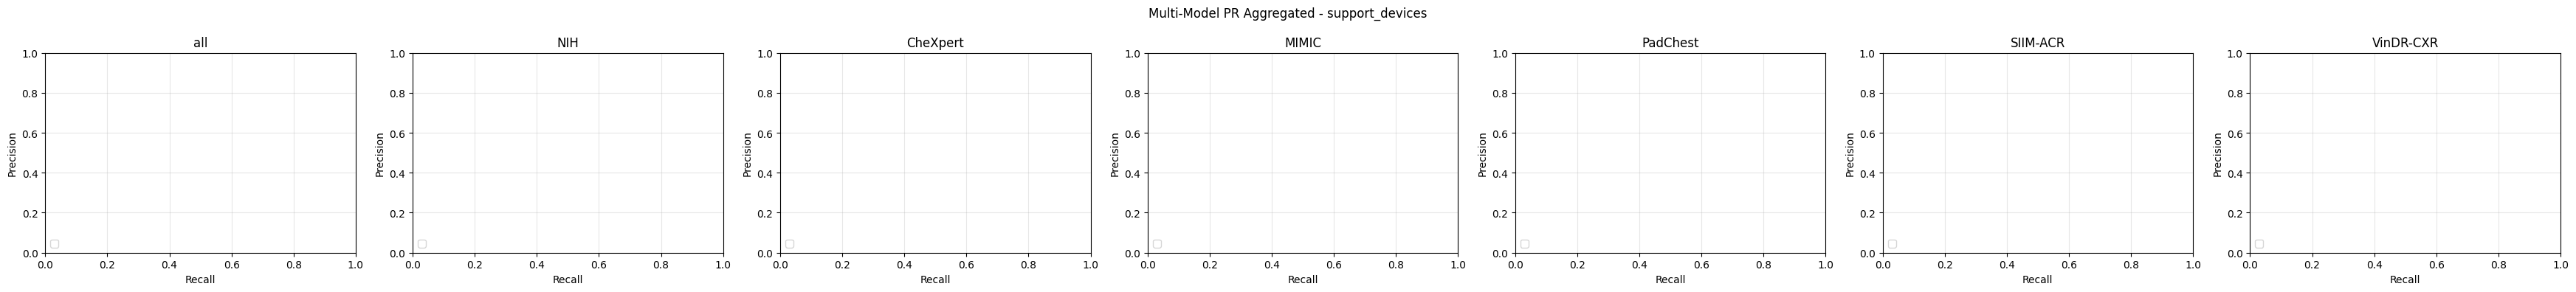

Saved plot: results/sms_external_validation2/multi_model_pr_with_datasets_no_finding.png


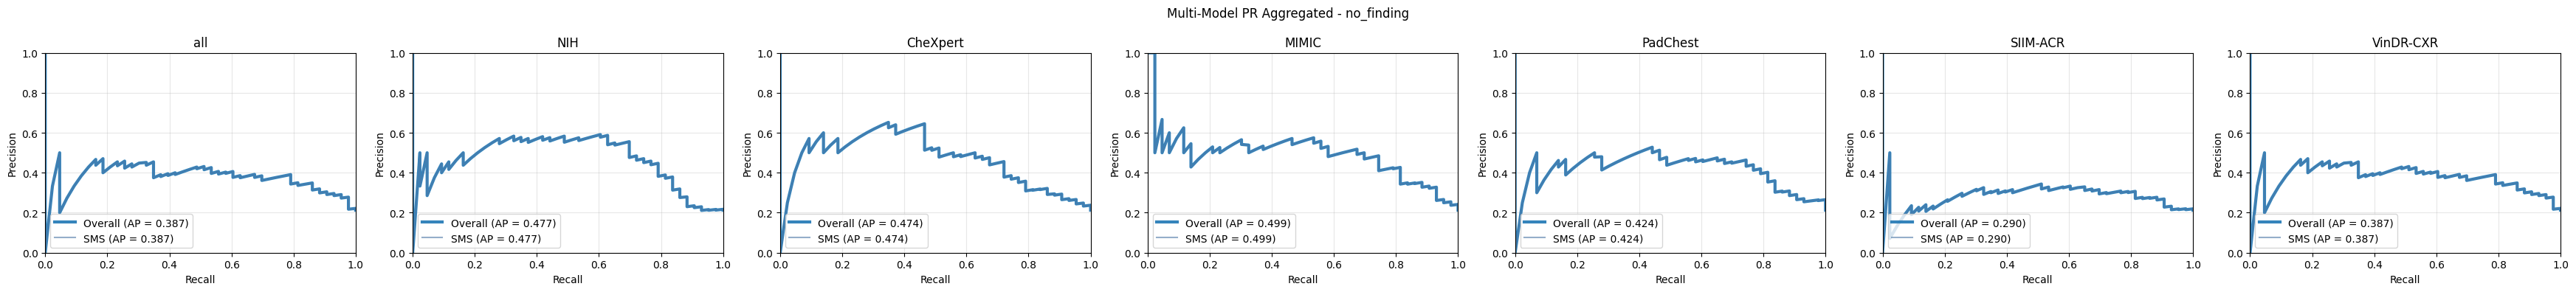

📊 Plotting Multi-Model Comparison - AUC...
Saved plot: results/sms_external_validation2/multi_model_comparison_AUC_pneumothorax.png


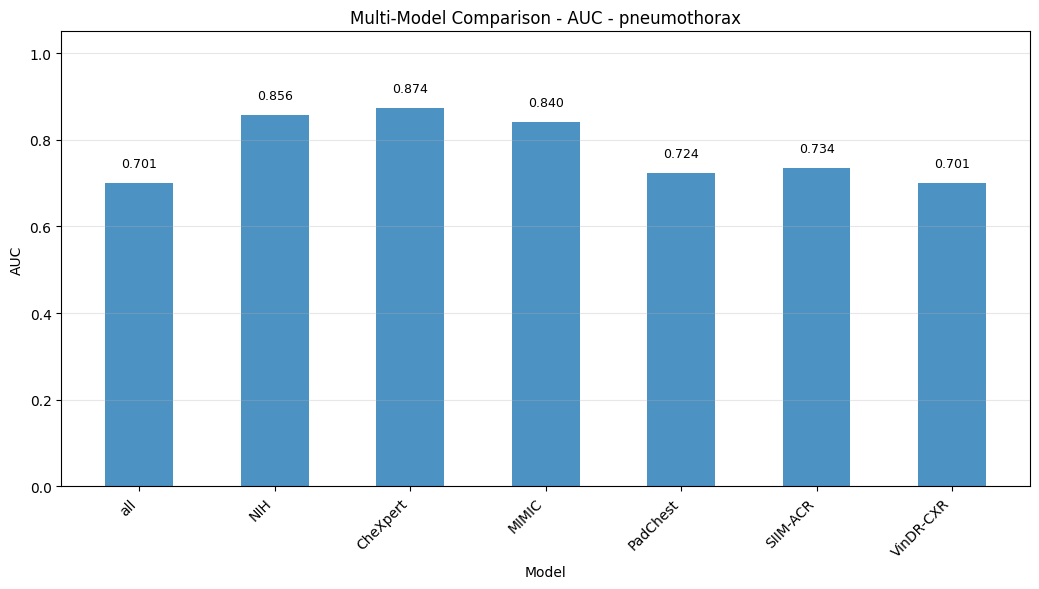

Saved plot: results/sms_external_validation2/multi_model_comparison_AUC_support_devices.png


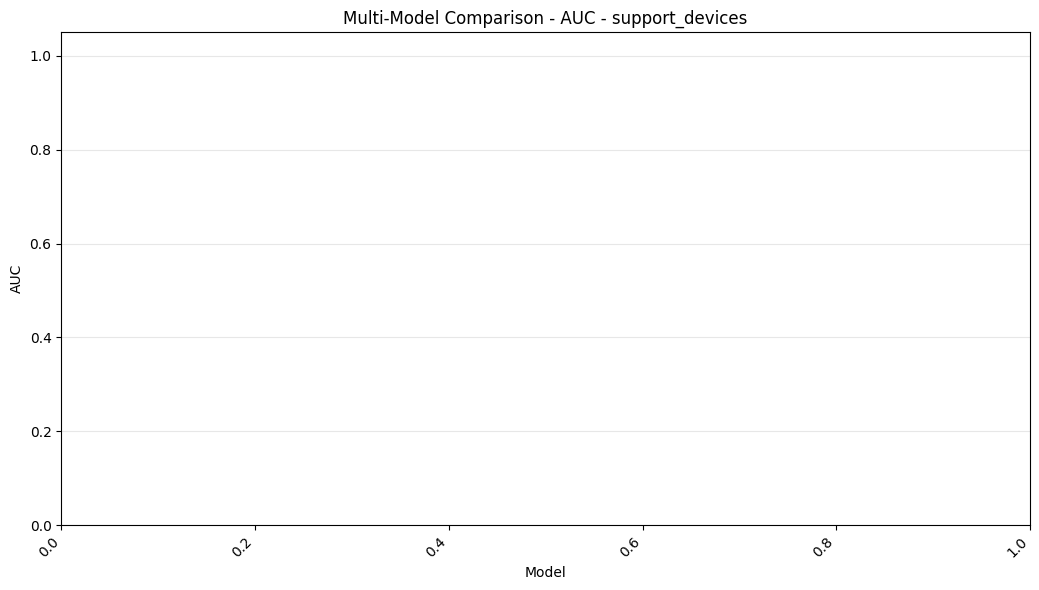

Saved plot: results/sms_external_validation2/multi_model_comparison_AUC_no_finding.png


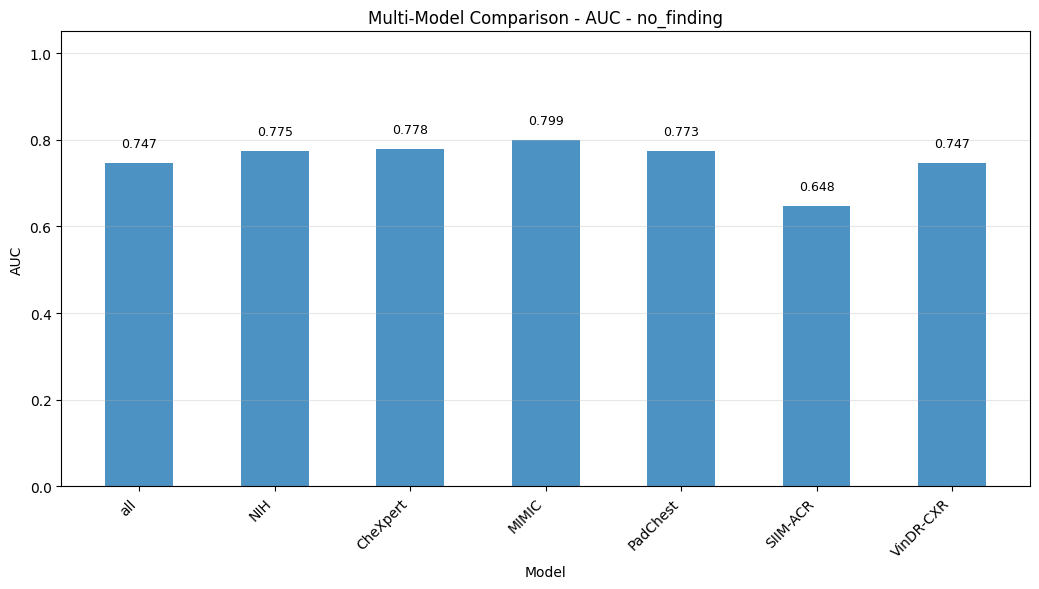

📊 Plotting Multi-Model Comparison - AP...
Saved plot: results/sms_external_validation2/multi_model_comparison_AP_pneumothorax.png


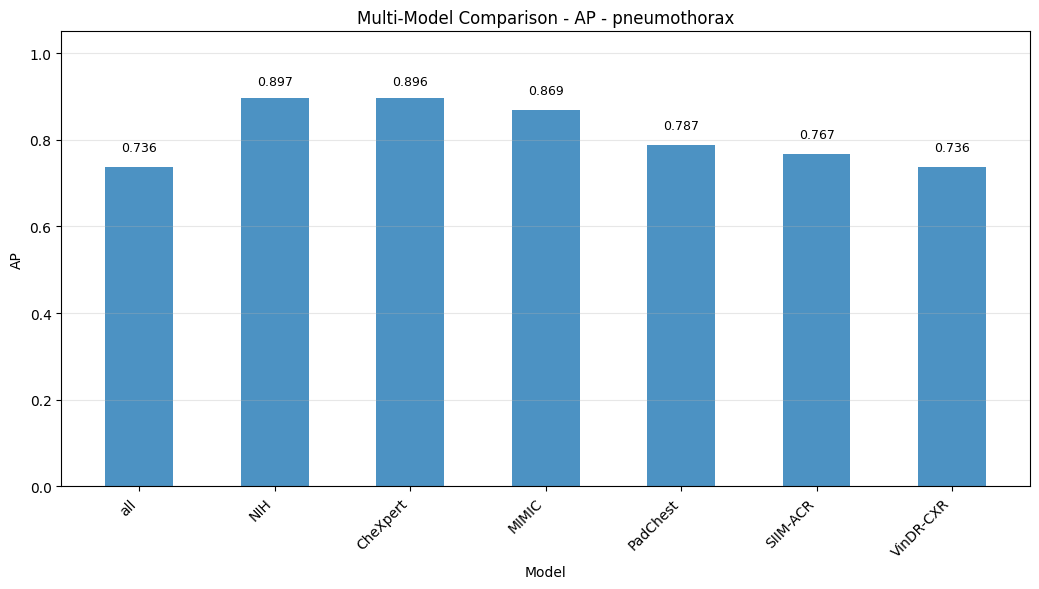

Saved plot: results/sms_external_validation2/multi_model_comparison_AP_support_devices.png


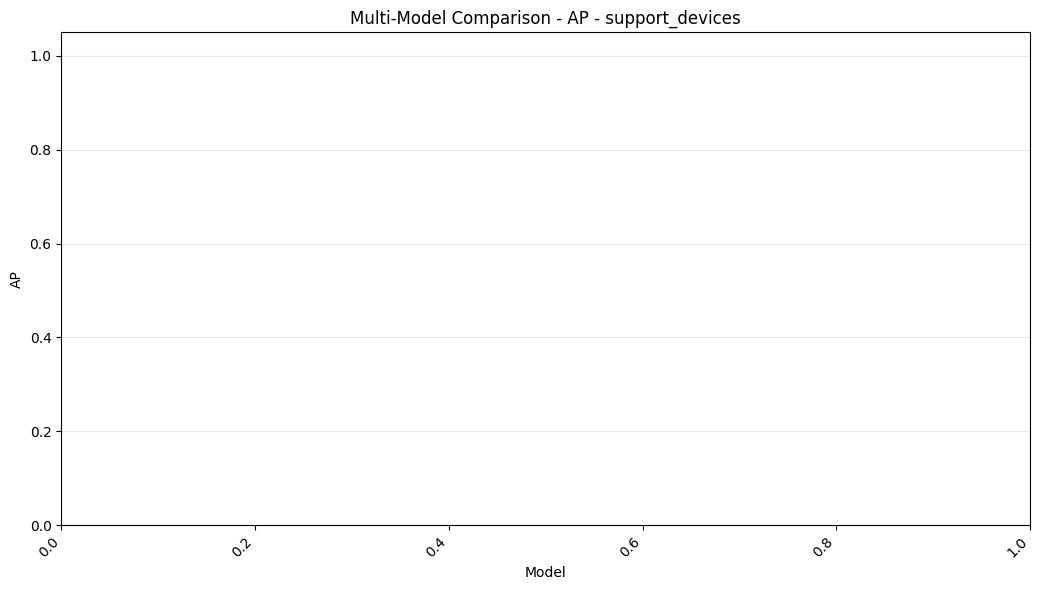

Saved plot: results/sms_external_validation2/multi_model_comparison_AP_no_finding.png


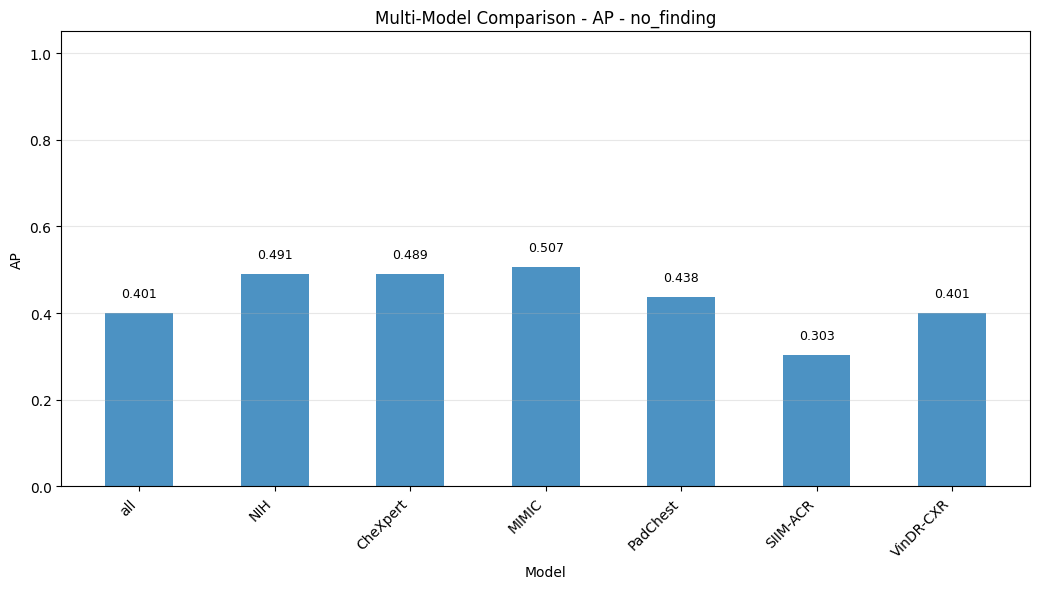

📊 Plotting Multi-Model Comparison - F1-score...
Saved plot: results/sms_external_validation2/multi_model_comparison_F1-score_pneumothorax.png


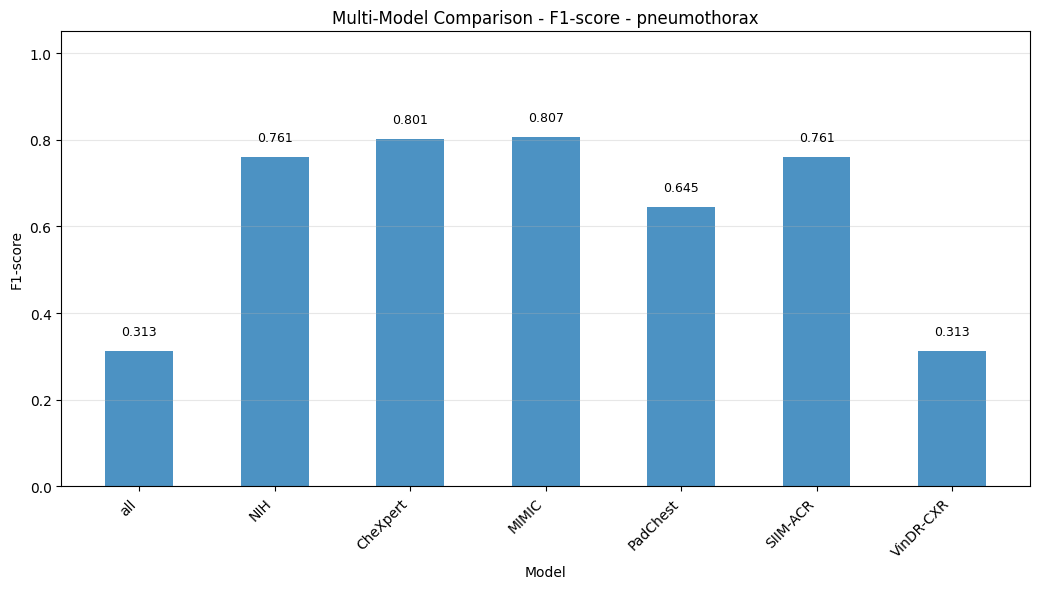

Saved plot: results/sms_external_validation2/multi_model_comparison_F1-score_support_devices.png


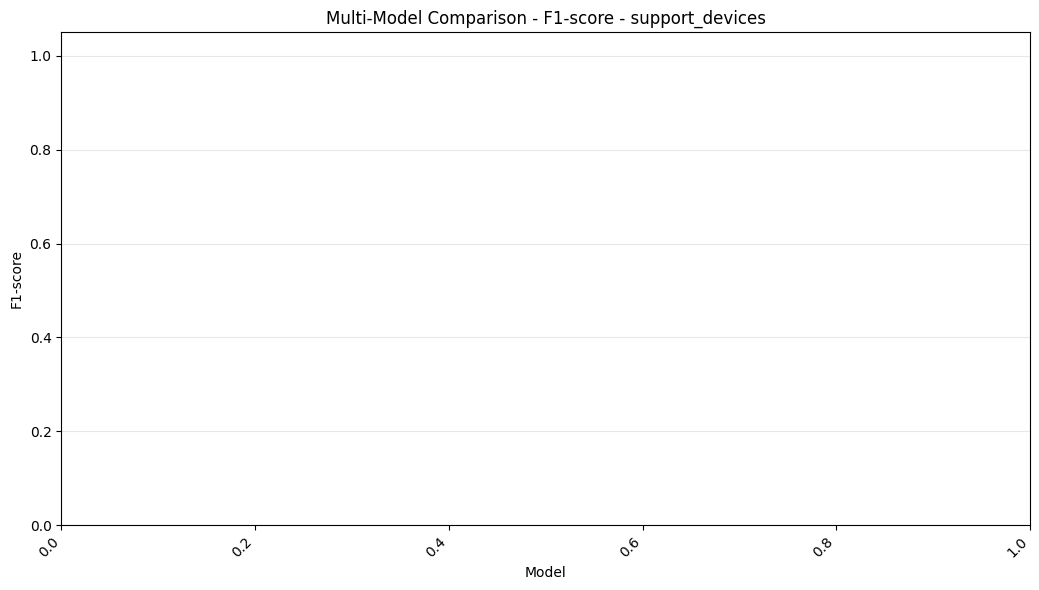

Saved plot: results/sms_external_validation2/multi_model_comparison_F1-score_no_finding.png


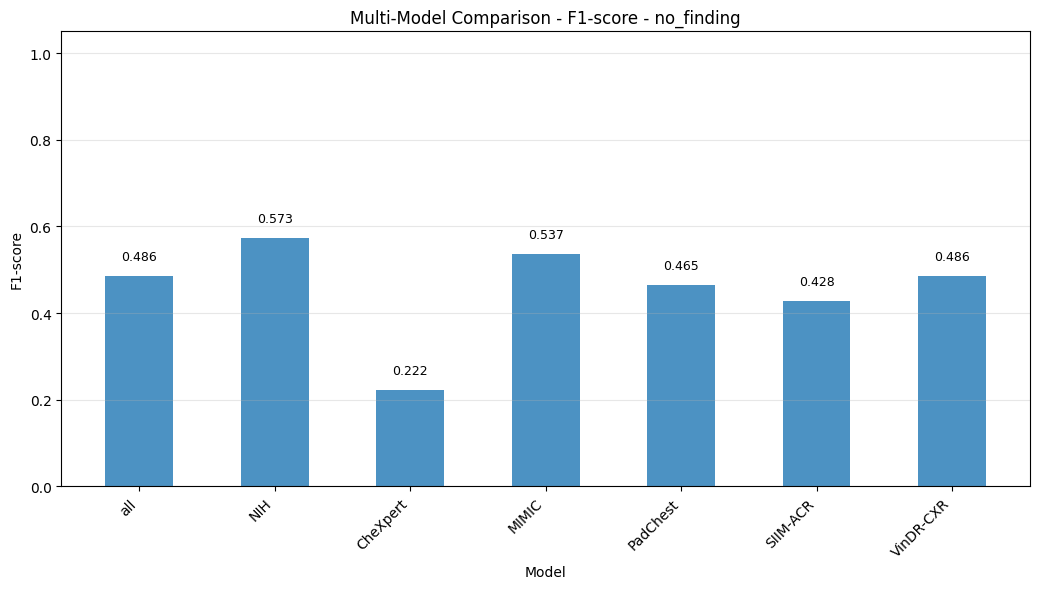

📊 Plotting Multi-Model Comparison - Sensitivity (Recall)...
Saved plot: results/sms_external_validation2/multi_model_comparison_Sensitivity_Recall_pneumothorax.png


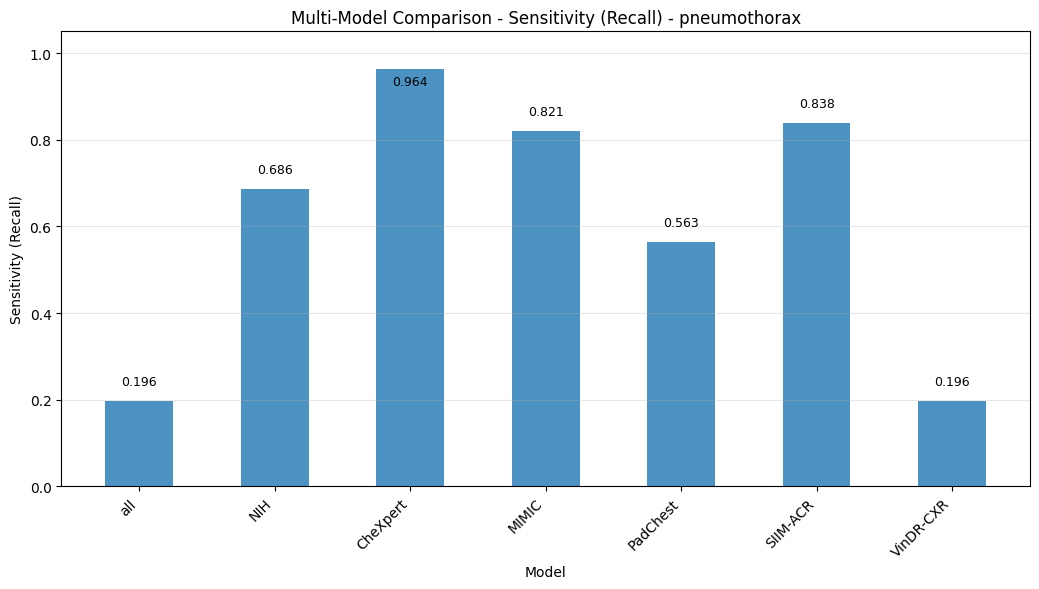

Saved plot: results/sms_external_validation2/multi_model_comparison_Sensitivity_Recall_support_devices.png


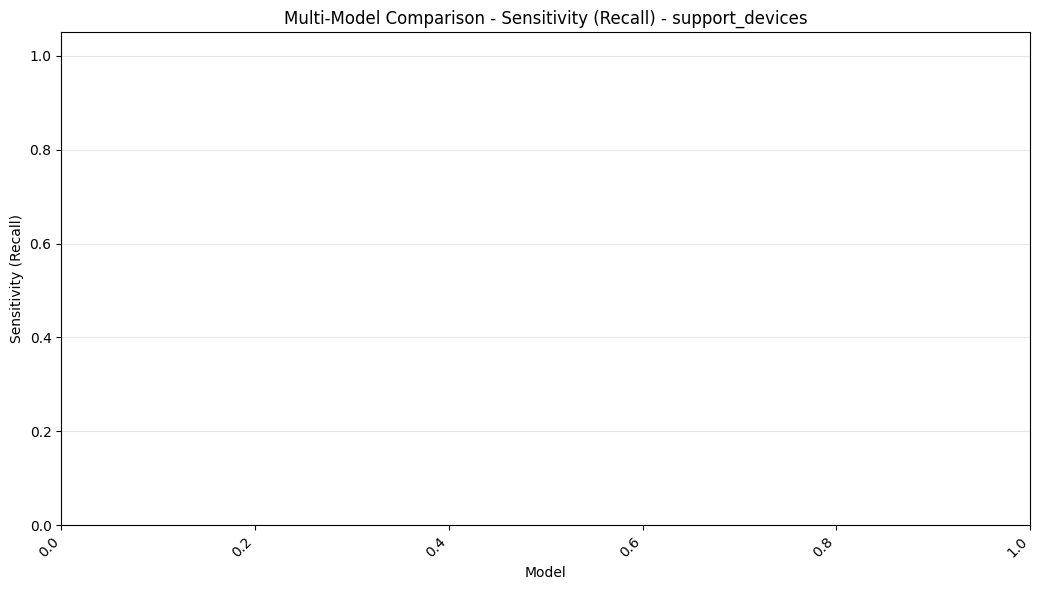

Saved plot: results/sms_external_validation2/multi_model_comparison_Sensitivity_Recall_no_finding.png


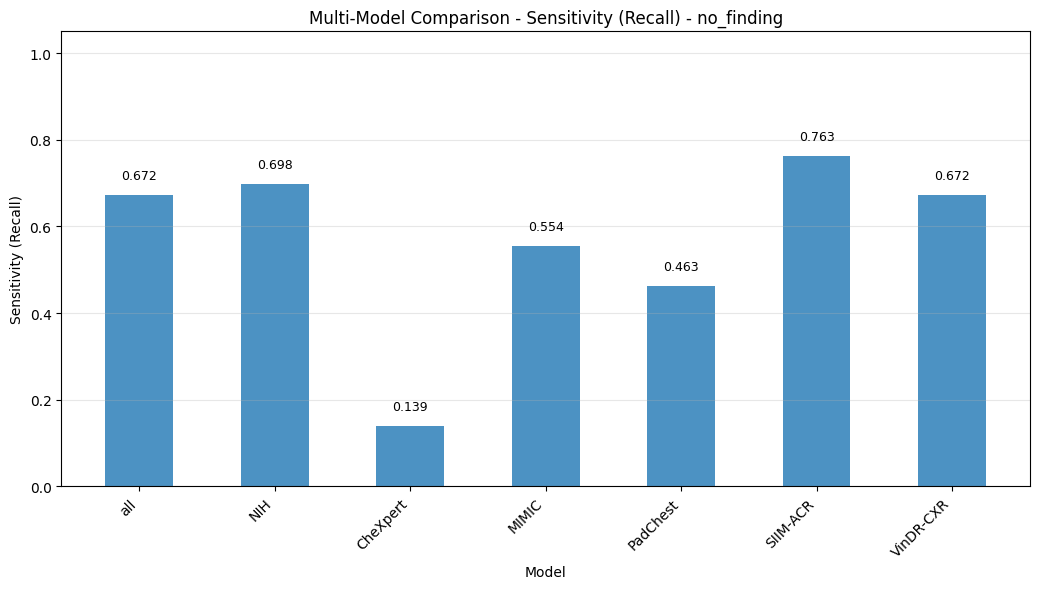

📊 Plotting Multi-Model Comparison - PPV (Precision)...
Saved plot: results/sms_external_validation2/multi_model_comparison_PPV_Precision_pneumothorax.png


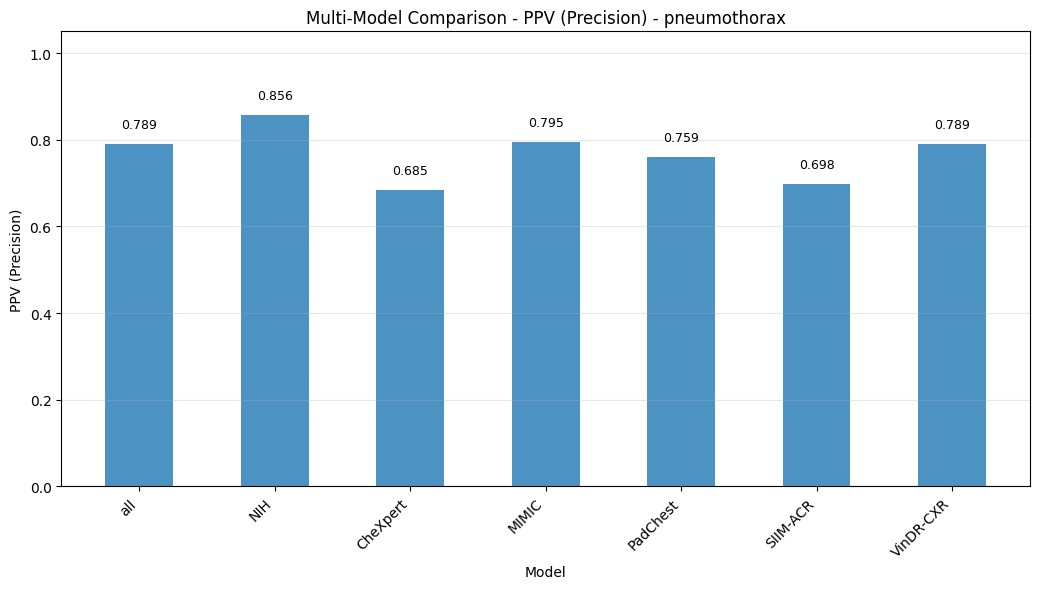

Saved plot: results/sms_external_validation2/multi_model_comparison_PPV_Precision_support_devices.png


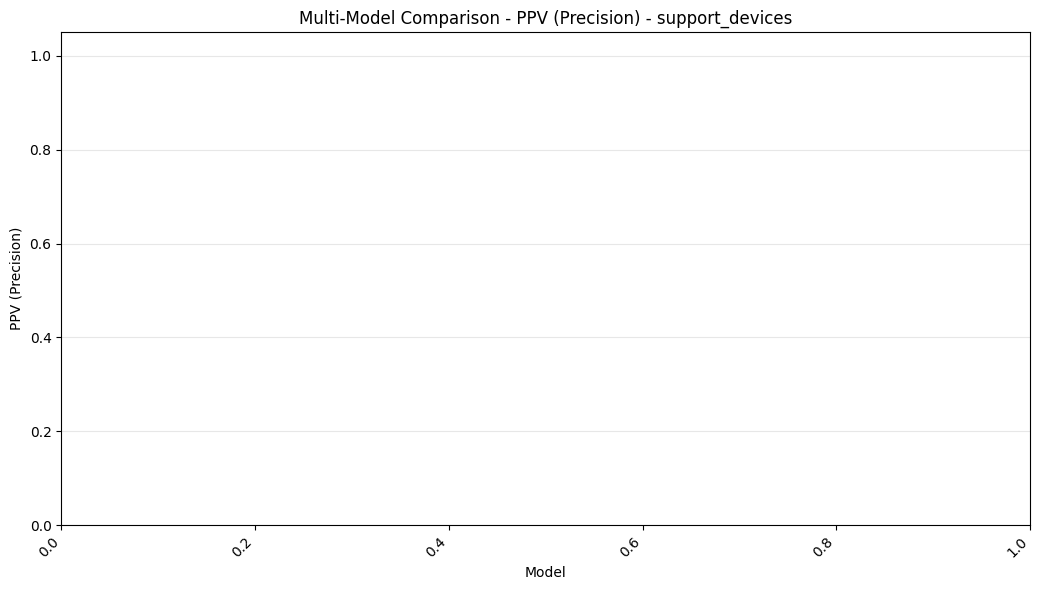

Saved plot: results/sms_external_validation2/multi_model_comparison_PPV_Precision_no_finding.png


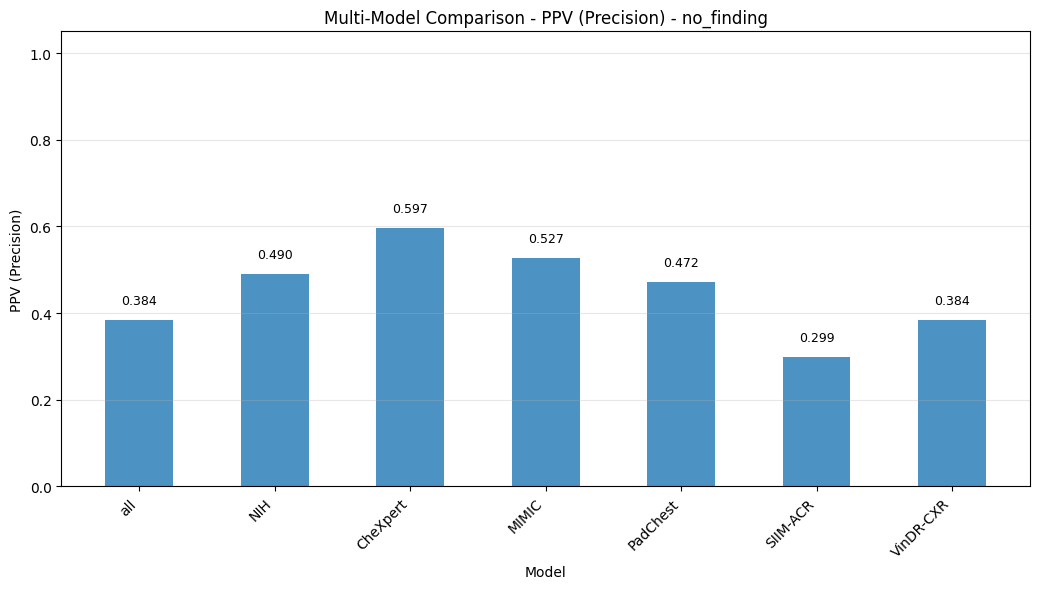

📊 Plotting Multi-Model Comparison - Specificity...
Saved plot: results/sms_external_validation2/multi_model_comparison_Specificity_pneumothorax.png


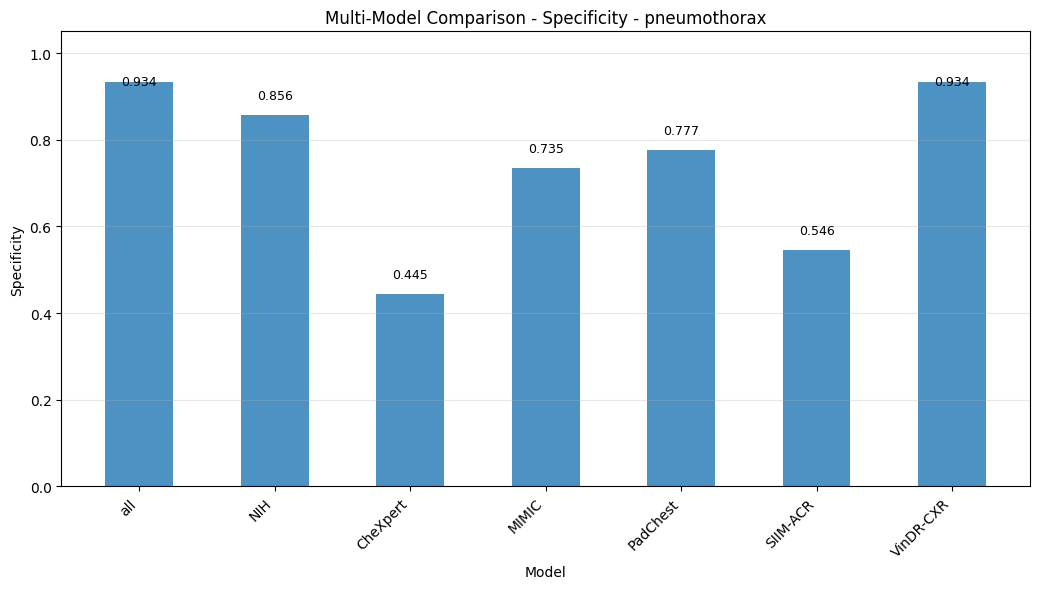

Saved plot: results/sms_external_validation2/multi_model_comparison_Specificity_support_devices.png


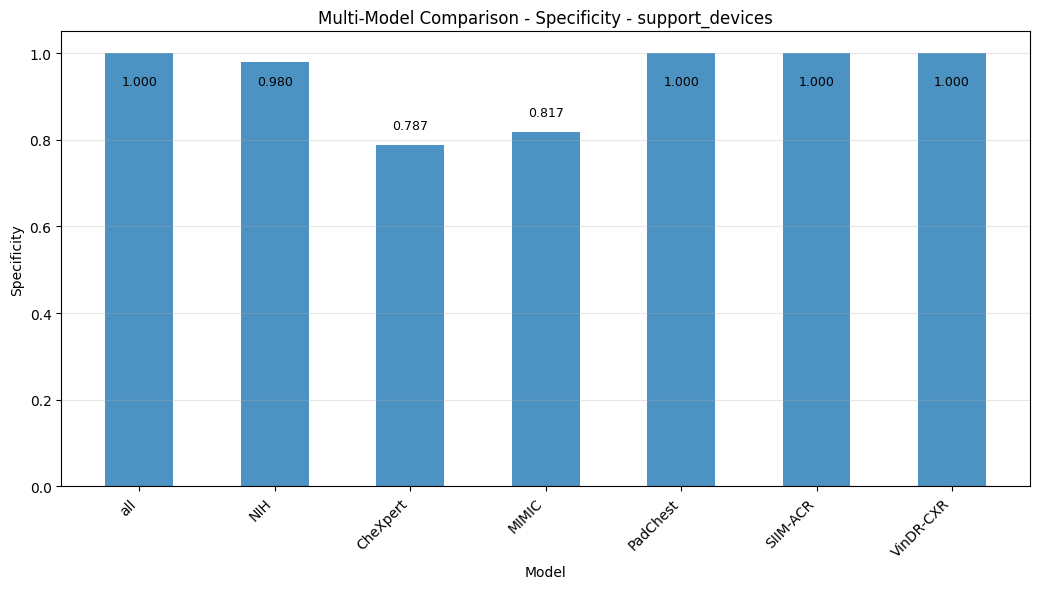

Saved plot: results/sms_external_validation2/multi_model_comparison_Specificity_no_finding.png


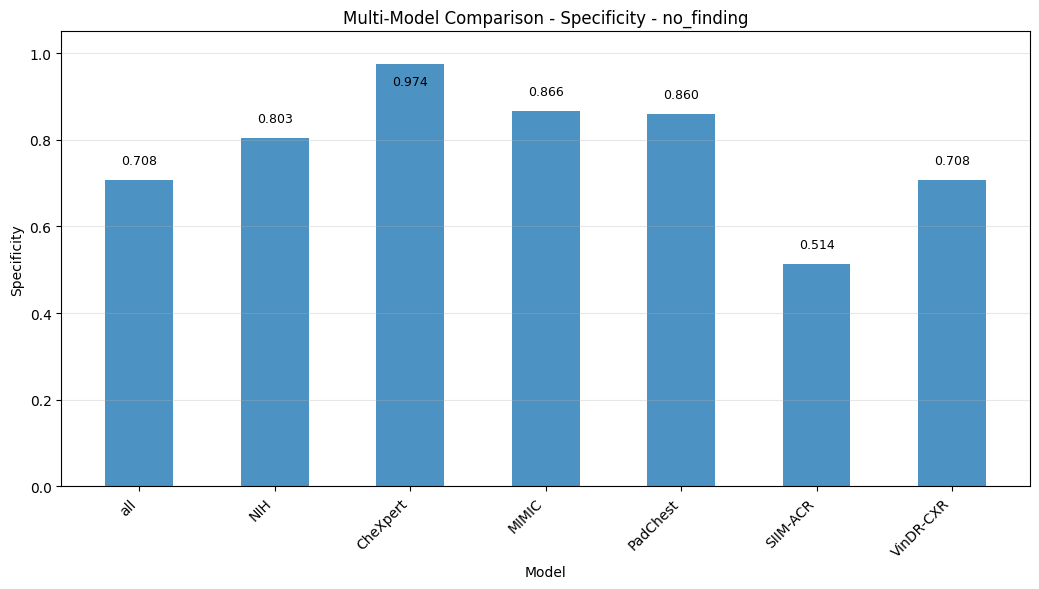

📊 Plotting Multi-Model Comparison - NPV...
Saved plot: results/sms_external_validation2/multi_model_comparison_NPV_pneumothorax.png


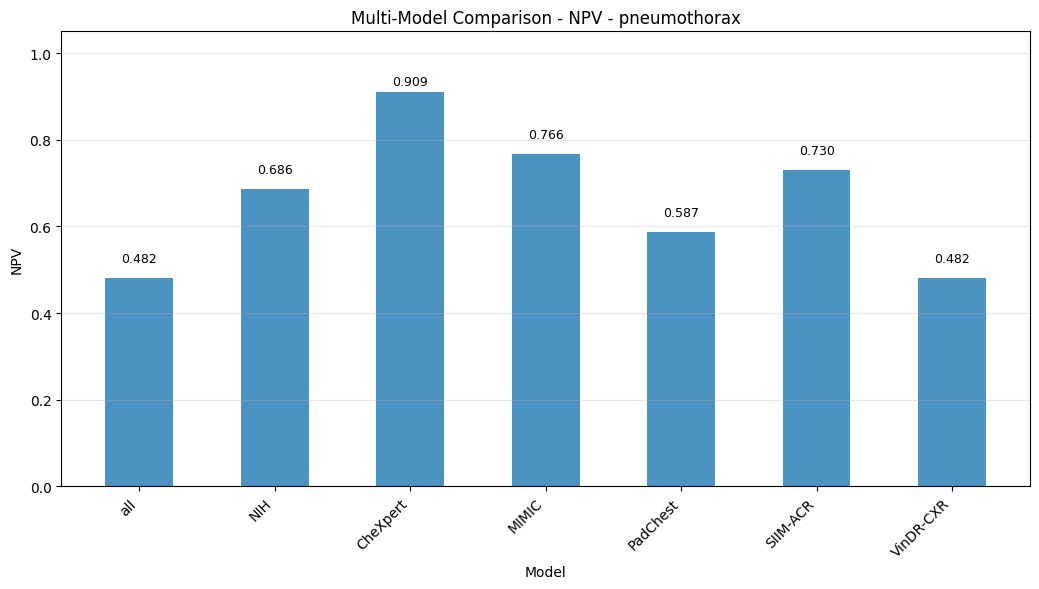

Saved plot: results/sms_external_validation2/multi_model_comparison_NPV_support_devices.png


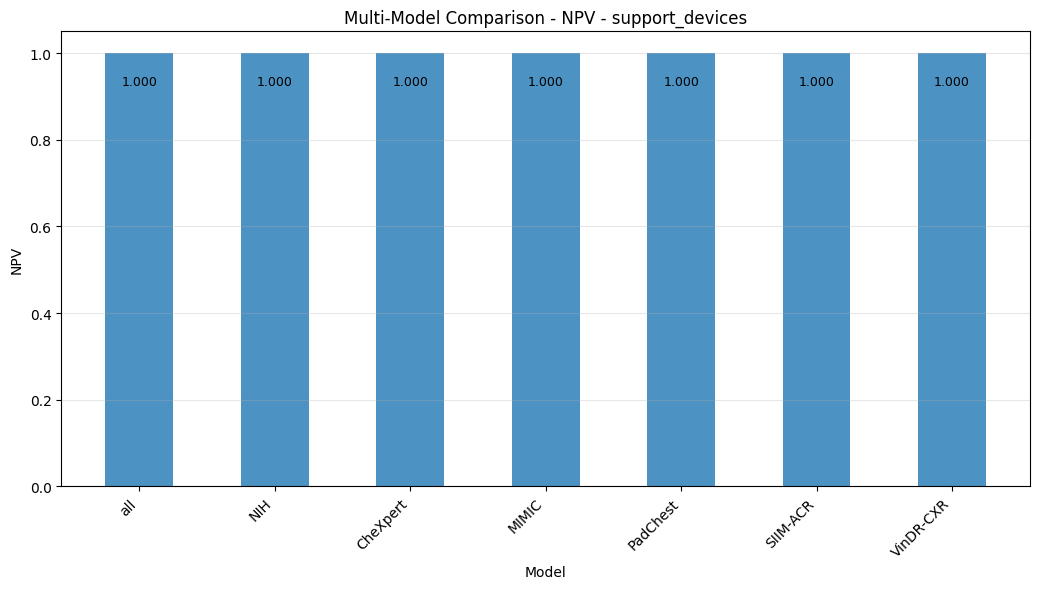

Saved plot: results/sms_external_validation2/multi_model_comparison_NPV_no_finding.png


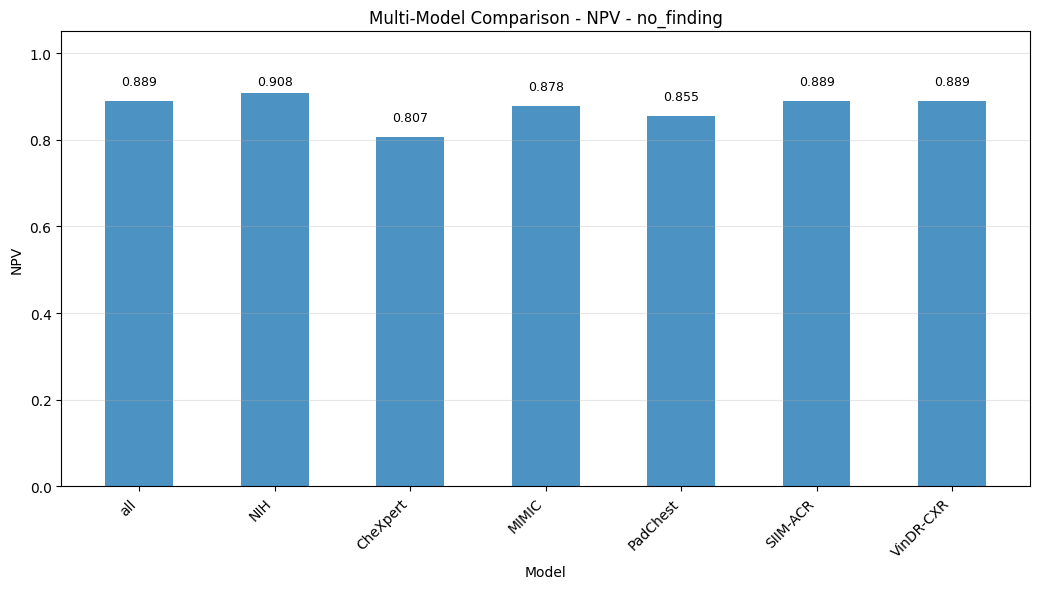

📊 Plotting Multi-Model Comprehensive Comparison...
Saved plot: results/sms_external_validation2/multi_model_comprehensive_pneumothorax.png


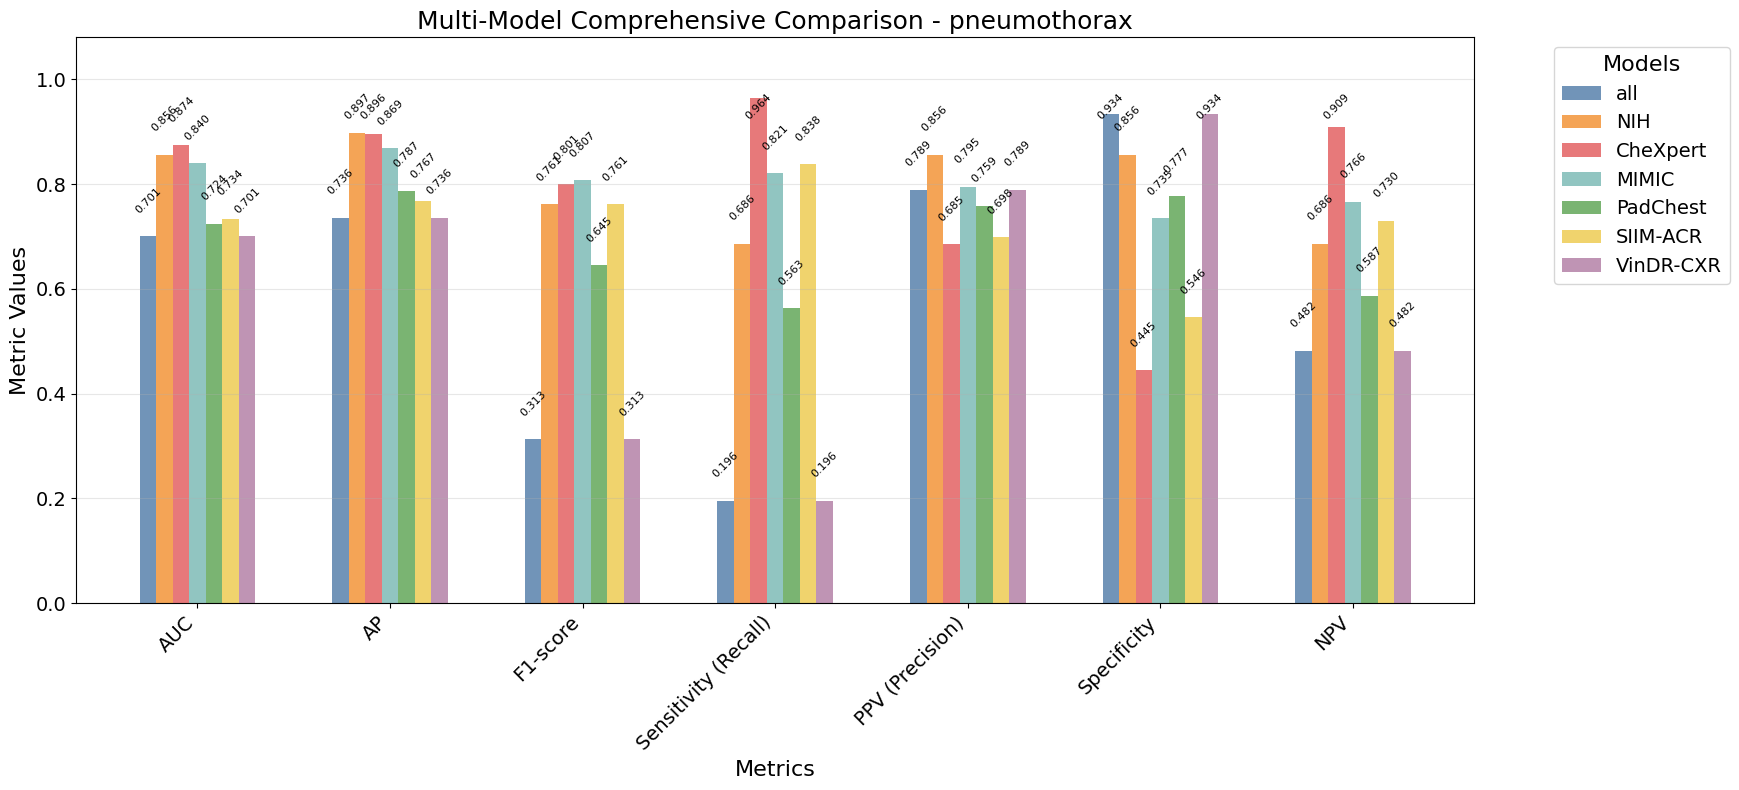

Saved plot: results/sms_external_validation2/multi_model_comprehensive_support_devices.png


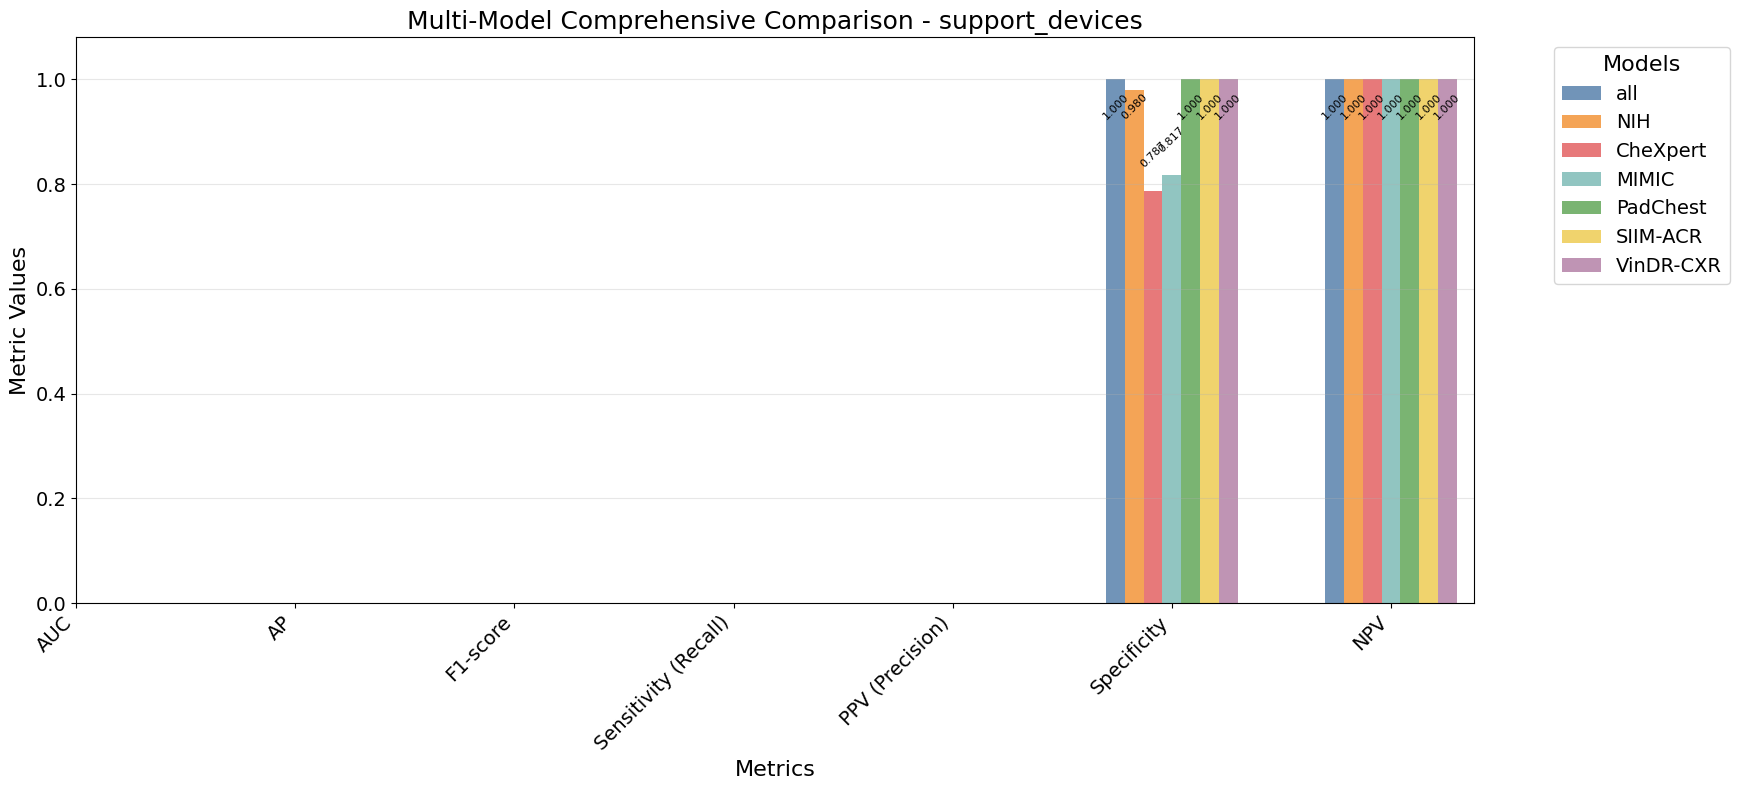

Saved plot: results/sms_external_validation2/multi_model_comprehensive_no_finding.png


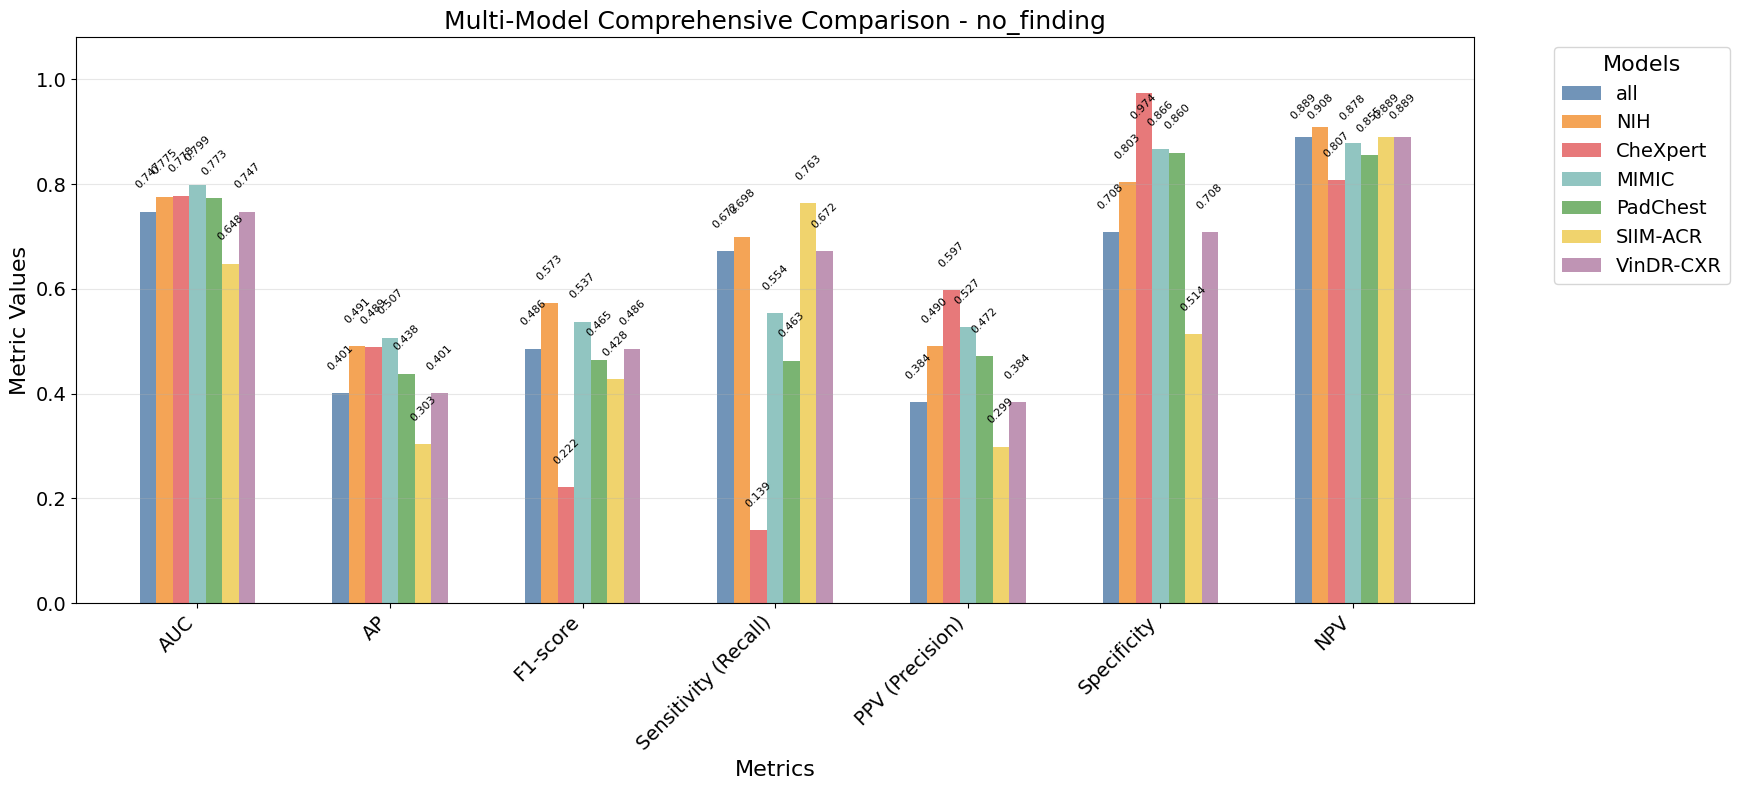

📊 Plotting Multi-Model Confusion Matrices...
Saved plot: results/sms_external_validation2/multi_model_confusion_matrices_pneumothorax.png


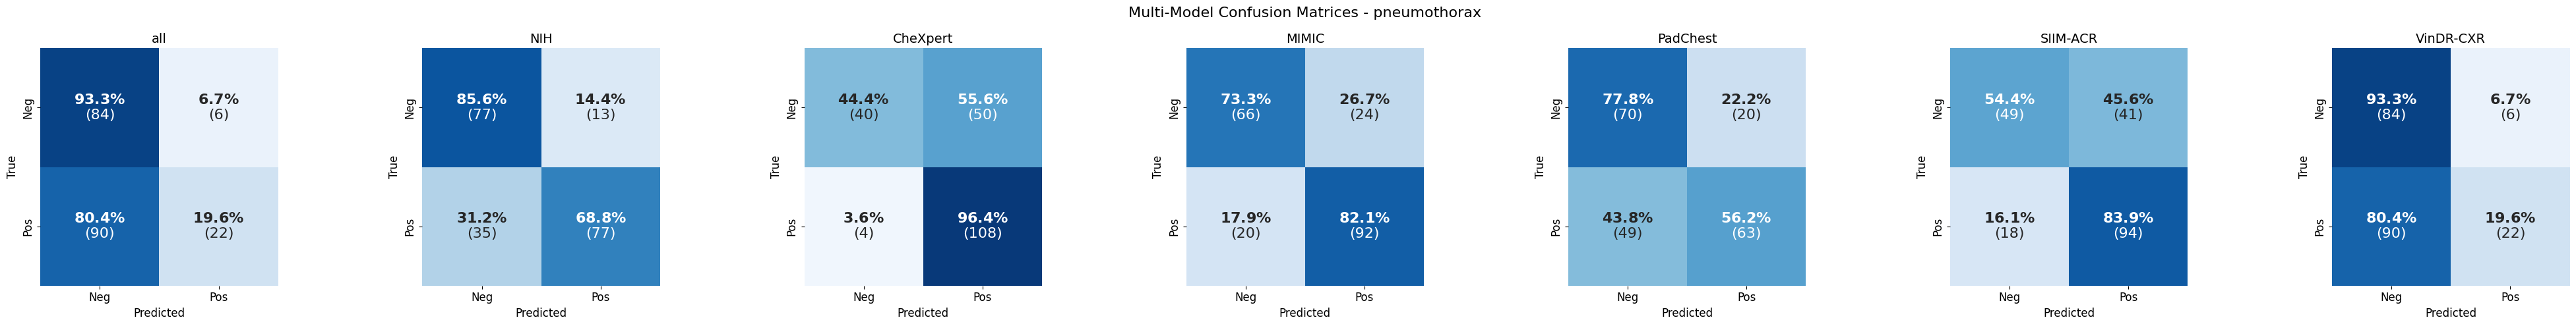

Saved plot: results/sms_external_validation2/multi_model_confusion_matrices_support_devices.png


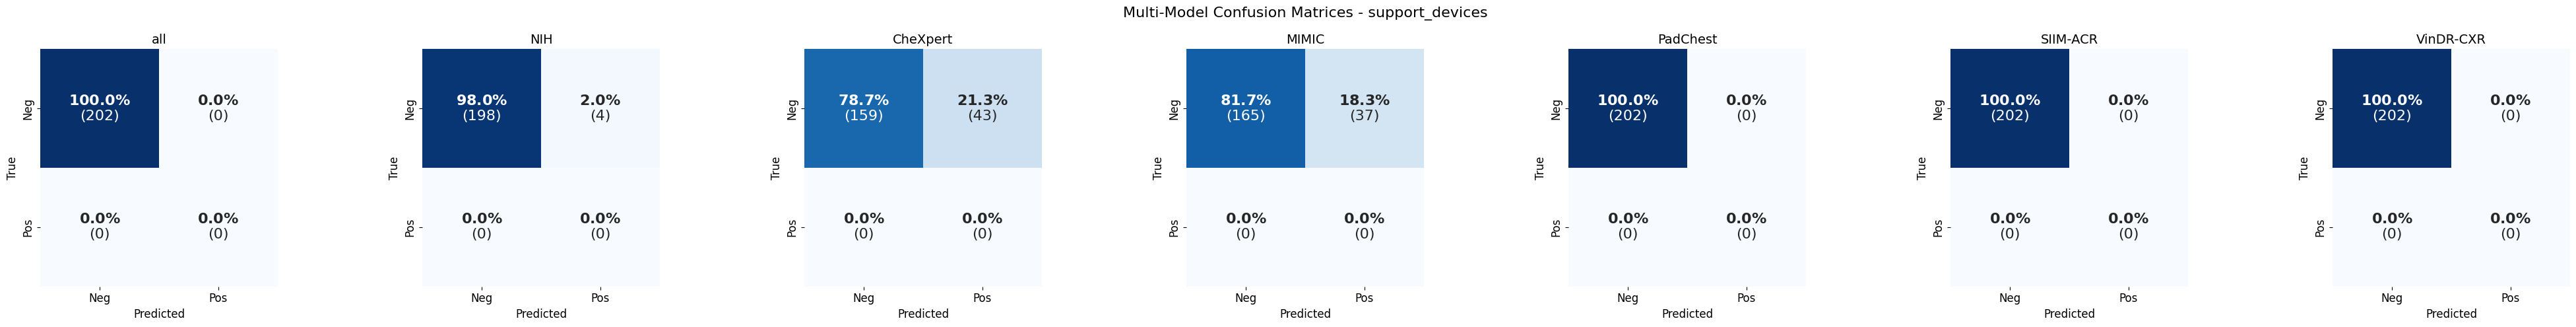

Saved plot: results/sms_external_validation2/multi_model_confusion_matrices_no_finding.png


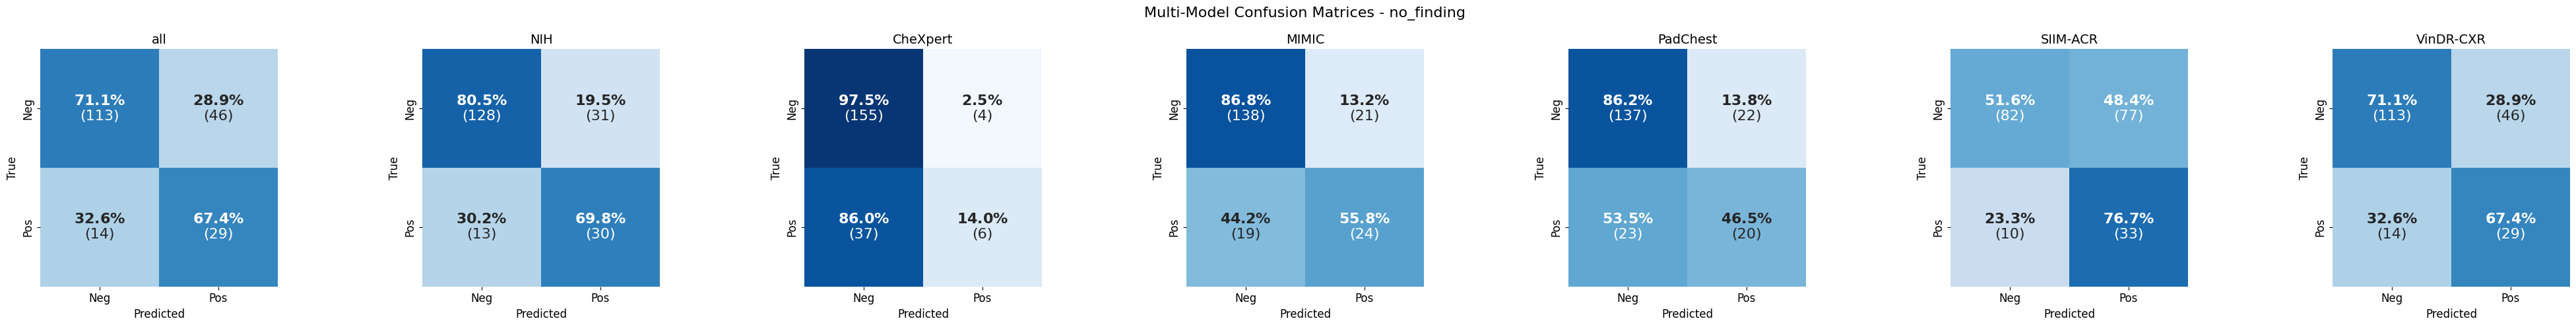

📊 Plotting Multi-Model Dataset Confusion Matrices...


cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/sms_external_validation2/multi_model_dataset_confusion_matrices_pneumothorax.png


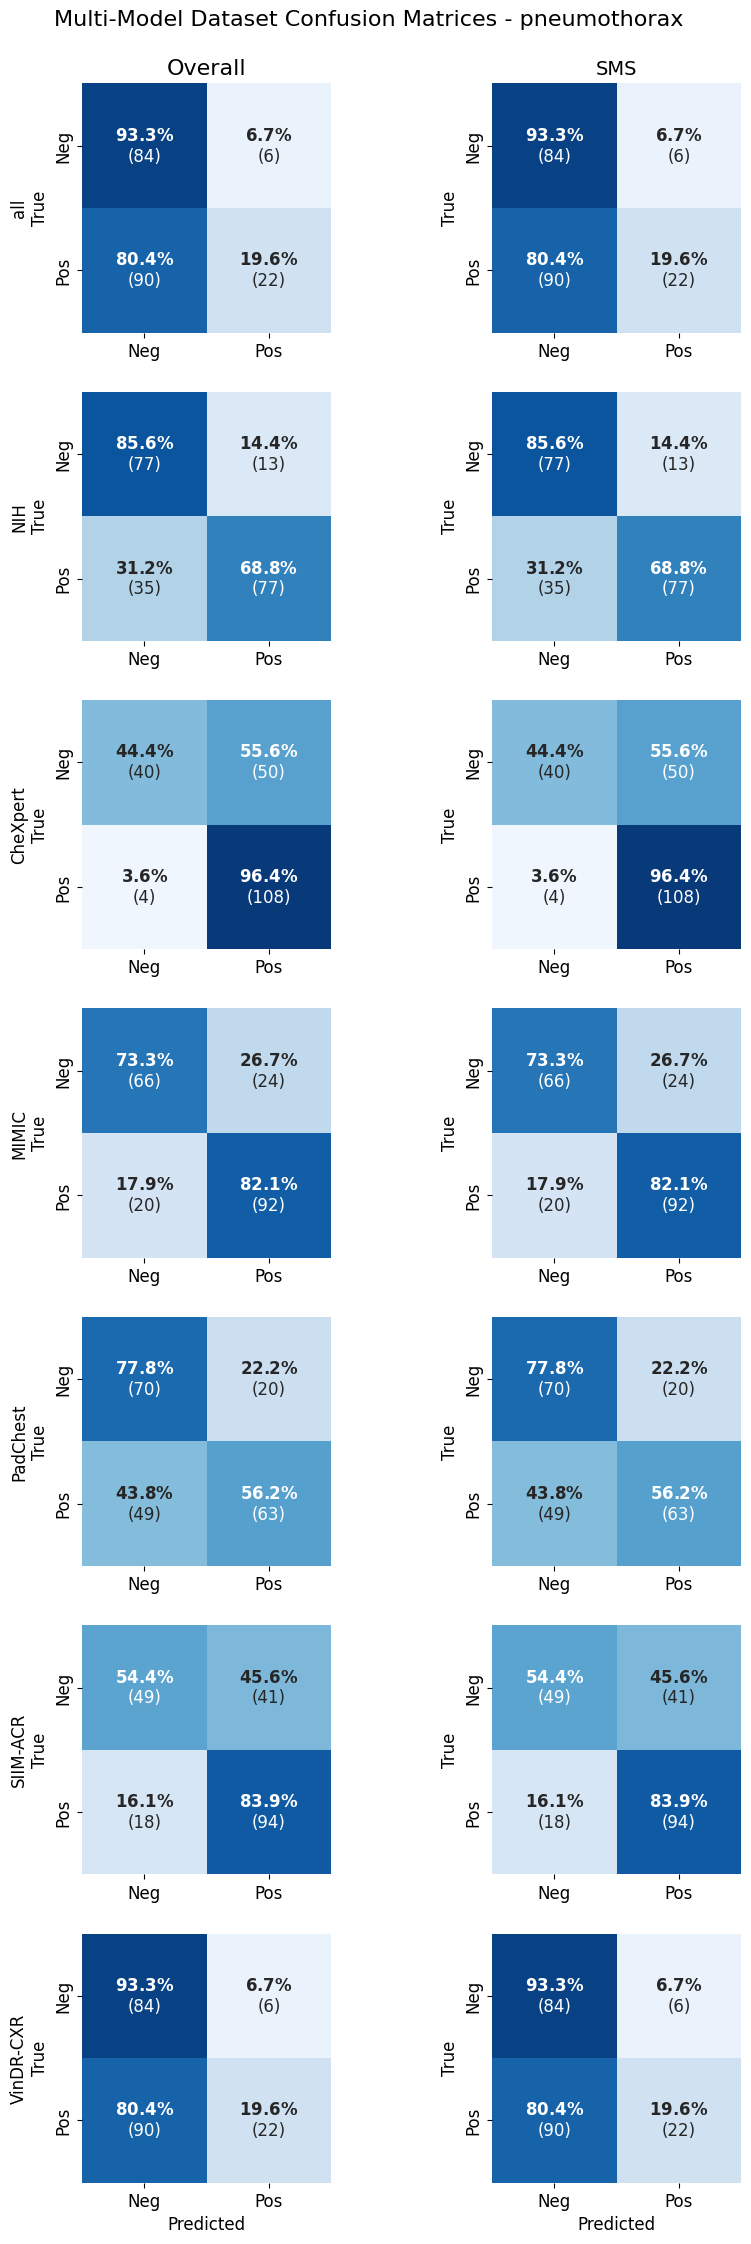

cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/sms_external_validation2/multi_model_dataset_confusion_matrices_support_devices.png


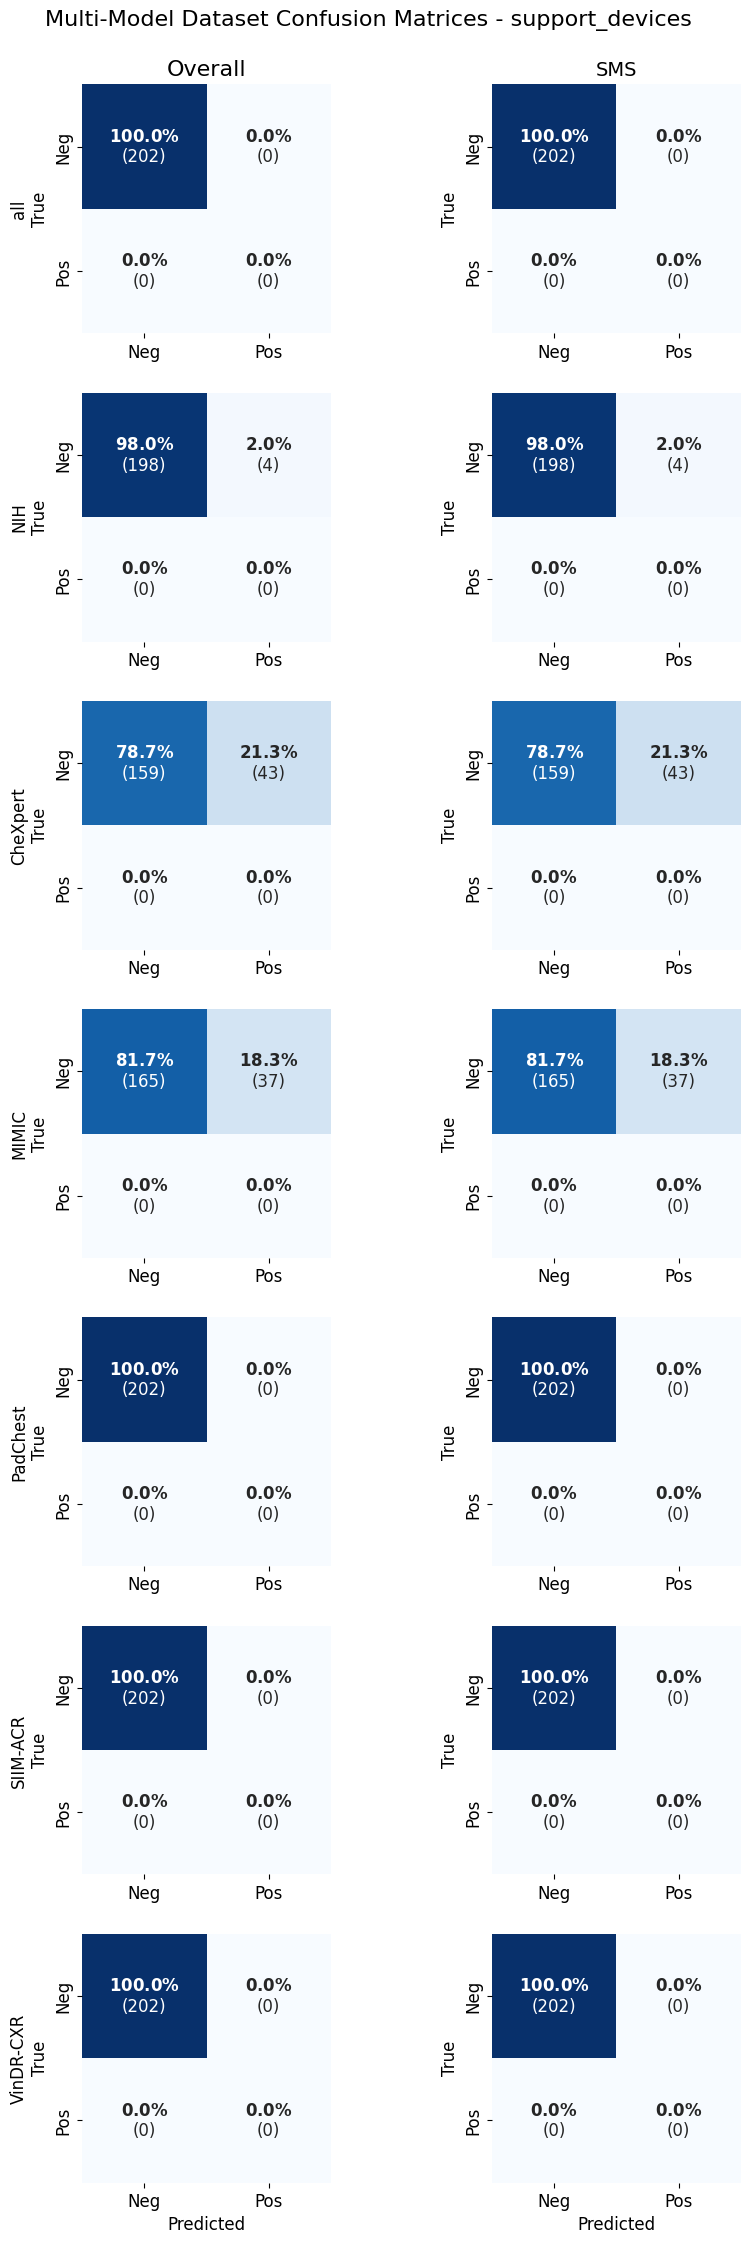

cxr/evaluate.py:116: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


Saved plot: results/sms_external_validation2/multi_model_dataset_confusion_matrices_no_finding.png


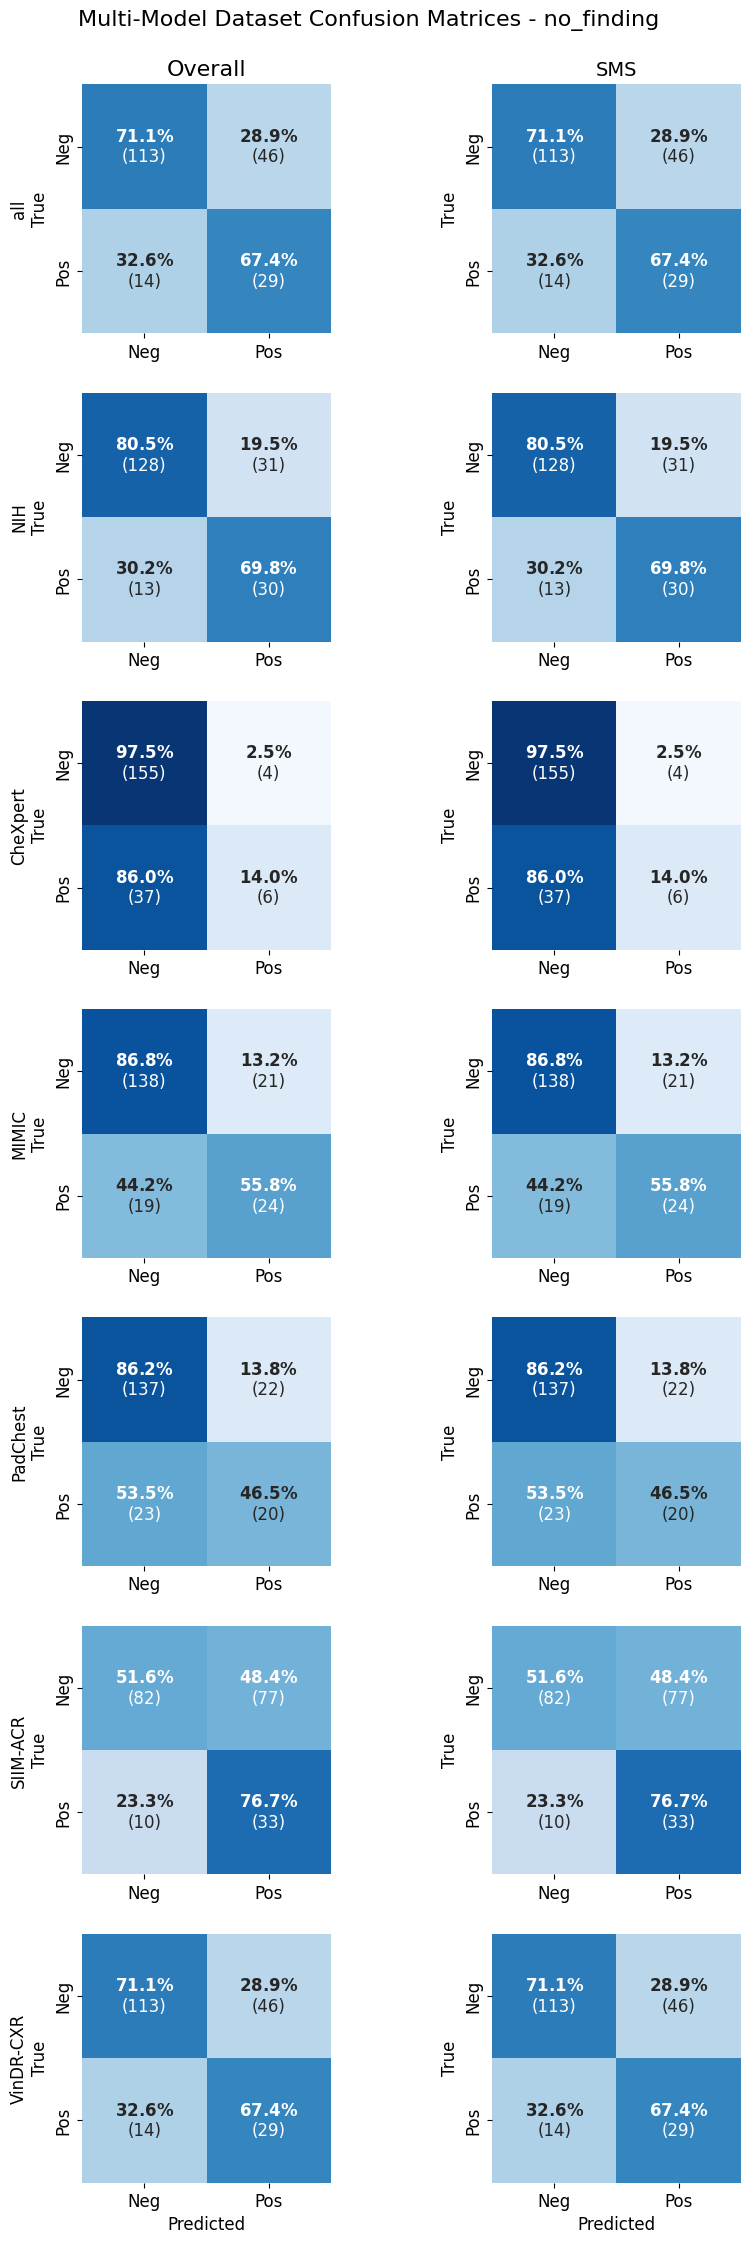


MULTI-MODEL COMPARISON SUMMARY
📊 Aggregated 7 models
📈 Generated ROC and PR comparison plots
📈 Generated ROC and PR plots with individual datasets
📊 Generated comparison plots for 7 metrics
📊 Generated confusion matrix comparison plots
💾 All results saved to: results/sms_external_validation2


In [111]:
# Update aggregated metrics if needed
from cxr.evaluate import aggregate_and_compare_models
updated_aggregation = aggregate_and_compare_models(
    model_results=individual_results,
    class_names=class_names,
    save_dir="results/sms_external_validation2",
    log_wandb=False,
    display=True,
    comparison_metrics=[]
)

In [ ]:
image_paths = 

In [114]:
import matplotlib.pyplot as plt
import numpy as np

def get_model_errors(y_true, y_probs, image_paths, class_names, threshold=0.5, top_k=10, images_per_row=5, show_errors=True):
    y_pred = (y_probs >= threshold).astype(int)
    errors = {}

    for i, class_name in enumerate(class_names):
        fp_idx = np.where((y_pred[:, i] == 1) & (y_true[:, i] == 0))[0]
        fn_idx = np.where((y_pred[:, i] == 0) & (y_true[:, i] == 1))[0]

        errors[class_name] = {
            "false_positives": [(image_paths[idx], y_probs[idx, i]) for idx in fp_idx],
            "false_negatives": [(image_paths[idx], y_probs[idx, i]) for idx in fn_idx],
        }

        if show_errors:
            print(f"\n🧪 Class: {class_name}")
            print(f"  ❌ False Positives: {len(fp_idx)} | ❌ False Negatives: {len(fn_idx)}")

            def show_imgs(indices, title):
                n = min(len(indices), top_k)
                rows = (n + images_per_row - 1) // images_per_row
                fig, axes = plt.subplots(rows, images_per_row, figsize=(images_per_row * 3, rows * 3))

                if rows == 1:
                    axes = np.expand_dims(axes, 0)  # make sure it's 2D
                axes = axes.flatten()

                for j in range(n):
                    idx = indices[j]
                    img = plt.imread(image_paths[idx])
                    axes[j].imshow(img, cmap='gray')
                    axes[j].set_title(f"{title}\nConf: {y_probs[idx, i]:.2f}")
                    axes[j].axis("off")

                for ax in axes[n:]:
                    ax.axis("off")

                plt.tight_layout()
                plt.show()

            if len(fp_idx) > 0:
                print("🔺 False Positives:")
                show_imgs(fp_idx, "FP")
            if len(fn_idx) > 0:
                print("🔻 False Negatives:")
                show_imgs(fn_idx, "FN")

    return errors


In [115]:
image_paths = external_test_generator.filepaths  # From ImageDataGenerator

errors = get_model_errors(
    y_true=y_true,
    y_probs=y_probs,
    image_paths=image_paths,
    class_names=class_names,
    threshold=0.2,
    top_k=13
)



🧪 Class: pneumothorax
  ❌ False Positives: 6 | ❌ False Negatives: 90
🔺 False Positives:


<Figure size 1500x600 with 10 Axes>

🔻 False Negatives:


<Figure size 1500x900 with 15 Axes>


🧪 Class: support_devices
  ❌ False Positives: 0 | ❌ False Negatives: 0

🧪 Class: no_finding
  ❌ False Positives: 77 | ❌ False Negatives: 6
🔺 False Positives:


<Figure size 1500x900 with 15 Axes>

🔻 False Negatives:


<Figure size 1500x600 with 10 Axes>